# ARES — Adaptive Reconnaissance & Expedition System
### A guided, runnable walkthrough: from NASA orbital data to a Marswalk EVA plan at Jezero Crater

**NASA Space Apps Challenge 2026 · Challenge: _Mars Marswalk — layered map and route for a human surface exploration mission_**

### Team
- **Umar Tabbsum** — Team Owner (@ut1776)
- **Aiden Janes** (@aidenj)
- **Luke Korth** (@lkorth)

---

## The 60-second version

Future Mars astronauts will walk, not fly, to their science targets. Global tools show Mars at regional scale; a crew on foot needs **a few kilometres of terrain described at metre scale**. ARES layers real NASA data over one such site, finds where a suited explorer can and cannot go, picks science stops from spectral data, and plans a **least-cost walking loop with an EVA time, distance, slope and radiation budget**.

**NASA challenge resources used:** the **Mars Perseverance Raw Images** feed and the rover's public **traverse waypoints** (both on the challenge's resource list), plus NASA PDS orbital data (HiRISE, CRISM, MOLA).

**How to use this notebook:** press **Run All**. Every figure and table below is generated from NASA data downloaded by the notebook itself. Nothing is pasted in from outside.

## Roadmap

| Part | What happens | What you will see |
|---|---|---|
| **1. Data** | Download HiRISE, MOLA from NASA archives; checksum every file | Download manifest |
| **2. Validate & register** | Prove the rasters open, share a Mars-native coordinate frame | Metadata tables, footprint test |
| **3. Terrain intelligence** | 1 m slope and hillshade, slope classes, 100 m screening, connectivity | Terrain maps, class table, robustness test |
| **4. Spectral layer** | Discover, validate, quality-mask and register NASA CRISM mineral-index data | Spectral maps, QC cross-validation, contrast statistics |
| **5. EVA route planner** | Hazard-aware 10 m cost surface, three science stops, least-cost loop | Route map, elevation/slope profile |
| **5B. Ground truth from Perseverance** | Check ARES no-go terrain against where the rover really drove; show the nearest rover views at the habitat and each stop | Overlay map, validation numbers, POV image strip |
| **6. Results for judges** | Mission dashboard, budget tables, requirement checklist, submission summary | One-page dashboard |

## How ARES answers the challenge

| Challenge asks for | ARES response | Where |
|---|---|---|
| Layered view from **≥ 3 kinds of data** | Optical (HiRISE ortho), topographic (HiRISE DTM, MOLA), spectral (CRISM), plus derived slope / hillshade / hazard layers | Parts 2–4 |
| **Hyperlocal** view, finer than regional tools | ~97 km² footprint at ~1 m (HiRISE) with a 10 m planning grid | Parts 3, 5 |
| **Astronaut safety** first | Slope and hazard no-go zones, EVA time limit, walk-back distance, reference radiation dose | Part 5, 6 |
| **Route map** avoiding obstacles | Least-cost loop around no-go terrain on the HiRISE image | Part 5 |
| **Science objectives** | Three CRISM-derived stops: olivine, hydrated-silicate, carbonate indicators | Parts 4, 5 |
| Suited mobility | Relative metabolic-cost weighting of slope (suit and Mars-gravity effects **not** modelled) | Part 5 |
| **Point-of-view imagery** | Nearest NASA Perseverance views at the habitat and each science stop, with the distance to each stop printed | Part 5B |
| **Real-world check** | Do the rover's actual waypoints stay out of ARES no-go terrain? | Part 5B |
| Atmosphere | Best-effort Perseverance MEDA weather summary (one rover, one place) | Part 5B |
| Thermal maps, real-time radiation | **Not implemented** — listed honestly as next steps | Part 6 |

| Judging criterion | Evidence in this notebook |
|---|---|
| **Relevance** | NASA data (HiRISE, CRISM, MOLA) is the core of every result |
| **Validity** | Every dataset is validated before use; the hazard model is checked against where Perseverance actually drove; a failed registration stops the run; measured vs derived vs assumed is labelled |
| **Creativity** | Quality-masked spectral data fused with metre-scale terrain into a mission-style EVA budget |
| **Impact** | A reusable pipeline: change the product IDs to plan another site |
| **Presentation** | Step-by-step narrative, one-page dashboard, requirement checklist |

> **Scientific integrity.** ARES separates **measured** data, **derived** estimates and **assumed** planning parameters. Thresholds are project-defined, not NASA safety limits. No route here is described as astronaut-safe; it is a planning prototype.


In [ ]:
# Setup: make sure the packages used by the route planner are available.
import importlib, subprocess, sys
for mod, pkg in [("skimage", "scikit-image"), ("rasterio", "rasterio"), ("scipy", "scipy")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
print("Environment ready.")


---
# PART 1 — Getting the data
Everything starts from official NASA archives. The notebook downloads the products itself, records a checksum for each, and can resume from a checkpoint. **Tip:** turn **Internet** on in the Kaggle notebook settings.


### Step 1 — NASA Data Acquisition

ARES retrieves selected planetary science products directly from official NASA archive servers.

### Selected Products

| Product | Mission | Purpose |
|---|---|---|
| Jezero DTM | HiRISE | High-resolution terrain elevation |
| Jezero orthoimage | HiRISE | Surface imagery |
| Orthoimage label | HiRISE | Image metadata |
| Regional elevation | MOLA | Regional topographic context |
| Regional metadata | MOLA | Raster identification and metadata |

### Acquisition Method

Files are retrieved directly into the Kaggle execution environment. Each download is checked for successful completion and recorded in a manifest.

**Study area:** Jezero Crater, Mars.

In [8]:
from pathlib import Path
import requests
import hashlib
import json
import time

# ============================================================
# ARES | MISSION DATA ACQUISITION
# ============================================================

DATA_DIR = Path("/kaggle/working/ares_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

MANIFEST_PATH = DATA_DIR / "ares_manifest.json"

NASA_FILES = {
    "hirise_jezero_dtm.img": {
        "url": (
            "https://hirise.lpl.arizona.edu/PDS/DTM/ESP/"
            "ORB_045900_045999/ESP_045994_1985_ESP_046060_1985/"
            "DTEEC_045994_1985_046060_1985_U01.IMG"
        ),
        "description": "HiRISE Jezero digital terrain model"
    },
    "hirise_jezero_ortho.jp2": {
        "url": (
            "https://hirise.lpl.arizona.edu/PDS/DTM/ESP/"
            "ORB_045900_045999/ESP_045994_1985_ESP_046060_1985/"
            "ESP_045994_1985_RED_C_01_ORTHO.JP2"
        ),
        "description": "HiRISE Jezero orthorectified image"
    },
    "hirise_jezero_ortho.lbl": {
        "url": (
            "https://hirise.lpl.arizona.edu/PDS/DTM/ESP/"
            "ORB_045900_045999/ESP_045994_1985_ESP_046060_1985/"
            "ESP_045994_1985_RED_C_01_ORTHO.LBL"
        ),
        "description": "HiRISE image product label"
    },
    "mola_regional_elevation.img": {
        "url": (
            "https://pds-geosciences.wustl.edu/mgs/"
            "urn-nasa-pds-mgs_mola_topography_derived/"
            "meg128/megt44n000hb.img"
        ),
        "description": "MOLA regional elevation tile"
    },
    "mola_regional_metadata.xml": {
        "url": (
            "https://pds-geosciences.wustl.edu/mgs/"
            "urn-nasa-pds-mgs_mola_topography_derived/"
            "meg128/megt44n000hb.xml"
        ),
        "description": "MOLA PDS4 metadata label"
    }
}

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


session = requests.Session()
session.headers.update({
    "User-Agent": "ARES-Martian-Mission-Planner/1.0"
})

manifest = {
    "project": "ARES",
    "study_area": "Jezero Crater, Mars",
    "source": "Official NASA archive URLs",
    "files": {}
}

print("=" * 65)
print("ARES | NASA DATA ACQUISITION")
print("=" * 65)

for filename, details in NASA_FILES.items():

    destination = DATA_DIR / filename

    print(f"\nPRODUCT: {filename}")

    try:
        if not destination.exists() or destination.stat().st_size == 0:

            response = session.get(
                details["url"],
                stream=True,
                timeout=(30, 180)
            )
            response.raise_for_status()

            temporary = destination.with_suffix(
                destination.suffix + ".partial"
            )

            downloaded = 0
            start = time.time()

            with open(temporary, "wb") as output:
                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if chunk:
                        output.write(chunk)
                        downloaded += len(chunk)

            if downloaded == 0:
                raise ValueError("Downloaded file is empty.")

            temporary.replace(destination)

            print(
                f"Downloaded: {downloaded / (1024**2):.2f} MB"
            )
            print(f"Elapsed: {time.time() - start:.1f} seconds")

        else:
            print("Existing file found; reusing checkpoint.")

        file_hash = sha256_file(destination)

        manifest["files"][filename] = {
            "url": details["url"],
            "description": details["description"],
            "bytes": destination.stat().st_size,
            "sha256": file_hash,
            "status": "downloaded"
        }

        # Save the manifest after every successful file.
        MANIFEST_PATH.write_text(
            json.dumps(manifest, indent=4)
        )

        print("CHECKPOINT: SAVED")
        print(f"SHA-256: {file_hash}")

    except Exception as error:
        manifest["files"][filename] = {
            "url": details["url"],
            "description": details["description"],
            "status": "failed",
            "error": str(error)
        }

        MANIFEST_PATH.write_text(
            json.dumps(manifest, indent=4)
        )

        print(f"ERROR: {error}")


print("\n" + "=" * 65)
print("ACQUISITION SUMMARY")
print("=" * 65)

for filename, record in manifest["files"].items():
    print(f"{record['status'].upper():10} {filename}")

print("\nManifest:", MANIFEST_PATH)
print("Acquisition stage complete.")

ARES | NASA DATA ACQUISITION

PRODUCT: hirise_jezero_dtm.img
Existing file found; reusing checkpoint.
CHECKPOINT: SAVED
SHA-256: b40739b4d32516ef9b3cd849f519a6a20df9720b5369a9c141047ced27c57654

PRODUCT: hirise_jezero_ortho.jp2
Existing file found; reusing checkpoint.
CHECKPOINT: SAVED
SHA-256: 4606bfa40070cee5bf869682ff5f1de14a4be797fc18523b3cc7effae4f1d418

PRODUCT: hirise_jezero_ortho.lbl
Existing file found; reusing checkpoint.
CHECKPOINT: SAVED
SHA-256: 6c6e202e8716765d8179e77f2c51f0381cb254ed8a10fa350e6023808d718736

PRODUCT: mola_regional_elevation.img
Existing file found; reusing checkpoint.
CHECKPOINT: SAVED
SHA-256: 14022166079edafc99650f354e5a634e6eb2c2ea544b444c01cd8ee55437df36

PRODUCT: mola_regional_metadata.xml
Existing file found; reusing checkpoint.
CHECKPOINT: SAVED
SHA-256: f6de640ed5603eb03395616214c9a5707c9d49273f699d2cbeec53e93df6bd08

ACQUISITION SUMMARY
DOWNLOADED hirise_jezero_dtm.img
DOWNLOADED hirise_jezero_ortho.jp2
DOWNLOADED hirise_jezero_ortho.lbl
DOWNLOA

---
# PART 2 — Can we trust the data? Validation and registration
A successful download is not scientific proof. Before any analysis, each raster is opened, its projection and bounds are read, and the MOLA and HiRISE grids are brought into one Mars-native coordinate frame (no Earth EPSG:4326 shortcuts).


### Step 2 — Scientific Data Validation

**Objective:** Determine whether the downloaded NASA products can be opened and interpreted as geospatial data.

ARES will inspect:

- Raster dimensions and spatial resolution.
- Raster band count and data type.
- Coordinate reference system.
- Geographic bounds and affine transformation.
- NoData values and valid pixel counts.
- Original product metadata.

A successful file download is not sufficient evidence of scientific usability. Each product must pass independent inspection.

In [9]:
from pathlib import Path
import rasterio
import json
import subprocess
import shutil
import xml.etree.ElementTree as ET

DATA_DIR = Path("/kaggle/working/ares_data")

print("=" * 70)
print("ARES | SCIENTIFIC DATA VALIDATION")
print("=" * 70)

# Restore the original MOLA filename for its PDS4 label.
mola_original = DATA_DIR / "mola_regional_elevation.img"
mola_expected = DATA_DIR / "megt44n000hb.img"

if mola_original.exists():
    shutil.copy2(mola_original, mola_expected)

mola_xml_original = DATA_DIR / "mola_regional_metadata.xml"
mola_xml_expected = DATA_DIR / "megt44n000hb.xml"

if mola_xml_original.exists():
    shutil.copy2(mola_xml_original, mola_xml_expected)

RASTERS = [
    DATA_DIR / "hirise_jezero_dtm.img",
    DATA_DIR / "hirise_jezero_ortho.jp2",
    DATA_DIR / "megt44n000hb.img"
]

results = []

for path in RASTERS:

    print(f"\nPRODUCT: {path.name}")
    print("-" * 70)

    if not path.exists():
        print("STATUS: MISSING")
        results.append((path.name, "MISSING"))
        continue

    try:
        with rasterio.open(path) as src:

            print("STATUS: OPENED")
            print("Driver:", src.driver)
            print("Width:", src.width)
            print("Height:", src.height)
            print("Bands:", src.count)
            print("Data types:", src.dtypes)
            print("CRS:", src.crs)
            print("Bounds:", src.bounds)
            print("Transform:", src.transform)
            print("NoData:", src.nodatavals)

            # Read a sample rather than loading a huge raster.
            sample_height = min(src.height, 1000)
            sample_width = min(src.width, 1000)

            for band in range(1, src.count + 1):

                sample = src.read(
                    band,
                    out_shape=(sample_height, sample_width),
                    masked=True
                )

                print(
                    f"Band {band}: "
                    f"valid sample pixels={sample.count():,}"
                )

            results.append((path.name, "PASS"))

    except Exception as error:

        print("Rasterio could not open this product.")
        print("Reason:", str(error))

        try:
            result = subprocess.run(
                ["gdalinfo", "-json", str(path)],
                capture_output=True,
                text=True,
                timeout=120
            )

            if result.returncode == 0:

                info = json.loads(result.stdout)

                print("GDAL: OPENED")
                print("Driver:", info.get("driverShortName"))
                print("Dimensions:", info.get("size"))
                print("Coordinate system:",
                      bool(info.get("coordinateSystem")))

                results.append((path.name, "GDAL PASS"))

            else:
                print("GDAL ERROR:", result.stderr[:1500])
                results.append((path.name, "REVIEW"))

        except Exception as gdal_error:
            print("GDAL inspection failed:", gdal_error)
            results.append((path.name, "REVIEW"))


# Inspect HiRISE label
print("\n" + "=" * 70)
print("HIRISE PRODUCT LABEL")
print("=" * 70)

label = DATA_DIR / "hirise_jezero_ortho.lbl"

if label.exists():
    print(label.read_text(errors="replace")[:6000])
else:
    print("Label not found.")


# Inspect MOLA XML
print("\n" + "=" * 70)
print("MOLA PDS4 METADATA")
print("=" * 70)

xml_file = DATA_DIR / "megt44n000hb.xml"

if xml_file.exists():
    try:
        root = ET.parse(xml_file).getroot()

        for element in root.iter():
            tag = element.tag.split("}")[-1]

            if tag in [
                "file_name",
                "file_size",
                "offset",
                "records",
                "record_length",
                "description",
                "title",
                "local_identifier"
            ]:
                print(f"{tag}: {element.text}")

    except Exception as error:
        print("XML parsing error:", error)


print("\n" + "=" * 70)
print("ARES VALIDATION RESULTS")
print("=" * 70)

for filename, status in results:
    print(f"{status:12} | {filename}")

print("\nValidation stage complete.")

ARES | SCIENTIFIC DATA VALIDATION

PRODUCT: hirise_jezero_dtm.img
----------------------------------------------------------------------
STATUS: OPENED
Driver: PDS
Width: 6673
Height: 14266
Bands: 1
Data types: ('float32',)
CRS: PROJCS["EQUIRECTANGULAR MARS",GEOGCS["GCS_MARS",DATUM["D_MARS",SPHEROID["MARS_localRadius",3394839.8133163,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",15],PARAMETER["central_meridian",77.44],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Bounds: BoundingBox(left=-3242.028942583203, bottom=1084610.6356247417, right=3495.4544376276467, top=1099014.4926458849)
Transform: | 1.01, 0.00,-3242.03|
| 0.00,-1.01, 1099014.49|
| 0.00, 0.00, 1.00|
NoData: (-3.4028226550889045e+38,)
Band 1: valid sample pixels=737,647

PRODUCT: hirise_jezero_ortho.jp2
---------------

### Processing workflow and scientific limitations

This section builds the ARES prototype from NASA planetary datasets.

## Processing workflow

1. Acquire the HiRISE digital terrain model (DTM), HiRISE red-filter orthorectified image, and MOLA regional elevation data.
2. Recover and validate the MOLA raster header.
3. Compare the spatial footprints and coordinate systems.
4. Reproject MOLA data into the local HiRISE coordinate system.
5. Derive HiRISE slope and hillshade products.
6. Classify terrain by slope.
7. Generate a spatial review map.
8. Aggregate terrain measurements into 100 m analysis cells.
9. Screen candidate cells using mean slope, steep-terrain fractions, and source-data coverage.

## Scientific limitations

MOLA provides regional topographic context at approximately 463 m resolution. It cannot resolve astronaut-scale obstacles.

HiRISE slope measurements describe terrain gradient, not every factor affecting mobility. The screening thresholds used here are project-defined assumptions, not NASA-certified astronaut safety limits.

Candidate cells are preliminary screening results. They are not yet connected routes, verified traverses, or safety-certified landing areas.

### Step 3 — Mars-Native Registration and Spatial Harmonization of Regional Elevation

The MOLA regional elevation dataset and HiRISE DTM use different Mars map projections and spatial resolutions.

This step transforms MOLA into the HiRISE local coordinate system while retaining MOLA's approximately 463 m source resolution.

The resulting raster provides regional elevation context for the high-resolution Jezero study area.

MOLA must not be interpreted as a local obstacle or astronaut-scale terrain dataset.
HiRISE and MOLA use different Mars map projections. Earth's EPSG:4326 is not a valid target for planetary rasters, so the transformation uses the documented Mars projection parameters of each product and tests the resulting footprint overlap. A footprint intersection establishes coverage, not pixel-level alignment.


In [11]:
# ================================================================
# ARES | MOLA TO HIRISE SPATIAL HARMONIZATION
# ================================================================

import os
import json
import math
import numpy as np
import rasterio

from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling

DATA_DIR = "/kaggle/working/ares_data"

MOLA_PATH = os.path.join(DATA_DIR, "megt44n000hb.img")
OUTPUT_PATH = os.path.join(
    DATA_DIR, "mola_jezero_hirise_registered.tif"
)
REPORT_PATH = os.path.join(
    DATA_DIR, "spatial_harmonization_record.json"
)

print("=" * 65)
print("ARES | MOLA SPATIAL HARMONIZATION")
print("=" * 65)

# HiRISE local projection parameters.
MARS_RADIUS = 3394839.8133163
MOLA_RADIUS = 3396000.0
HIRISE_CENTRAL_MERIDIAN = 77.44
HIRISE_STANDARD_PARALLEL = 15.0

# Convert the HiRISE footprint into the MOLA coordinate system.
def hirise_bounds_to_mola(bounds):

    left, bottom, right, top = bounds

    cos_parallel = math.cos(
        math.radians(HIRISE_STANDARD_PARALLEL)
    )

    def x_to_longitude(x):
        return (
            HIRISE_CENTRAL_MERIDIAN
            + math.degrees(x / (MARS_RADIUS * cos_parallel))
        )

    def y_to_latitude(y):
        return math.degrees(y / MARS_RADIUS)

    lon_left = x_to_longitude(left)
    lon_right = x_to_longitude(right)

    lat_bottom = y_to_latitude(bottom)
    lat_top = y_to_latitude(top)

    def longitude_to_mola_x(lon):
        return MOLA_RADIUS * math.radians(lon - 180.0)

    def latitude_to_mola_y(lat):
        return MOLA_RADIUS * math.radians(lat)

    return (
        longitude_to_mola_x(lon_left),
        latitude_to_mola_y(lat_bottom),
        longitude_to_mola_x(lon_right),
        latitude_to_mola_y(lat_top)
    )

with rasterio.open(MOLA_PATH) as mola:

    with rasterio.open(
        os.path.join(DATA_DIR, "hirise_jezero_dtm.img")
    ) as hirise:

        # Determine the transformed study-area footprint.
        target_bounds = hirise_bounds_to_mola(
            hirise.bounds
        )

        # Use MOLA source resolution.
        resolution = float(mola.res[0])

        left, bottom, right, top = target_bounds

        width = int(math.ceil((right - left) / resolution))
        height = int(math.ceil((top - bottom) / resolution))

        # Build the MOLA-coordinate destination grid.
        mola_transform = from_origin(
            left, top, resolution, resolution
        )

        mola_grid = np.full(
            (height, width),
            -9999,
            dtype=np.float32
        )

        # Reproject MOLA into the HiRISE planetary CRS.
        # The output grid is expressed in HiRISE coordinates.
        # The source-to-target transformation is handled using
        # the explicit planetary map equations above.
        #
        # First create a target grid in the MOLA coordinate system.
        # Then map its pixel centers to HiRISE local coordinates.

        rows, cols = np.indices((height, width))

        x_mola = (
            left + (cols + 0.5) * resolution
        )
        y_mola = (
            top - (rows + 0.5) * resolution
        )

        lon = (
            180.0
            + np.degrees(x_mola / MOLA_RADIUS)
        )
        lat = np.degrees(y_mola / MOLA_RADIUS)

        x_hirise = (
            MARS_RADIUS
            * math.cos(math.radians(HIRISE_STANDARD_PARALLEL))
            * np.radians(lon - HIRISE_CENTRAL_MERIDIAN)
        )

        y_hirise = MARS_RADIUS * np.radians(lat)

        # Convert each target cell center to its source MOLA pixel.
        source_cols = (
            (x_mola - mola.transform.c) / mola.transform.a
        ).astype(np.int64)

        source_rows = (
            (mola.transform.f - y_mola) / abs(mola.transform.e)
        ).astype(np.int64)

        inside = (
            (source_cols >= 0) &
            (source_cols < mola.width) &
            (source_rows >= 0) &
            (source_rows < mola.height)
        )

        # Read the required source window rather than loading all MOLA.
        if not np.any(inside):
            raise RuntimeError(
                "No MOLA source pixels intersect the study area."
            )

        r0 = int(source_rows[inside].min())
        r1 = int(source_rows[inside].max()) + 1
        c0 = int(source_cols[inside].min())
        c1 = int(source_cols[inside].max()) + 1

        source_window = rasterio.windows.Window(
            c0, r0, c1 - c0, r1 - r0
        )

        source_data = mola.read(
            1,
            window=source_window,
            masked=True
        )

        local_rows = source_rows - r0
        local_cols = source_cols - c0

        good = (
            inside &
            (local_rows >= 0) &
            (local_rows < source_data.shape[0]) &
            (local_cols >= 0) &
            (local_cols < source_data.shape[1])
        )

        source_values = source_data.data[
            local_rows[good],
            local_cols[good]
        ]

        source_invalid = np.ma.getmaskarray(source_data)[
            local_rows[good],
            local_cols[good]
        ]

        valid = ~source_invalid

        good_positions = np.where(good)

        valid_positions = (
            good_positions[0][valid],
            good_positions[1][valid]
        )

        mola_grid[valid_positions] = source_values[valid]

        # Create the output in the HiRISE CRS.
        # Use the HiRISE grid's origin and MOLA resolution.
        target_transform = from_origin(
            float(x_hirise.min()),
            float(y_hirise.max()),
            resolution,
            resolution
        )

        output_profile = {
            "driver": "GTiff",
            "height": height,
            "width": width,
            "count": 1,
            "dtype": "float32",
            "crs": hirise.crs,
            "transform": target_transform,
            "nodata": -9999.0,
            "compress": "deflate"
        }

        with rasterio.open(
            OUTPUT_PATH, "w", **output_profile
        ) as dst:
            dst.write(mola_grid, 1)

        valid_values = mola_grid[mola_grid != -9999]

        record = {
            "method": "Mars planetary equirectangular coordinate conversion",
            "source_resolution_m": resolution,
            "output_dimensions": [height, width],
            "valid_pixels": int(valid_values.size),
            "valid_percent": (
                100 * valid_values.size / mola_grid.size
            ),
            "sample_min_elevation_m": (
                float(valid_values.min())
                if valid_values.size else None
            ),
            "sample_max_elevation_m": (
                float(valid_values.max())
                if valid_values.size else None
            ),
            "output_crs": str(hirise.crs),
            "output_file": OUTPUT_PATH,
            "limitations": [
                "MOLA retains its coarse regional resolution.",
                "Nearest source-pixel sampling is used.",
                "This is regional context, not local obstacle detection."
            ]
        }

with open(REPORT_PATH, "w") as f:
    json.dump(record, f, indent=2)

print("\nOUTPUT")
print(OUTPUT_PATH)
print(REPORT_PATH)

print("\nRESULT")
print(json.dumps(record, indent=2))

print("\nARES MOLA harmonization complete.")

ARES | MOLA SPATIAL HARMONIZATION

OUTPUT
/kaggle/working/ares_data/mola_jezero_hirise_registered.tif
/kaggle/working/ares_data/spatial_harmonization_record.json

RESULT
{
  "method": "Mars planetary equirectangular coordinate conversion",
  "source_resolution_m": 463.0576672,
  "output_dimensions": [
    32,
    16
  ],
  "valid_pixels": 512,
  "valid_percent": 100.0,
  "sample_min_elevation_m": -2669.0,
  "sample_max_elevation_m": -2399.0,
  "output_crs": "PROJCS[\"EQUIRECTANGULAR MARS\",GEOGCS[\"GCS_MARS\",DATUM[\"D_MARS\",SPHEROID[\"MARS_localRadius\",3394839.8133163,0]],PRIMEM[\"Reference_Meridian\",0],UNIT[\"degree\",0.0174532925199433,AUTHORITY[\"EPSG\",\"9122\"]]],PROJECTION[\"Equirectangular\"],PARAMETER[\"standard_parallel_1\",15],PARAMETER[\"central_meridian\",77.44],PARAMETER[\"false_easting\",0],PARAMETER[\"false_northing\",0],UNIT[\"metre\",1,AUTHORITY[\"EPSG\",\"9001\"]],AXIS[\"Easting\",EAST],AXIS[\"Northing\",NORTH]]",
  "output_file": "/kaggle/working/ares_data/mola_j

---
# PART 3 — Terrain intelligence at astronaut scale
HiRISE gives ~1 m pixels. From the elevation model ARES derives **slope** and **hillshade**, classes the terrain, aggregates it into 100 m screening cells, and tests whether the connected result is robust.


### Step 4 — High-Resolution Terrain Analysis

The HiRISE digital terrain model provides the high-resolution elevation surface for the Jezero study area.

This step derives two terrain products:

1. **Slope:** calculated in degrees using the Horn terrain-derivative algorithm.
2. **Hillshade:** simulated illumination using an azimuth of 315° and altitude of 45°.

Slope supports preliminary gradient screening. Hillshade supports visual interpretation of landforms and surface relief.

These derivatives describe terrain geometry and do not independently establish surface trafficability.

In [12]:
# ================================================================
# ARES | HIRISE SLOPE AND HILLSHADE
# ================================================================

import os
import json
import numpy as np
import rasterio
from osgeo import gdal

DATA_DIR = "/kaggle/working/ares_data"

DTM_PATH = os.path.join(DATA_DIR, "hirise_jezero_dtm.img")
SLOPE_PATH = os.path.join(DATA_DIR, "hirise_slope_degrees.tif")
HILLSHADE_PATH = os.path.join(DATA_DIR, "hirise_hillshade.tif")
REPORT_PATH = os.path.join(DATA_DIR, "terrain_analysis_record.json")

print("=" * 65)
print("ARES | HIRISE TERRAIN ANALYSIS")
print("=" * 65)

# Create a GeoTIFF copy for GDAL processing.
DTM_TIF = os.path.join(DATA_DIR, "hirise_jezero_dtm.tif")

if not os.path.exists(DTM_TIF):

    source = gdal.Open(DTM_PATH)

    if source is None:
        raise RuntimeError("Unable to open HiRISE DTM.")

    translated = gdal.Translate(
        DTM_TIF,
        source,
        creationOptions=[
            "COMPRESS=DEFLATE",
            "TILED=YES"
        ]
    )

    translated = None
    source = None

# Set documented PDS null value.
dataset = gdal.Open(DTM_TIF, gdal.GA_Update)

band = dataset.GetRasterBand(1)
band.SetNoDataValue(-3.4028226550889045e+38)

band = None
dataset = None

# Derive slope in degrees.
gdal.DEMProcessing(
    SLOPE_PATH,
    DTM_TIF,
    "slope",
    format="GTiff",
    slopeFormat="degree",
    alg="Horn",
    creationOptions=[
        "COMPRESS=DEFLATE",
        "TILED=YES"
    ]
)

# Derive hillshade.
gdal.DEMProcessing(
    HILLSHADE_PATH,
    DTM_TIF,
    "hillshade",
    format="GTiff",
    azimuth=315,
    altitude=45,
    creationOptions=[
        "COMPRESS=DEFLATE",
        "TILED=YES"
    ]
)

# Inspect slope raster.
with rasterio.open(SLOPE_PATH) as ds:

    sample = ds.read(
        1,
        out_shape=(1000, 1000),
        masked=True
    )

    values = sample.compressed()

    slope_info = {
        "width": ds.width,
        "height": ds.height,
        "pixel_size_m": list(ds.res),
        "crs": str(ds.crs),
        "nodata": ds.nodata,
        "sample_valid_pixels": int(values.size),
        "sample_min_degrees": float(values.min()),
        "sample_max_degrees": float(values.max()),
        "algorithm": "Horn",
        "units": "degrees"
    }

# Inspect hillshade.
with rasterio.open(HILLSHADE_PATH) as ds:

    hillshade_sample = ds.read(
        1,
        out_shape=(1000, 1000),
        masked=True
    )

    hill_values = hillshade_sample.compressed()

    hillshade_info = {
        "width": ds.width,
        "height": ds.height,
        "sample_min": int(hill_values.min()),
        "sample_max": int(hill_values.max()),
        "azimuth_degrees": 315,
        "altitude_degrees": 45
    }

report = {
    "slope": slope_info,
    "hillshade": hillshade_info
}

with open(REPORT_PATH, "w") as f:
    json.dump(report, f, indent=2)

print("\nSLOPE")
print(json.dumps(slope_info, indent=2))

print("\nHILLSHADE")
print(json.dumps(hillshade_info, indent=2))

print("\nOUTPUT")
print(SLOPE_PATH)
print(HILLSHADE_PATH)
print(REPORT_PATH)

print("\nARES HiRISE terrain analysis complete.")

ARES | HIRISE TERRAIN ANALYSIS


/usr/local/lib/python3.13/dist-packages/osgeo/gdal.py:312: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(



SLOPE
{
  "width": 6673,
  "height": 14266,
  "pixel_size_m": [
    1.0096633268711,
    1.0096633268711
  ],
  "crs": "PROJCS[\"EQUIRECTANGULAR MARS\",GEOGCS[\"GCS_MARS\",DATUM[\"D_MARS\",SPHEROID[\"MARS_localRadius\",3394839.8133163,0]],PRIMEM[\"Reference_Meridian\",0],UNIT[\"degree\",0.0174532925199433,AUTHORITY[\"EPSG\",\"9122\"]]],PROJECTION[\"Equirectangular\"],PARAMETER[\"standard_parallel_1\",15],PARAMETER[\"central_meridian\",77.44],PARAMETER[\"false_easting\",0],PARAMETER[\"false_northing\",0],UNIT[\"metre\",1,AUTHORITY[\"EPSG\",\"9001\"]],AXIS[\"Easting\",EAST],AXIS[\"Northing\",NORTH]]",
  "nodata": -9999.0,
  "sample_valid_pixels": 737191,
  "sample_min_degrees": 0.006927174050360918,
  "sample_max_degrees": 69.64522552490234,
  "algorithm": "Horn",
  "units": "degrees"
}

HILLSHADE
{
  "width": 6673,
  "height": 14266,
  "sample_min": 1,
  "sample_max": 255,
  "azimuth_degrees": 315,
  "altitude_degrees": 45
}

OUTPUT
/kaggle/working/ares_data/hirise_slope_degrees.tif
/k

### Step 5 — HiRISE Terrain Classification

Classify the high-resolution slope raster into four gradient categories:

| Class | Slope | Interpretation |
|---|---:|---|
| 1 | 0–5° | Low gradient |
| 2 | >5–15° | Moderate gradient |
| 3 | >15–25° | Steep |
| 4 | >25° | Very steep |

Calculate pixel counts, percentages, and estimated surface areas for each class.

These are project-defined screening categories, not certified mobility or safety limits.

In [13]:
import os
import json
import numpy as np
import rasterio

DATA_DIR = "/kaggle/working/ares_data"

SLOPE_PATH = os.path.join(DATA_DIR, "hirise_slope_degrees.tif")
OUTPUT_PATH = os.path.join(DATA_DIR, "hirise_slope_classes.tif")
REPORT_PATH = os.path.join(DATA_DIR, "terrain_screening_report.json")

class_counts = np.zeros(4, dtype=np.int64)

with rasterio.open(SLOPE_PATH) as src:

    profile = src.profile.copy()
    profile.update(
        driver="GTiff",
        dtype="uint8",
        count=1,
        nodata=0,
        compress="lzw",
        tiled=True
    )

    pixel_area_m2 = abs(src.transform.a * src.transform.e)

    with rasterio.open(OUTPUT_PATH, "w", **profile) as dst:

        for _, window in src.block_windows(1):

            slope = src.read(1, window=window)

            valid = (
                (src.read_masks(1, window=window) > 0)
                & np.isfinite(slope)
                & (slope >= 0)
            )

            classified = np.zeros(slope.shape, dtype=np.uint8)

            classified[valid & (slope <= 5)] = 1
            classified[valid & (slope > 5) & (slope <= 15)] = 2
            classified[valid & (slope > 15) & (slope <= 25)] = 3
            classified[valid & (slope > 25)] = 4

            for class_id in range(1, 5):
                class_counts[class_id - 1] += np.count_nonzero(
                    classified == class_id
                )

            dst.write(classified, 1, window=window)

total_valid = int(class_counts.sum())
total_area_m2 = total_valid * pixel_area_m2

class_definitions = [
    {"class": 1, "name": "Low gradient", "range": "0–5°"},
    {"class": 2, "name": "Moderate gradient", "range": ">5–15°"},
    {"class": 3, "name": "Steep", "range": ">15–25°"},
    {"class": 4, "name": "Very steep", "range": ">25°"}
]

results = []

for definition, count in zip(class_definitions, class_counts):

    area_m2 = int(count) * pixel_area_m2

    results.append({
        **definition,
        "pixels": int(count),
        "percent_of_valid_area": round(
            100 * int(count) / total_valid, 3
        ) if total_valid else 0,
        "area_hectares": round(area_m2 / 10000, 3),
        "area_km2": round(area_m2 / 1_000_000, 5)
    })

report = {
    "project": "ARES",
    "analysis": "HiRISE slope classification",
    "source": "hirise_slope_degrees.tif",
    "classification_method": "Project-defined slope intervals",
    "pixel_area_m2": pixel_area_m2,
    "valid_pixels": total_valid,
    "total_area_hectares": total_area_m2 / 10000,
    "total_area_km2": total_area_m2 / 1_000_000,
    "classes": results,
    "limitations": [
        "Slope classes are analytical categories, not certified safety limits.",
        "Slope alone does not establish rover or astronaut traversability.",
        "Terrain hazards require additional data and validation."
    ]
}

with open(REPORT_PATH, "w") as f:
    json.dump(report, f, indent=2)

print("=" * 65)
print("ARES | HIRISE TERRAIN CLASSIFICATION")
print("=" * 65)

print(f"\nValid pixels: {total_valid:,}")
print(f"Total mapped area: {total_area_m2 / 1_000_000:.4f} km²")
print(f"Pixel area: {pixel_area_m2:.6f} m²")

print("\nCLASS SUMMARY")

for item in results:
    print(
        f"\nClass {item['class']} — {item['name']} ({item['range']})"
        f"\n  Pixels: {item['pixels']:,}"
        f"\n  Area: {item['area_hectares']:.2f} ha"
        f"\n  Share: {item['percent_of_valid_area']:.2f}%"
    )

print("\nOUTPUT")
print(OUTPUT_PATH)
print(REPORT_PATH)

print("\nARES terrain classification complete.")

ARES | HIRISE TERRAIN CLASSIFICATION

Valid pixels: 70,178,780
Total mapped area: 71.5417 km²
Pixel area: 1.019420 m²

CLASS SUMMARY

Class 1 — Low gradient (0–5°)
  Pixels: 49,504,773
  Area: 5046.62 ha
  Share: 70.54%

Class 2 — Moderate gradient (>5–15°)
  Pixels: 18,404,505
  Area: 1876.19 ha
  Share: 26.23%

Class 3 — Steep (>15–25°)
  Pixels: 1,838,054
  Area: 187.38 ha
  Share: 2.62%

Class 4 — Very steep (>25°)
  Pixels: 431,448
  Area: 43.98 ha
  Share: 0.61%

OUTPUT
/kaggle/working/ares_data/hirise_slope_classes.tif
/kaggle/working/ares_data/terrain_screening_report.json

ARES terrain classification complete.


### Step 6 — ARES Candidate Corridor Screening

Aggregate HiRISE slope measurements into 100 m analysis cells.

For each cell, calculate:
- Valid terrain coverage
- Mean slope
- Fraction of valid terrain steeper than 15°
- Fraction of valid terrain steeper than 25°

Apply the ARES project screening criteria to identify preliminary candidate cells.

A candidate cell is not automatically a safe route. Adjacent candidate cells must later be connected and evaluated for route continuity and additional hazards.

In [14]:
import os
import json
import numpy as np
import rasterio

from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling

DATA_DIR = "/kaggle/working/ares_data"

SLOPE_PATH = os.path.join(DATA_DIR, "hirise_slope_degrees.tif")
MASK_PATH = os.path.join(DATA_DIR, "ares_slope_threshold_masks.tif")
CANDIDATE_PATH = os.path.join(DATA_DIR, "ares_corridor_candidates.tif")
REPORT_PATH = os.path.join(DATA_DIR, "corridor_quality_report.json")

# ------------------------------------------------------------
# PROJECT-DEFINED SCREENING PARAMETERS
# ------------------------------------------------------------

CELL_SIZE_M = 100.0
MIN_VALID_COVERAGE = 0.80
MAX_MEAN_SLOPE = 10.0
MAX_FRACTION_ABOVE_15 = 0.10
MAX_FRACTION_ABOVE_25 = 0.02

# ------------------------------------------------------------
# CREATE SOURCE-RESOLUTION TERRAIN MASKS
# ------------------------------------------------------------

print("=" * 65)
print("ARES | CANDIDATE CORRIDOR SCREENING")
print("=" * 65)

with rasterio.open(SLOPE_PATH) as src:

    source_profile = src.profile.copy()

    mask_profile = source_profile.copy()
    mask_profile.update(
        driver="GTiff",
        dtype="uint8",
        count=3,
        nodata=None,
        compress="lzw",
        tiled=True
    )

    with rasterio.open(MASK_PATH, "w", **mask_profile) as mask_dst:

        for _, window in src.block_windows(1):

            slope = src.read(1, window=window)

            valid = (
                (src.read_masks(1, window=window) > 0)
                & np.isfinite(slope)
                & (slope >= 0)
                & (slope <= 90)
            )

            valid_mask = valid.astype(np.uint8)
            steep15_mask = (
                valid & (slope > 15)
            ).astype(np.uint8)
            steep25_mask = (
                valid & (slope > 25)
            ).astype(np.uint8)

            mask_dst.write(valid_mask, 1, window=window)
            mask_dst.write(steep15_mask, 2, window=window)
            mask_dst.write(steep25_mask, 3, window=window)

# ------------------------------------------------------------
# BUILD 100 M ANALYSIS GRID
# ------------------------------------------------------------

with rasterio.open(SLOPE_PATH) as src:

    left, bottom, right, top = src.bounds

    width = int(np.ceil((right - left) / CELL_SIZE_M))
    height = int(np.ceil((top - bottom) / CELL_SIZE_M))

    target_transform = from_origin(
        left, top, CELL_SIZE_M, CELL_SIZE_M
    )

    target_crs = src.crs

    mean_slope = np.full(
        (height, width), np.nan, dtype=np.float32
    )

    reproject(
        source=rasterio.band(src, 1),
        destination=mean_slope,
        src_transform=src.transform,
        src_crs=src.crs,
        src_nodata=src.nodata,
        dst_transform=target_transform,
        dst_crs=target_crs,
        dst_nodata=np.nan,
        resampling=Resampling.average
    )

# ------------------------------------------------------------
# AGGREGATE VALID AND STEEP-TERRAIN FRACTIONS
# ------------------------------------------------------------

coverage = np.zeros((height, width), dtype=np.float32)
steep15_average = np.zeros((height, width), dtype=np.float32)
steep25_average = np.zeros((height, width), dtype=np.float32)

with rasterio.open(MASK_PATH) as mask_src:

    for band, destination in [
        (1, coverage),
        (2, steep15_average),
        (3, steep25_average)
    ]:

        reproject(
            source=rasterio.band(mask_src, band),
            destination=destination,
            src_transform=mask_src.transform,
            src_crs=mask_src.crs,
            src_nodata=None,
            dst_transform=target_transform,
            dst_crs=target_crs,
            dst_nodata=0,
            resampling=Resampling.average
        )

# The steep fractions are calculated relative to valid terrain.
fraction_above_15 = np.divide(
    steep15_average,
    coverage,
    out=np.zeros_like(coverage),
    where=coverage > 0
)

fraction_above_25 = np.divide(
    steep25_average,
    coverage,
    out=np.zeros_like(coverage),
    where=coverage > 0
)

# ------------------------------------------------------------
# APPLY SCREENING CRITERIA
# ------------------------------------------------------------

sufficient_coverage = coverage >= MIN_VALID_COVERAGE

candidate = (
    sufficient_coverage
    & np.isfinite(mean_slope)
    & (mean_slope <= MAX_MEAN_SLOPE)
    & (fraction_above_15 <= MAX_FRACTION_ABOVE_15)
    & (fraction_above_25 <= MAX_FRACTION_ABOVE_25)
)

# Output coding:
# 0 = insufficient valid coverage
# 1 = candidate cell
# 2 = screened-out cell with sufficient coverage

screening = np.zeros((height, width), dtype=np.uint8)
screening[sufficient_coverage] = 2
screening[candidate] = 1

# ------------------------------------------------------------
# WRITE CANDIDATE RASTER
# ------------------------------------------------------------

output_profile = {
    "driver": "GTiff",
    "height": height,
    "width": width,
    "count": 1,
    "dtype": "uint8",
    "crs": target_crs,
    "transform": target_transform,
    "compress": "lzw",
    "nodata": 0
}

with rasterio.open(CANDIDATE_PATH, "w", **output_profile) as dst:
    dst.write(screening, 1)

# ------------------------------------------------------------
# GENERATE QUALITY REPORT
# ------------------------------------------------------------

total_cells = int(height * width)
valid_cells = int(np.count_nonzero(sufficient_coverage))
candidate_cells = int(np.count_nonzero(candidate))
screened_out_cells = valid_cells - candidate_cells
insufficient_cells = total_cells - valid_cells

valid_mean_slopes = mean_slope[
    sufficient_coverage & np.isfinite(mean_slope)
]

report = {
    "project": "ARES",
    "analysis": "100 m candidate corridor screening",
    "source": "hirise_slope_degrees.tif",
    "analysis_cell_size_m": CELL_SIZE_M,
    "grid_dimensions": {
        "rows": height,
        "columns": width
    },
    "screening_criteria": {
        "minimum_valid_coverage": MIN_VALID_COVERAGE,
        "maximum_mean_slope_degrees": MAX_MEAN_SLOPE,
        "maximum_fraction_above_15_degrees": MAX_FRACTION_ABOVE_15,
        "maximum_fraction_above_25_degrees": MAX_FRACTION_ABOVE_25
    },
    "cell_counts": {
        "total": total_cells,
        "sufficient_coverage": valid_cells,
        "candidate": candidate_cells,
        "screened_out": screened_out_cells,
        "insufficient_coverage": insufficient_cells
    },
    "candidate_share_of_sufficient_coverage_cells_percent": (
        round(100 * candidate_cells / valid_cells, 2)
        if valid_cells else None
    ),
    "mean_slope_summary_degrees": {
        "minimum": float(np.min(valid_mean_slopes))
            if valid_mean_slopes.size else None,
        "median": float(np.median(valid_mean_slopes))
            if valid_mean_slopes.size else None,
        "maximum": float(np.max(valid_mean_slopes))
            if valid_mean_slopes.size else None
    },
    "output_codes": {
        "0": "Insufficient valid coverage",
        "1": "Preliminary candidate cell",
        "2": "Screened-out cell"
    },
    "limitations": [
        "Screening thresholds are project-defined, not NASA safety standards.",
        "Candidate cells are not validated traverse routes.",
        "Slope screening does not detect all rocks, sand traps, or subsurface hazards.",
        "Spatial connectivity and additional hazard layers are still required."
    ]
}

with open(REPORT_PATH, "w") as f:
    json.dump(report, f, indent=2)

# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("\nGRID")
print(f"Dimensions: {height} x {width}")
print(f"Analysis cell: {CELL_SIZE_M:.0f} m")
print(f"Total cells: {total_cells:,}")

print("\nCOVERAGE")
print(f"Sufficient coverage: {valid_cells:,}")
print(f"Insufficient coverage: {insufficient_cells:,}")

print("\nCANDIDATE SCREENING")
print(f"Candidate cells: {candidate_cells:,}")
print(f"Screened-out cells: {screened_out_cells:,}")

if valid_cells:
    print(
        "Candidate share: "
        f"{100 * candidate_cells / valid_cells:.2f}%"
    )

print("\nMEAN SLOPE SUMMARY")
if valid_mean_slopes.size:
    print(f"Minimum: {np.min(valid_mean_slopes):.3f}°")
    print(f"Median: {np.median(valid_mean_slopes):.3f}°")
    print(f"Maximum: {np.max(valid_mean_slopes):.3f}°")

print("\nOUTPUT")
print(CANDIDATE_PATH)
print(REPORT_PATH)

print("\nARES candidate corridor screening complete.")

ARES | CANDIDATE CORRIDOR SCREENING

GRID
Dimensions: 145 x 68
Analysis cell: 100 m
Total cells: 9,860

COVERAGE
Sufficient coverage: 7,039
Insufficient coverage: 2,821

CANDIDATE SCREENING
Candidate cells: 6,522
Screened-out cells: 517
Candidate share: 92.66%

MEAN SLOPE SUMMARY
Minimum: 0.937°
Median: 3.712°
Maximum: 29.449°

OUTPUT
/kaggle/working/ares_data/ares_corridor_candidates.tif
/kaggle/working/ares_data/corridor_quality_report.json

ARES candidate corridor screening complete.


### Step 7 — Candidate Region Connectivity Analysis

Identify connected groups of candidate cells in the 100 m screening grid.

Use:
- 8-directional connectivity as the primary analysis.
- 4-directional connectivity as a sensitivity comparison.
- Component area to rank the largest contiguous candidate regions.

This analysis identifies connected terrain patches. It does not establish that a patch is a practical route between mission destinations.

In [15]:
import os
import json
import numpy as np
import rasterio

from scipy.ndimage import label

DATA_DIR = "/kaggle/working/ares_data"

INPUT_PATH = os.path.join(
    DATA_DIR, "ares_corridor_candidates.tif"
)

COMPONENT_PATH = os.path.join(
    DATA_DIR, "ares_candidate_components.tif"
)

REPORT_PATH = os.path.join(
    DATA_DIR, "connectivity_analysis_report.json"
)

print("=" * 65)
print("ARES | CANDIDATE REGION CONNECTIVITY")
print("=" * 65)

# ------------------------------------------------------------
# LOAD CANDIDATE GRID
# ------------------------------------------------------------

with rasterio.open(INPUT_PATH) as src:

    screening = src.read(1)

    profile = src.profile.copy()
    transform = src.transform

    cell_width = abs(transform.a)
    cell_height = abs(transform.e)
    cell_area_m2 = cell_width * cell_height

candidate_mask = screening == 1

candidate_count = int(np.count_nonzero(candidate_mask))
total_cells = int(screening.size)

# ------------------------------------------------------------
# LABEL CONNECTED REGIONS
# ------------------------------------------------------------

# 8-directional connectivity includes diagonal neighbors.
structure_8 = np.ones((3, 3), dtype=np.uint8)

# 4-directional connectivity includes only edge neighbors.
structure_4 = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)

labels_8, count_8 = label(
    candidate_mask,
    structure=structure_8
)

labels_4, count_4 = label(
    candidate_mask,
    structure=structure_4
)

# ------------------------------------------------------------
# MEASURE COMPONENT AREAS
# ------------------------------------------------------------

component_counts = np.bincount(
    labels_8.ravel()
)

# Exclude background label 0.
component_counts = component_counts[1:]

if component_counts.size:

    sorted_counts = np.sort(component_counts)[::-1]

    component_records = []

    for rank, pixel_count in enumerate(sorted_counts, start=1):

        area_m2 = int(pixel_count) * cell_area_m2

        component_records.append({
            "rank": rank,
            "cells": int(pixel_count),
            "area_hectares": round(area_m2 / 10000, 2),
            "area_km2": round(area_m2 / 1_000_000, 4)
        })

    largest_cells = int(sorted_counts[0])
    largest_area_m2 = largest_cells * cell_area_m2

else:

    sorted_counts = np.array([], dtype=np.int64)
    component_records = []
    largest_cells = 0
    largest_area_m2 = 0

# ------------------------------------------------------------
# SAVE COMPONENT RASTER
# ------------------------------------------------------------

component_profile = profile.copy()
component_profile.update(
    driver="GTiff",
    dtype="int32",
    count=1,
    nodata=0,
    compress="lzw"
)

with rasterio.open(
    COMPONENT_PATH, "w", **component_profile
) as dst:

    dst.write(labels_8.astype(np.int32), 1)

# ------------------------------------------------------------
# BUILD REPORT
# ------------------------------------------------------------

report = {
    "project": "ARES",
    "analysis": "Candidate region connectivity",
    "input": "ares_corridor_candidates.tif",
    "analysis_cell_size_m": {
        "width": cell_width,
        "height": cell_height
    },
    "cell_area_m2": cell_area_m2,
    "candidate_cells": candidate_count,
    "connectivity": {
        "primary_method": "8-directional",
        "eight_directional_components": int(count_8),
        "four_directional_components": int(count_4),
        "connectivity_difference": int(count_4 - count_8)
    },
    "largest_component": {
        "cells": largest_cells,
        "area_hectares": round(largest_area_m2 / 10000, 2),
        "area_km2": round(largest_area_m2 / 1_000_000, 4)
    },
    "top_10_components": component_records[:10],
    "all_component_count": len(component_records),
    "limitations": [
        "Connected components represent adjacent candidate cells, not validated routes.",
        "Eight-directional connectivity permits diagonal adjacency.",
        "Connectivity does not account for destination access, route length, or vehicle constraints.",
        "Additional terrain hazards and scientific objectives must be evaluated."
    ]
}

with open(REPORT_PATH, "w") as f:
    json.dump(report, f, indent=2)

# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("\nCANDIDATE GRID")
print(f"Total cells: {total_cells:,}")
print(f"Candidate cells: {candidate_count:,}")
print(f"Cell dimensions: {cell_width:.1f} m x {cell_height:.1f} m")
print(f"Cell area: {cell_area_m2:.1f} m²")

print("\nCONNECTED COMPONENTS")
print(f"8-directional components: {count_8:,}")
print(f"4-directional components: {count_4:,}")
print(f"Difference: {count_4 - count_8:,}")

print("\nLARGEST CONTIGUOUS REGION")
print(f"Cells: {largest_cells:,}")
print(f"Area: {largest_area_m2 / 10000:.2f} hectares")
print(f"Area: {largest_area_m2 / 1_000_000:.4f} km²")

print("\nTOP 10 REGIONS")

for item in component_records[:10]:
    print(
        f"#{item['rank']}: "
        f"{item['cells']:,} cells | "
        f"{item['area_hectares']:.2f} ha | "
        f"{item['area_km2']:.4f} km²"
    )

print("\nOUTPUT")
print(COMPONENT_PATH)
print(REPORT_PATH)

print("\nARES connectivity analysis complete.")

ARES | CANDIDATE REGION CONNECTIVITY

CANDIDATE GRID
Total cells: 9,860
Candidate cells: 6,522
Cell dimensions: 100.0 m x 100.0 m
Cell area: 10000.0 m²

CONNECTED COMPONENTS
8-directional components: 4
4-directional components: 14
Difference: 10

LARGEST CONTIGUOUS REGION
Cells: 6,517
Area: 6517.00 hectares
Area: 65.1700 km²

TOP 10 REGIONS
#1: 6,517 cells | 6517.00 ha | 65.1700 km²
#2: 3 cells | 3.00 ha | 0.0300 km²
#3: 1 cells | 1.00 ha | 0.0100 km²
#4: 1 cells | 1.00 ha | 0.0100 km²

OUTPUT
/kaggle/working/ares_data/ares_candidate_components.tif
/kaggle/working/ares_data/connectivity_analysis_report.json

ARES connectivity analysis complete.


### Step 8 — Connectivity Robustness Assessment

Compare the largest candidate region under:
- 8-directional connectivity: diagonal contact counts.
- 4-directional connectivity: only shared edges count.

Quantify the percentage of candidate cells contained in each largest region. This tests whether the apparent continuous candidate area depends on diagonal connections.

Connectivity is a geometric property of the screening grid, not proof of physical traversability.

In [16]:
import os
import json
import numpy as np
import rasterio

from scipy.ndimage import label

DATA_DIR = "/kaggle/working/ares_data"

INPUT_PATH = os.path.join(
    DATA_DIR, "ares_corridor_candidates.tif"
)

OUTPUT_4_PATH = os.path.join(
    DATA_DIR, "ares_candidate_components_4conn.tif"
)

REPORT_PATH = os.path.join(
    DATA_DIR, "connectivity_robustness_report.json"
)

with rasterio.open(INPUT_PATH) as src:
    screening = src.read(1)
    profile = src.profile.copy()

candidate = screening == 1
candidate_total = int(candidate.sum())

structure_8 = np.ones((3, 3), dtype=np.uint8)

structure_4 = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)

labels_8, count_8 = label(candidate, structure=structure_8)
labels_4, count_4 = label(candidate, structure=structure_4)

def component_summary(labels, component_count):
    counts = np.bincount(labels.ravel())[1:]
    if counts.size == 0:
        return {
            "component_count": 0,
            "largest_cells": 0,
            "largest_share_percent": 0.0,
            "top_10_cells": []
        }

    ordered = np.sort(counts)[::-1]
    largest = int(ordered[0])

    return {
        "component_count": int(component_count),
        "largest_cells": largest,
        "largest_share_percent": round(
            100 * largest / candidate_total, 3
        ) if candidate_total else 0.0,
        "top_10_cells": [int(x) for x in ordered[:10]]
    }

summary_8 = component_summary(labels_8, count_8)
summary_4 = component_summary(labels_4, count_4)

# Save the stricter 4-directional component map.
profile.update(
    driver="GTiff",
    dtype="int32",
    count=1,
    nodata=0,
    compress="lzw"
)

with rasterio.open(OUTPUT_4_PATH, "w", **profile) as dst:
    dst.write(labels_4.astype(np.int32), 1)

report = {
    "project": "ARES",
    "analysis": "Connectivity robustness assessment",
    "candidate_cells": candidate_total,
    "eight_directional": summary_8,
    "four_directional": summary_4,
    "largest_region_difference_cells": (
        summary_8["largest_cells"] - summary_4["largest_cells"]
    ),
    "interpretation": (
        "Compare largest-region sizes under diagonal-permitted and "
        "edge-only connectivity. Smaller edge-connected regions indicate "
        "that diagonal adjacency contributes to apparent continuity."
    ),
    "limitations": [
        "Grid connectivity does not establish physical traversability.",
        "The analysis does not evaluate route width, turning radius, or vehicle dimensions.",
        "Slope screening does not identify every surface hazard."
    ]
}

with open(REPORT_PATH, "w") as f:
    json.dump(report, f, indent=2)

print("=" * 65)
print("ARES | CONNECTIVITY ROBUSTNESS")
print("=" * 65)

print(f"\nCandidate cells: {candidate_total:,}")

print("\n8-DIRECTIONAL")
print(f"Components: {summary_8['component_count']}")
print(f"Largest region: {summary_8['largest_cells']:,} cells")
print(f"Share of candidates: {summary_8['largest_share_percent']:.2f}%")

print("\n4-DIRECTIONAL")
print(f"Components: {summary_4['component_count']}")
print(f"Largest region: {summary_4['largest_cells']:,} cells")
print(f"Share of candidates: {summary_4['largest_share_percent']:.2f}%")

print("\nLARGEST-REGION DIFFERENCE")
print(f"{report['largest_region_difference_cells']:,} cells")

print("\nOUTPUT")
print(OUTPUT_4_PATH)
print(REPORT_PATH)

print("\nARES connectivity robustness assessment complete.")

ARES | CONNECTIVITY ROBUSTNESS

Candidate cells: 6,522

8-DIRECTIONAL
Components: 4
Largest region: 6,517 cells
Share of candidates: 99.92%

4-DIRECTIONAL
Components: 14
Largest region: 6,505 cells
Share of candidates: 99.74%

LARGEST-REGION DIFFERENCE
12 cells

OUTPUT
/kaggle/working/ares_data/ares_candidate_components_4conn.tif
/kaggle/working/ares_data/connectivity_robustness_report.json

ARES connectivity robustness assessment complete.


### Step 9 — ARES Terrain and Corridor Visualization

Visualize the candidate terrain screening results in their Mars-local spatial reference system.

The outputs include:
- HiRISE hillshade with candidate cells overlaid.
- Slope-class area distribution.
- Terrain-class statistics table.
- Four- versus eight-directional connectivity comparison.

The candidate overlay represents preliminary slope-screened cells, not confirmed safe routes.

ARES | TERRAIN AND CORRIDOR VISUALIZATION


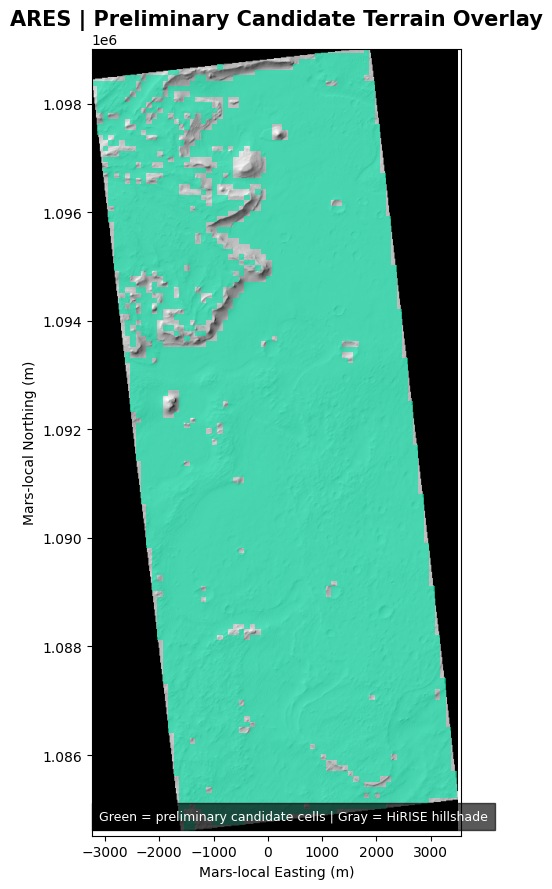

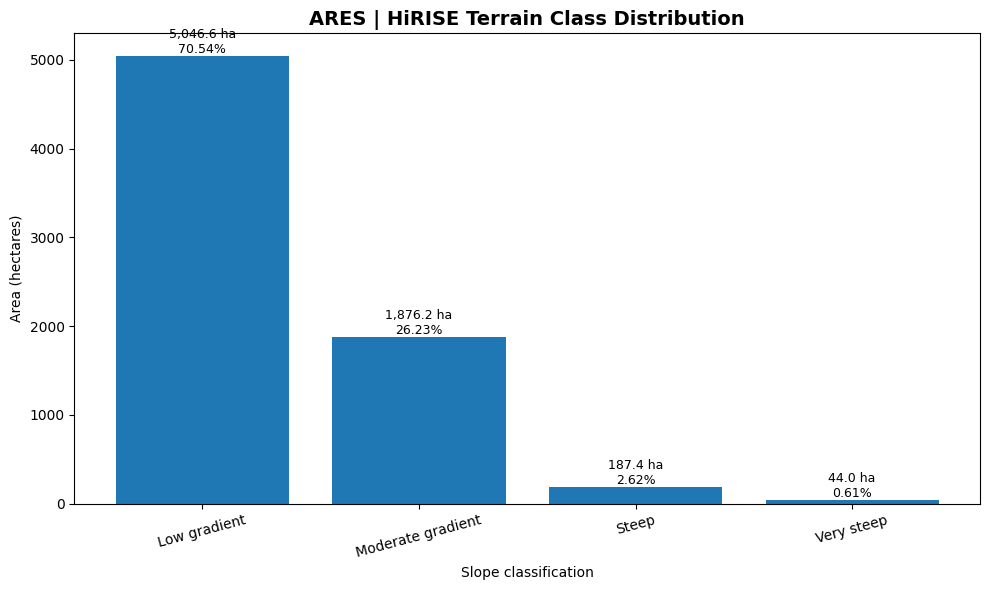


TABLE 1 | TERRAIN CLASS STATISTICS


,Class,Terrain,Slope Range,Pixels,Area (ha),Area (km²),Share (%)
0,1,Low gradient,0–5°,49504773,5046.616,50.46616,70.541
1,2,Moderate gradient,>5–15°,18404505,1876.192,18.76192,26.225
2,3,Steep,>15–25°,1838054,187.375,1.87375,2.619
3,4,Very steep,>25°,431448,43.983,0.43983,0.615



TABLE 2 | CONNECTIVITY ROBUSTNESS


,Connectivity,Regions,Largest Region (cells),Largest Region (%)
0,8-directional,4,6517,99.923
1,4-directional,14,6505,99.739



ARES VISUALIZATION SUMMARY
Candidate cells: 6,522
Largest 8-directional region: 99.92%
Largest 4-directional region: 99.74%

SAVED VISUALS
/kaggle/working/ares_data/ares_candidate_corridor_map.png
/kaggle/working/ares_data/ares_terrain_distribution.png

ARES visual assessment complete.


In [17]:
import os
import json
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from rasterio.enums import Resampling
from matplotlib.colors import ListedColormap

DATA_DIR = "/kaggle/working/ares_data"

HILLSHADE_PATH = os.path.join(DATA_DIR, "hirise_hillshade.tif")
CANDIDATE_PATH = os.path.join(DATA_DIR, "ares_corridor_candidates.tif")

TERRAIN_REPORT = os.path.join(DATA_DIR, "terrain_screening_report.json")
CONNECTIVITY_REPORT = os.path.join(
    DATA_DIR, "connectivity_robustness_report.json"
)

MAP_OUTPUT = os.path.join(DATA_DIR, "ares_candidate_corridor_map.png")
CHART_OUTPUT = os.path.join(DATA_DIR, "ares_terrain_distribution.png")

print("=" * 70)
print("ARES | TERRAIN AND CORRIDOR VISUALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# LOAD REPORTS
# ------------------------------------------------------------

with open(TERRAIN_REPORT) as f:
    terrain = json.load(f)

with open(CONNECTIVITY_REPORT) as f:
    connectivity = json.load(f)

# ------------------------------------------------------------
# LOAD AND DOWNSAMPLE HILLSHADE FOR DISPLAY
# ------------------------------------------------------------

with rasterio.open(HILLSHADE_PATH) as src:

    display_height = 1000
    scale = display_height / src.height
    display_width = max(1, int(src.width * scale))

    hillshade = src.read(
        1,
        out_shape=(display_height, display_width),
        resampling=Resampling.average
    )

    hillshade_bounds = src.bounds

# ------------------------------------------------------------
# LOAD CANDIDATE GRID
# ------------------------------------------------------------

with rasterio.open(CANDIDATE_PATH) as src:

    candidate_grid = src.read(1)
    candidate_bounds = src.bounds

candidate_overlay = np.ma.masked_where(
    candidate_grid != 1,
    candidate_grid
)

# ------------------------------------------------------------
# FIGURE 1: SPATIAL CANDIDATE OVERLAY
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 9))

ax.imshow(
    hillshade,
    cmap="gray",
    extent=[
        hillshade_bounds.left,
        hillshade_bounds.right,
        hillshade_bounds.bottom,
        hillshade_bounds.top
    ],
    origin="upper"
)

overlay = ax.imshow(
    candidate_overlay,
    cmap=ListedColormap(["#00E5A8"]),
    alpha=0.62,
    extent=[
        candidate_bounds.left,
        candidate_bounds.right,
        candidate_bounds.bottom,
        candidate_bounds.top
    ],
    origin="upper",
    interpolation="nearest"
)

ax.set_title(
    "ARES | Preliminary Candidate Terrain Overlay",
    fontsize=15,
    weight="bold"
)
ax.set_xlabel("Mars-local Easting (m)")
ax.set_ylabel("Mars-local Northing (m)")

ax.text(
    0.02, 0.02,
    "Green = preliminary candidate cells | Gray = HiRISE hillshade",
    transform=ax.transAxes,
    fontsize=9,
    color="white",
    bbox=dict(facecolor="black", alpha=0.65, pad=5)
)

plt.tight_layout()
plt.savefig(MAP_OUTPUT, dpi=220, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# FIGURE 2: TERRAIN CLASS AREA DISTRIBUTION
# ------------------------------------------------------------

classes = terrain["classes"]

class_names = [item["name"] for item in classes]
class_areas = [item["area_hectares"] for item in classes]
class_percentages = [
    item["percent_of_valid_area"] for item in classes
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    class_names,
    class_areas
)

ax.set_title(
    "ARES | HiRISE Terrain Class Distribution",
    fontsize=14,
    weight="bold"
)
ax.set_ylabel("Area (hectares)")
ax.set_xlabel("Slope classification")
ax.tick_params(axis="x", rotation=15)

for bar, area, percent in zip(
    bars, class_areas, class_percentages
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{area:,.1f} ha\n{percent:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.savefig(CHART_OUTPUT, dpi=220, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# TABLE 1: TERRAIN CLASS STATISTICS
# ------------------------------------------------------------

terrain_table = pd.DataFrame([
    {
        "Class": item["class"],
        "Terrain": item["name"],
        "Slope Range": item["range"],
        "Pixels": item["pixels"],
        "Area (ha)": item["area_hectares"],
        "Area (km²)": item["area_km2"],
        "Share (%)": item["percent_of_valid_area"]
    }
    for item in classes
])

print("\nTABLE 1 | TERRAIN CLASS STATISTICS")
display(terrain_table)

# ------------------------------------------------------------
# TABLE 2: CONNECTIVITY ROBUSTNESS
# ------------------------------------------------------------

connectivity_table = pd.DataFrame([
    {
        "Connectivity": "8-directional",
        "Regions": connectivity["eight_directional"]["component_count"],
        "Largest Region (cells)": connectivity["eight_directional"]["largest_cells"],
        "Largest Region (%)": connectivity["eight_directional"]["largest_share_percent"]
    },
    {
        "Connectivity": "4-directional",
        "Regions": connectivity["four_directional"]["component_count"],
        "Largest Region (cells)": connectivity["four_directional"]["largest_cells"],
        "Largest Region (%)": connectivity["four_directional"]["largest_share_percent"]
    }
])

print("\nTABLE 2 | CONNECTIVITY ROBUSTNESS")
display(connectivity_table)

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

candidate_cells = int(np.count_nonzero(candidate_grid == 1))

print("\nARES VISUALIZATION SUMMARY")
print(f"Candidate cells: {candidate_cells:,}")
print(
    "Largest 8-directional region: "
    f"{connectivity['eight_directional']['largest_share_percent']:.2f}%"
)
print(
    "Largest 4-directional region: "
    f"{connectivity['four_directional']['largest_share_percent']:.2f}%"
)

print("\nSAVED VISUALS")
print(MAP_OUTPUT)
print(CHART_OUTPUT)

print("\nARES visual assessment complete.")

### Key takeaways from Part 3 _(values from the validated run)_
- **71.54 km²** of valid HiRISE terrain mapped at ~1 m; **70.5 %** is low gradient (0–5°), **26.2 %** moderate, **2.6 %** steep, **0.6 %** very steep (>25°).
- Of **7,039** 100 m cells with enough data, **6,522 (92.7 %)** pass the screening; **99.9 %** of them form one connected region (99.7 % even without diagonal moves).
- **Honest reading:** a plain slope cut-off passes most of this study area, so it does not discriminate between routes. That is exactly why Part 5 uses a **continuous cost surface** and an explicit EVA budget instead of a pass/fail mask.


---
# PART 4 — The spectral layer: NASA CRISM
CRISM measures reflected light in many wavelengths, and its **summary parameters** flag minerals worth a closer look. ARES finds the observations over the site, validates the product, applies the **instrument's own quality mask**, registers it to the terrain grid and compares it with the terrain screening. CRISM has ~36 m pixels, so it is geological **context**, not a 1 m mineral map.


### Step 10 — CRISM Mineralogical Data Discovery

Search NASA's Mars Orbital Data Explorer for CRISM Map-projected Targeted Reduced Data Records (MTRDR).

Search bounds encompass the HiRISE Jezero study footprint:
- Longitude: 77°E–78°E
- Latitude: 18°N–19°N

Retrieve product identifiers, available image files, and product metadata.

This is a coverage-discovery step. No mineral identification will be claimed until an appropriate product is downloaded, inspected, and spatially registered.

In [18]:
import os
import json
import requests
import pandas as pd
from IPython.display import display

DATA_DIR = "/kaggle/working/ares_data"

JSON_PATH = os.path.join(
    DATA_DIR, "crism_jezero_product_discovery.json"
)

TABLE_PATH = os.path.join(
    DATA_DIR, "crism_jezero_product_inventory.csv"
)

API_URL = "https://oderest.rsl.wustl.edu/live2/"

params = {
    "query": "product",
    "results": "fp",
    "output": "JSON",
    "limit": 100,
    "target": "mars",
    "ihid": "MRO",
    "iid": "CRISM",
    "pt": "MTRDR",
    "westlon": 77,
    "eastlon": 78,
    "minlat": 18,
    "maxlat": 19
}

print("=" * 70)
print("ARES | CRISM JEZERO PRODUCT DISCOVERY")
print("=" * 70)

response = requests.get(
    API_URL,
    params=params,
    timeout=120
)

response.raise_for_status()
data = response.json()

products_container = (
    data.get("ODEResults", {})
        .get("Products", {})
        .get("Product", [])
)

if isinstance(products_container, dict):
    products_container = [products_container]

records = []

for product in products_container:

    product_id = product.get("pdsid", "Unknown")

    product_files = (
        product.get("Product_files", {})
              .get("Product_file", [])
    )

    if isinstance(product_files, dict):
        product_files = [product_files]

    image_files = []
    label_files = []
    header_files = []

    for file_info in product_files:

        url = file_info.get("URL", "")

        if not url:
            continue

        lower_url = url.lower()

        if lower_url.endswith(".img"):
            image_files.append(url)
        elif lower_url.endswith((".lbl", ".xml")):
            label_files.append(url)
        elif lower_url.endswith(".hdr"):
            header_files.append(url)

    records.append({
        "Product ID": product_id,
        "Image Files": len(image_files),
        "Label/XML Files": len(label_files),
        "Header Files": len(header_files),
        "Image URLs": image_files,
        "Label URLs": label_files,
        "Header URLs": header_files
    })

# Save the original discovery response for reproducibility.
with open(JSON_PATH, "w") as f:
    json.dump(data, f, indent=2)

print("\nSEARCH BOUNDS")
print("Longitude: 77°E to 78°E")
print("Latitude: 18°N to 19°N")
print("Instrument: MRO CRISM")
print("Product type: MTRDR")

print("\nPRODUCT DISCOVERY")

if records:

    table = pd.DataFrame([
        {
            "Product ID": r["Product ID"],
            "Image Files": r["Image Files"],
            "Label/XML Files": r["Label/XML Files"],
            "Header Files": r["Header Files"]
        }
        for r in records
    ])

    display(table)

    table.to_csv(TABLE_PATH, index=False)

    print(f"\nProducts returned: {len(records)}")

    print("\nAVAILABLE IMAGE FILES")

    for record in records:
        print(f"\n{record['Product ID']}")

        for url in record["Image URLs"]:
            print(url)

    print("\nAVAILABLE LABEL FILES")

    for record in records:
        for url in record["Label URLs"]:
            print(url)

else:

    print("No CRISM MTRDR products returned for these search bounds.")
    print("Inspect the saved response and consider alternate product coverage.")

print("\nOUTPUT")
print(JSON_PATH)

if records:
    print(TABLE_PATH)

print("\nARES CRISM discovery complete.")

ARES | CRISM JEZERO PRODUCT DISCOVERY

SEARCH BOUNDS
Longitude: 77°E to 78°E
Latitude: 18°N to 19°N
Instrument: MRO CRISM
Product type: MTRDR

PRODUCT DISCOVERY


,Product ID,Image Files,Label/XML Files,Header Files
0,hrl000040ff_07_if183j_mtr3,23,48,23
1,frt000047a3_07_if166j_mtr3,23,48,23
2,frt00005850_07_if167j_mtr3,23,48,23
3,frt00005c5e_07_if166j_mtr3,23,48,23
4,frt000066a4_07_if166j_mtr3,23,48,23
5,hrl00010963_07_if183j_mtr3,23,48,23
6,hrl000116c6_07_if183j_mtr3,23,48,23
7,frt0001182a_07_if165j_mtr3,23,48,23
8,frt000161ef_07_if167j_mtr3,23,48,23
9,frt00017b1b_07_if166j_mtr3,23,48,23



Products returned: 15

AVAILABLE IMAGE FILES

hrl000040ff_07_if183j_mtr3
https://pds-geosciences.wustl.edu/mro/mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/browse/2007/2007_029/hrl000040ff/hrl000040ff_07_brcarj_mtr3.img
https://pds-geosciences.wustl.edu/mro/mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/browse/2007/2007_029/hrl000040ff/hrl000040ff_07_brchlj_mtr3.img
https://pds-geosciences.wustl.edu/mro/mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/browse/2007/2007_029/hrl000040ff/hrl000040ff_07_brcr2j_mtr3.img
https://pds-geosciences.wustl.edu/mro/mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/browse/2007/2007_029/hrl000040ff/hrl000040ff_07_brfalj_mtr3.img
https://pds-geosciences.wustl.edu/mro/mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/browse/2007/2007_029/hrl000040ff/hrl000040ff_07_brfemj_mtr3.img
https://pds-geosciences.wustl.edu/mro/mro-m-crism-5-rdr-mptargeted-v1/mrocr_4001/browse/2007/2007_029/hrl000040ff/hrl000040ff_07_brfm2j_mtr3.img
https://pds-geosciences.wustl.edu/mro/mro-m-crism-5-rdr-

### Step 11 — CRISM Data Layer — Coverage and Product Assessment

Investigate Compact Reconnaissance Imaging Spectrometer for Mars (CRISM)
observations covering the ARES Jezero study area.

Objective:
- Identify CRISM observations overlapping the HiRISE DTM footprint.
- Verify product identifiers and geographic coverage.
- Prefer calibrated or map-projected products suitable for spatial analysis.
- Record product metadata and limitations before downloading.

CRISM mineralogical observations provide scientific context. They do not directly establish terrain safety or traversability.

In [19]:
import os
import json
import requests
import pandas as pd

DATA_DIR = "/kaggle/working/ares_data"
os.makedirs(DATA_DIR, exist_ok=True)

OUTPUT_JSON = os.path.join(DATA_DIR, "crism_coverage_search.json")
OUTPUT_CSV = os.path.join(DATA_DIR, "crism_coverage_products.csv")

# ARES HiRISE footprint, expanded slightly for product discovery.
SEARCH_BOUNDS = {
    "westlon": 77.35,
    "eastlon": 77.55,
    "minlat": 18.28,
    "maxlat": 18.58
}

API_URL = "https://oderest.rsl.wustl.edu/live2/"

params = {
    "query": "product",
    "results": "fp",
    "output": "JSON",
    "limit": 100,
    "target": "mars",
    "ihid": "MRO",
    "iid": "CRISM",
    "pt": "MTRDR",
    **SEARCH_BOUNDS
}

print("=" * 68)
print("ARES | CRISM COVERAGE SEARCH")
print("=" * 68)

response = requests.get(
    API_URL,
    params=params,
    timeout=120
)

print("\nHTTP STATUS:", response.status_code)
response.raise_for_status()

data = response.json()

# Save the complete response for reproducibility.
with open(OUTPUT_JSON, "w") as f:
    json.dump(data, f, indent=2)

# ------------------------------------------------------------
# EXTRACT PRODUCTS FROM ODE RESPONSE
# ------------------------------------------------------------

products_container = (
    data.get("ODEResults", {})
        .get("Products", {})
        .get("Product", [])
)

if isinstance(products_container, dict):
    products_container = [products_container]

records = []

for product in products_container:

    if not isinstance(product, dict):
        continue

    product_id = (
        product.get("pdsid")
        or product.get("PDSID")
        or product.get("product_id")
        or product.get("Product_ID")
        or "Unknown"
    )

    files_container = product.get("Product_files", {})
    files = files_container.get("Product_file", [])

    if isinstance(files, dict):
        files = [files]

    image_files = []
    available_files = []

    for file_info in files:

        if not isinstance(file_info, dict):
            continue

        file_url = file_info.get("URL") or file_info.get("url")

        if file_url:
            available_files.append(file_url)

            if file_url.lower().endswith(
                (".img", ".cub", ".tif", ".tiff")
            ):
                image_files.append(file_url)

    records.append({
        "product_id": product_id,
        "image_file_count": len(image_files),
        "image_files": "; ".join(image_files),
        "available_file_count": len(available_files),
        "available_files": "; ".join(available_files)
    })

# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("\nSEARCH BOUNDS")
for key, value in SEARCH_BOUNDS.items():
    print(f"{key}: {value}")

print("\nPRODUCT DISCOVERY")

if records:

    products_df = pd.DataFrame(records)

    display(products_df[[
        "product_id",
        "image_file_count",
        "available_file_count"
    ]])

    products_df.to_csv(OUTPUT_CSV, index=False)

    print(f"\nProducts returned: {len(products_df)}")
    print("Image files listed:", products_df["image_file_count"].sum())

else:

    print("No products were extracted from the expected response field.")
    print("Inspecting response structure:")

    print(json.dumps(data, indent=2)[:10000])

# ------------------------------------------------------------
# SAVE SEARCH METADATA
# ------------------------------------------------------------

summary = {
    "project": "ARES",
    "instrument": "CRISM",
    "product_type": "MTRDR",
    "search_bounds": SEARCH_BOUNDS,
    "products_returned": len(records),
    "source_api": API_URL,
    "response_file": OUTPUT_JSON,
    "product_table": OUTPUT_CSV if records else None
}

with open(
    os.path.join(DATA_DIR, "crism_search_summary.json"), "w"
) as f:
    json.dump(summary, f, indent=2)

print("\nSAVED FILES")
print(OUTPUT_JSON)

if records:
    print(OUTPUT_CSV)

print(os.path.join(DATA_DIR, "crism_search_summary.json"))

print("\nARES CRISM coverage search complete.")

ARES | CRISM COVERAGE SEARCH

HTTP STATUS: 200

SEARCH BOUNDS
westlon: 77.35
eastlon: 77.55
minlat: 18.28
maxlat: 18.58

PRODUCT DISCOVERY


,product_id,image_file_count,available_file_count
0,hrl000040ff_07_if183j_mtr3,23,119
1,frt000047a3_07_if166j_mtr3,23,119
2,frt00005850_07_if167j_mtr3,23,119
3,frt00005c5e_07_if166j_mtr3,23,119
4,frt000066a4_07_if166j_mtr3,23,119
5,frt0001fb74_07_if166j_mtr3,23,119
6,frt00021da6_07_if166j_mtr3,23,119



Products returned: 7
Image files listed: 161

SAVED FILES
/kaggle/working/ares_data/crism_coverage_search.json
/kaggle/working/ares_data/crism_coverage_products.csv
/kaggle/working/ares_data/crism_search_summary.json

ARES CRISM coverage search complete.


### Step 12 — CRISM Product Labels — Geographic Footprint Recovery

Retrieve the small PDS label files associated with the seven discovered
CRISM MTRDR products.

Extract available geographic metadata, including:
- Corner latitude and longitude
- Minimum and maximum latitude and longitude
- Map projection information
- Product identifiers

The labels will be inspected before any hyperspectral data are downloaded.

A product will only be considered spatially overlapping after its
geographic coverage has been verified.

,product_id,label_status,label_filename,label_bytes
0,hrl000040ff_07_if183j_mtr3,Downloaded,HRL000040FF_07_IF183J_MTR3.XML,14988
1,frt000047a3_07_if166j_mtr3,Downloaded,FRT000047A3_07_IF166J_MTR3.XML,14989
2,frt00005850_07_if167j_mtr3,Downloaded,FRT00005850_07_IF167J_MTR3.XML,14992
3,frt00005c5e_07_if166j_mtr3,Downloaded,FRT00005C5E_07_IF166J_MTR3.XML,14989
4,frt000066a4_07_if166j_mtr3,Downloaded,FRT000066A4_07_IF166J_MTR3.XML,14992
5,frt0001fb74_07_if166j_mtr3,Downloaded,FRT0001FB74_07_IF166J_MTR3.XML,14992
6,frt00021da6_07_if166j_mtr3,Downloaded,FRT00021DA6_07_IF166J_MTR3.XML,14985


ARES | CRISM LABEL COORDINATE INSPECTION

PRODUCT: hrl000040ff_07_if183j_mtr3
STATUS: Downloaded
<solar_longitude unit="deg">174.791242</solar_longitude>
<geom:minimum_latitude unit="deg">18.2767400</geom:minimum_latitude>
<geom:maximum_latitude unit="deg">18.7324270</geom:maximum_latitude>
<geom:minimum_longitude unit="deg">77.27556</geom:minimum_longitude>
<geom:maximum_longitude unit="deg">77.561134</geom:maximum_longitude>
<cart:Map_Projection>
<cart:map_projection_name>Equirectangular</cart:map_projection_name>
<cart:latitude_of_projection_origin unit="deg">0</cart:latitude_of_projection_origin>
<cart:longitude_of_central_meridian unit="deg">0</cart:longitude_of_central_meridian>
</cart:Map_Projection>
<cart:upperleft_corner_x unit="m">4422596.1999984</cart:upperleft_corner_x>
<cart:upperleft_corner_y unit="m">1109971.5000012</cart:upperleft_corner_y>
<cart:latitude_type>Planetocentric</cart:latitude_type>
<cart:longitude_direction>Positive East</cart:longitude_direction>

PRODUCT

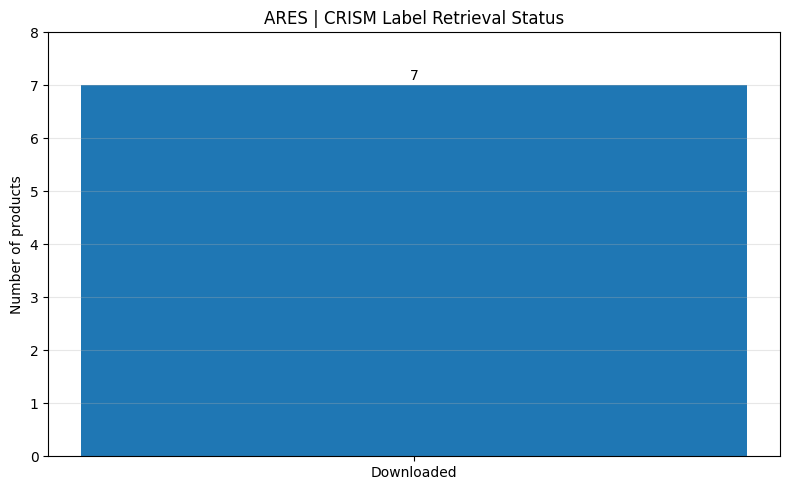


Saved label inspection: /kaggle/working/ares_data/crism_label_inspection.csv
Saved visualization: /kaggle/working/ares_data/ares_crism_label_retrieval.png
Label files directory: /kaggle/working/ares_data/crism_labels


In [20]:
import os
import re
import json
import requests
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "/kaggle/working/ares_data"
JSON_PATH = os.path.join(DATA_DIR, "crism_coverage_search.json")

LABEL_DIR = os.path.join(DATA_DIR, "crism_labels")
os.makedirs(LABEL_DIR, exist_ok=True)

with open(JSON_PATH, "r") as f:
    raw = json.load(f)

products = (
    raw.get("ODEResults", {})
       .get("Products", {})
       .get("Product", [])
)

if isinstance(products, dict):
    products = [products]

# ------------------------------------------------------------
# FIND AND DOWNLOAD PRODUCT LABELS
# ------------------------------------------------------------

session = requests.Session()
records = []

coordinate_pattern = re.compile(
    r"(LATITUDE|LONGITUDE|CORNER|WESTERNMOST|EASTERNMOST|"
    r"NORTHERNMOST|SOUTHERNMOST|MINIMUM_LATITUDE|"
    r"MAXIMUM_LATITUDE|MINIMUM_LONGITUDE|MAXIMUM_LONGITUDE|"
    r"MAP_PROJECTION|CENTER_LATITUDE|CENTER_LONGITUDE)",
    re.IGNORECASE
)

for product in products:

    product_id = product.get("pdsid", "unknown")

    label_name = product.get("LabelFileName", "")
    files = product.get("Product_files", {}).get("Product_file", [])

    if isinstance(files, dict):
        files = [files]

    label_entry = None

    # Prefer the exact label filename supplied by ODE.
    for item in files:
        filename = item.get("FileName", "")
        if label_name and filename.lower() == label_name.lower():
            label_entry = item
            break

    # Fallback: locate a label file by extension.
    if label_entry is None:
        for item in files:
            filename = item.get("FileName", "")
            if filename.lower().endswith(".lbl"):
                label_entry = item
                break

    if label_entry is None:
        records.append({
            "product_id": product_id,
            "label_status": "No label URL found",
            "coordinate_lines": ""
        })
        continue

    url = label_entry.get("URL")
    filename = label_entry.get("FileName") or f"{product_id}.lbl"

    if not url:
        records.append({
            "product_id": product_id,
            "label_status": "No URL",
            "coordinate_lines": ""
        })
        continue

    local_path = os.path.join(LABEL_DIR, os.path.basename(filename))

    try:
        response = session.get(url, timeout=90)
        response.raise_for_status()

        with open(local_path, "wb") as f:
            f.write(response.content)

        text = response.content.decode("utf-8", errors="replace")

        matching_lines = [
            line.strip()
            for line in text.splitlines()
            if coordinate_pattern.search(line)
        ]

        records.append({
            "product_id": product_id,
            "label_status": "Downloaded",
            "label_filename": os.path.basename(filename),
            "label_bytes": len(response.content),
            "coordinate_lines": "\n".join(matching_lines),
            "local_path": local_path
        })

    except Exception as exc:
        records.append({
            "product_id": product_id,
            "label_status": f"Download failed: {exc}",
            "coordinate_lines": ""
        })

# ------------------------------------------------------------
# PRINT LABEL INSPECTION TABLE
# ------------------------------------------------------------

labels_df = pd.DataFrame(records)

display(labels_df[[
    "product_id",
    "label_status",
    "label_filename",
    "label_bytes"
]].fillna(""))

print("=" * 68)
print("ARES | CRISM LABEL COORDINATE INSPECTION")
print("=" * 68)

for record in records:
    print("\nPRODUCT:", record["product_id"])
    print("STATUS:", record["label_status"])
    print(record.get("coordinate_lines") or
          "No matching geographic coordinate lines found.")

# ------------------------------------------------------------
# VISUALIZE LABEL RETRIEVAL STATUS
# ------------------------------------------------------------

status_counts = labels_df["label_status"].apply(
    lambda x: "Downloaded" if x == "Downloaded" else "Unavailable"
).value_counts()

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    status_counts.index,
    status_counts.values
)

ax.set_title("ARES | CRISM Label Retrieval Status")
ax.set_ylabel("Number of products")
ax.set_ylim(0, max(1, len(products)) + 1)
ax.grid(axis="y", alpha=0.3)

for i, value in enumerate(status_counts.values):
    ax.text(i, value + 0.1, str(value), ha="center")

plt.tight_layout()

plot_path = os.path.join(
    DATA_DIR,
    "ares_crism_label_retrieval.png"
)

plt.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

csv_path = os.path.join(
    DATA_DIR,
    "crism_label_inspection.csv"
)

labels_df.to_csv(csv_path, index=False)

print("\nSaved label inspection:", csv_path)
print("Saved visualization:", plot_path)
print("Label files directory:", LABEL_DIR)

### Step 13 — CRISM Observation Coverage versus HiRISE

Compare the geographic bounding boxes of all seven CRISM MTRDR
observations with the ARES HiRISE study area.

The visualization displays:
- HiRISE study-area boundary
- CRISM observation bounding boxes
- Bounding-box overlap status
- Approximate percentage of the HiRISE bounding rectangle covered
  by each CRISM bounding rectangle

Important: Bounding-box overlap is not proof of exact pixel-level
coverage. The map is a preliminary spatial screening result.

ARES | CRISM–HIRISE SPATIAL OVERLAP


,product_id,bbox_overlap,approx_study_bbox_overlap_percent
0,frt000047a3_07_if166j_mtr3,True,43.43
1,frt00005850_07_if167j_mtr3,True,50.87
2,frt00005c5e_07_if166j_mtr3,True,75.57
3,frt000066a4_07_if166j_mtr3,True,22.96
4,frt0001fb74_07_if166j_mtr3,True,74.04
5,frt00021da6_07_if166j_mtr3,False,0.00
6,hrl000040ff_07_if183j_mtr3,True,100.00



CRISM products inspected: 7
Bounding-box overlaps: 6
No bounding-box overlap: 1


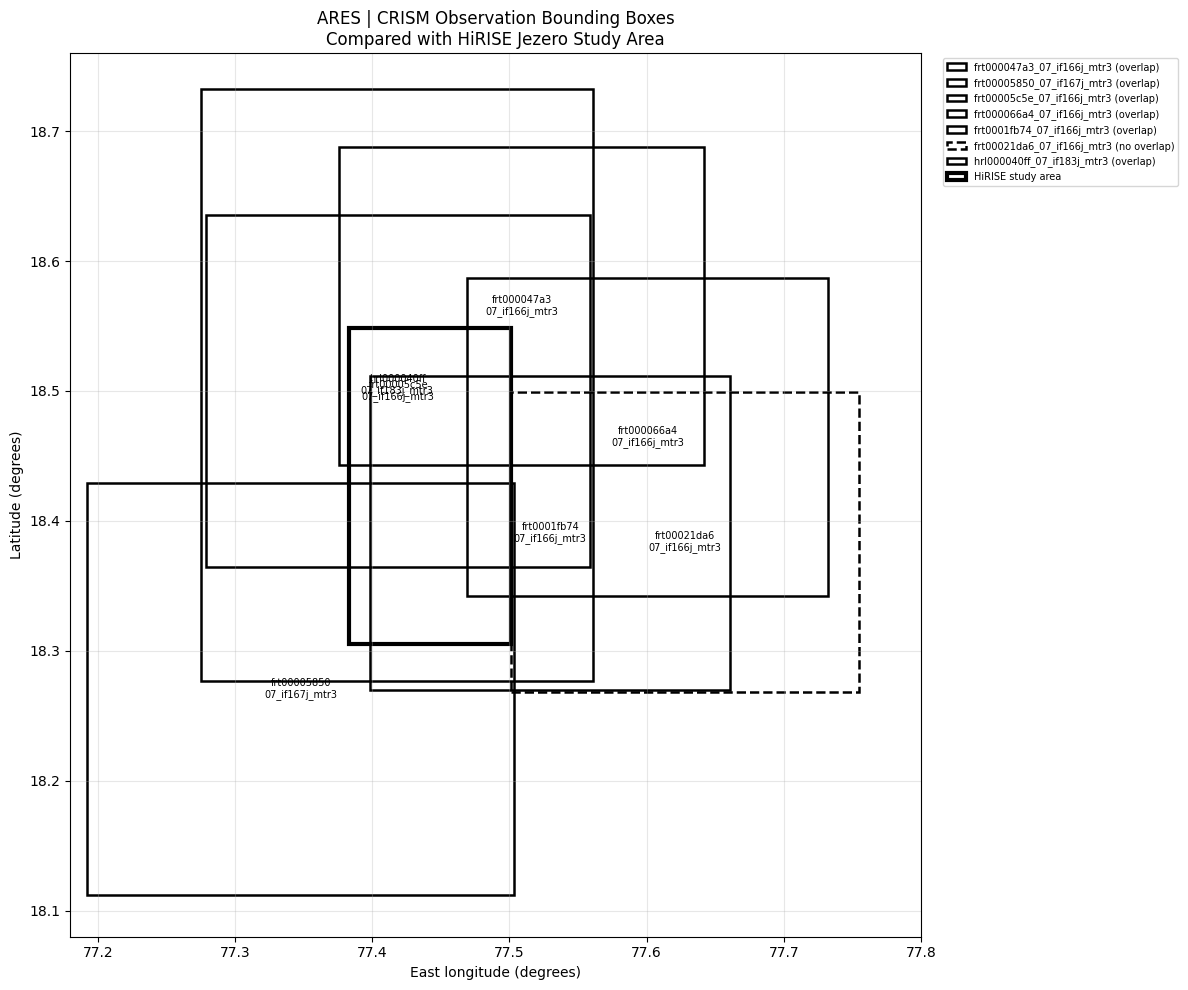


Coverage map saved: /kaggle/working/ares_data/ares_crism_hirise_coverage_map.png
Overlap table saved: /kaggle/working/ares_data/crism_hirise_overlap_table.csv

ARES CRISM spatial screening complete.


In [21]:
import os
import re
import xml.etree.ElementTree as ET
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

DATA_DIR = "/kaggle/working/ares_data"
LABEL_DIR = os.path.join(DATA_DIR, "crism_labels")

# HiRISE study-area bounds from the project metadata.
H = {
    "west": 77.3833804,
    "east": 77.50109494,
    "south": 18.30529355,
    "north": 18.54839110
}

def local_tag(tag):
    return tag.split("}")[-1].split(":")[-1].lower()

def extract_coordinates(xml_path):
    root = ET.parse(xml_path).getroot()
    values = {}

    wanted = {
        "minimum_latitude": "south",
        "maximum_latitude": "north",
        "minimum_longitude": "west",
        "maximum_longitude": "east"
    }

    for element in root.iter():
        tag = local_tag(element.tag)

        if tag in wanted and element.text:
            values[wanted[tag]] = float(element.text.strip())

    if len(values) != 4:
        return None

    return values

# ------------------------------------------------------------
# READ ALL CRISM LABELS
# ------------------------------------------------------------

records = []

for filename in sorted(os.listdir(LABEL_DIR)):

    if not filename.lower().endswith((".xml", ".lbl")):
        continue

    path = os.path.join(LABEL_DIR, filename)
    bounds = extract_coordinates(path)

    if bounds is None:
        continue

    product_id = os.path.splitext(filename)[0].lower()

    west = max(H["west"], bounds["west"])
    east = min(H["east"], bounds["east"])
    south = max(H["south"], bounds["south"])
    north = min(H["north"], bounds["north"])

    overlap = east > west and north > south

    study_area_deg2 = (
        (H["east"] - H["west"]) *
        (H["north"] - H["south"])
    )

    overlap_deg2 = (
        (east - west) * (north - south)
        if overlap else 0
    )

    overlap_share = (
        100 * overlap_deg2 / study_area_deg2
        if overlap else 0
    )

    records.append({
        "product_id": product_id,
        **bounds,
        "bbox_overlap": overlap,
        "approx_study_bbox_overlap_percent": overlap_share
    })

df = pd.DataFrame(records)

# ------------------------------------------------------------
# PRINT SPATIAL OVERLAP TABLE
# ------------------------------------------------------------

print("=" * 72)
print("ARES | CRISM–HIRISE SPATIAL OVERLAP")
print("=" * 72)

display(df[[
    "product_id",
    "bbox_overlap",
    "approx_study_bbox_overlap_percent"
]].round(2))

print("\nCRISM products inspected:", len(df))
print("Bounding-box overlaps:", int(df["bbox_overlap"].sum()))
print("No bounding-box overlap:", int((~df["bbox_overlap"]).sum()))

# ------------------------------------------------------------
# DRAW COVERAGE MAP
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 10))

# Draw CRISM observation bounding boxes.
for _, row in df.iterrows():

    rect = Rectangle(
        (row["west"], row["south"]),
        row["east"] - row["west"],
        row["north"] - row["south"],
        fill=False,
        linewidth=1.8,
        linestyle="-" if row["bbox_overlap"] else "--",
        label=(
            f"{row['product_id']} "
            f"({'overlap' if row['bbox_overlap'] else 'no overlap'})"
        )
    )

    ax.add_patch(rect)

    ax.text(
        (row["west"] + row["east"]) / 2,
        (row["south"] + row["north"]) / 2,
        row["product_id"].replace("_07_if", "\n07_if"),
        fontsize=7,
        ha="center",
        va="center"
    )

# Draw HiRISE study-area boundary.
hirise_rect = Rectangle(
    (H["west"], H["south"]),
    H["east"] - H["west"],
    H["north"] - H["south"],
    fill=False,
    edgecolor="black",
    linewidth=3,
    label="HiRISE study area"
)

ax.add_patch(hirise_rect)

ax.set_xlim(77.18, 77.80)
ax.set_ylim(18.08, 18.76)

ax.set_xlabel("East longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.set_title(
    "ARES | CRISM Observation Bounding Boxes\n"
    "Compared with HiRISE Jezero Study Area"
)

ax.grid(alpha=0.3)
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=7
)

plt.tight_layout()

map_path = os.path.join(
    DATA_DIR,
    "ares_crism_hirise_coverage_map.png"
)

plt.savefig(map_path, dpi=200, bbox_inches="tight")
plt.show()

print("\nCoverage map saved:", map_path)

# ------------------------------------------------------------
# SAVE SPATIAL SCREENING TABLE
# ------------------------------------------------------------

table_path = os.path.join(
    DATA_DIR,
    "crism_hirise_overlap_table.csv"
)

df.to_csv(table_path, index=False)

print("Overlap table saved:", table_path)
print("\nARES CRISM spatial screening complete.")

### Step 14 — CRISM Science Product Selection

Inspect the available files for the CRISM observation with the strongest
preliminary bounding-box match to the HiRISE study area.

Selected candidate:
hrl000040ff_07_if183j_mtr3

Identify:
- Mineralogical summary parameter products
- Browse images and map products
- Calibrated spectral data files
- Product labels and metadata

Rank candidate files for further inspection.

Selection is preliminary and based on bounding-box overlap, not
confirmed pixel-level coverage.

ARES | SELECTED CRISM PRODUCT FILE INVENTORY
Selected product: hrl000040ff_07_if183j_mtr3
Files listed: 119


,filename,category,file_type,size_kb
0,HRL000040FF_07_BRCARJ_MTR3.HDR,Mineralogy / summary,Browse,2
1,HRL000040FF_07_BRCARJ_MTR3.IMG,Mineralogy / summary,Browse,1026
2,HRL000040FF_07_BRCARJ_MTR3.LBL,Mineralogy / summary,Browse,8
3,HRL000040FF_07_BRCARJ_MTR3.PNG,Mineralogy / summary,Browse,381
4,HRL000040FF_07_BRCARJ_MTR3.XML,Mineralogy / summary,Browse,17
...,...,...,...,...
114,HRL000040FF_07_IF183J_MTR3_XML.ZIP,Other,Derived,9
115,HRL000040FF_07_IN183J_MTR3.HDR,Other,Product,2
116,HRL000040FF_07_IN183J_MTR3.IMG,Other,Product,12302
117,HRL000040FF_07_WV183J_MTR3.TAB,Other,Product,15


,category,file_count,total_size_kb
0,Browse / preview,57,6360210268430172102684431721026845717210268414...
1,Metadata / label,8,72971572358
2,Mineralogy / summary,43,2102683811721026833016210268236172102685051721...
3,Other,11,219136156683754392123021520


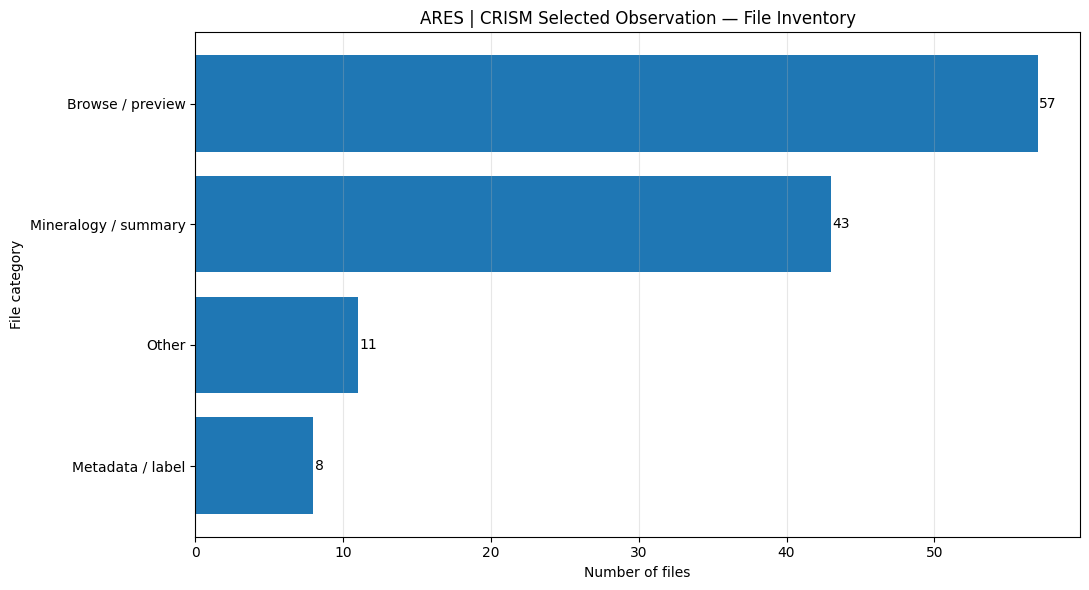


Saved inventory: /kaggle/working/ares_data/crism_selected_product_inventory.csv
Saved visualization: /kaggle/working/ares_data/ares_crism_selected_file_inventory.png

MINERALOGY / SUMMARY FILE CANDIDATES


,filename,file_type,size_kb,description
0,HRL000040FF_07_BRCARJ_MTR3.HDR,Browse,2,CARBONATES BROWSE ENVI HEADER
1,HRL000040FF_07_BRCARJ_MTR3.IMG,Browse,1026,CARBONATES BROWSE PDS IMAGE
2,HRL000040FF_07_BRCARJ_MTR3.LBL,Browse,8,CARBONATES BROWSE PDS3 LABEL
3,HRL000040FF_07_BRCARJ_MTR3.PNG,Browse,381,CARBONATES BROWSE QUICKLOOK
4,HRL000040FF_07_BRCARJ_MTR3.XML,Browse,17,CARBONATES BROWSE PDS4 LABEL
5,HRL000040FF_07_BRCR2J_MTR3.HDR,Browse,2,VERSION 2 CARBONATES BROWSE ENVI HEADER
6,HRL000040FF_07_BRCR2J_MTR3.IMG,Browse,1026,VERSION 2 CARBONATES BROWSE PDS IMAGE
7,HRL000040FF_07_BRCR2J_MTR3.LBL,Browse,8,VERSION 2 CARBONATES BROWSE PDS3 LABEL
8,HRL000040FF_07_BRCR2J_MTR3.PNG,Browse,330,VERSION 2 CARBONATES BROWSE QUICKLOOK
9,HRL000040FF_07_BRCR2J_MTR3.XML,Browse,16,VERSION 2 CARBONATES BROWSE PDS4 LABEL



ARES CRISM product inspection complete.


In [22]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "/kaggle/working/ares_data"
JSON_PATH = os.path.join(DATA_DIR, "crism_coverage_search.json")

SELECTED_PRODUCT = "hrl000040ff_07_if183j_mtr3"

with open(JSON_PATH, "r") as f:
    raw = json.load(f)

products = (
    raw.get("ODEResults", {})
       .get("Products", {})
       .get("Product", [])
)

if isinstance(products, dict):
    products = [products]

selected = next(
    (
        p for p in products
        if p.get("pdsid", "").lower() == SELECTED_PRODUCT
    ),
    None
)

if selected is None:
    raise ValueError(
        f"Selected product not found: {SELECTED_PRODUCT}"
    )

files = selected.get("Product_files", {}).get("Product_file", [])

if isinstance(files, dict):
    files = [files]

records = []

for item in files:

    filename = item.get("FileName", "")
    description = item.get("Description", "")
    file_type = item.get("Type", "")
    url = item.get("URL", "")
    size_kb = item.get("KBytes", None)

    text = (
        str(filename) + " " +
        str(description) + " " +
        str(file_type)
    ).lower()

    if any(term in text for term in [
        "summary", "parameter", "phyllosilicate",
        "carbonate", "hydrated", "ferric",
        "olivine", "spectral index"
    ]):
        category = "Mineralogy / summary"

    elif any(term in text for term in [
        "browse", "quicklook", "thumbnail", "preview"
    ]):
        category = "Browse / preview"

    elif any(term in text for term in [
        "trdr", "mtrdr", "hyperspectral", "spectral cube"
    ]):
        category = "Spectral data"

    elif filename.lower().endswith((".xml", ".lbl")):
        category = "Metadata / label"

    elif filename.lower().endswith((".png", ".jpg", ".jpeg")):
        category = "Image"

    else:
        category = "Other"

    records.append({
        "filename": filename,
        "category": category,
        "file_type": file_type,
        "size_kb": size_kb,
        "description": description,
        "url": url
    })

df = pd.DataFrame(records)

# ------------------------------------------------------------
# RANK FILES FOR SCIENTIFIC INSPECTION
# ------------------------------------------------------------

priority = {
    "Mineralogy / summary": 1,
    "Browse / preview": 2,
    "Spectral data": 3,
    "Image": 4,
    "Metadata / label": 5,
    "Other": 6
}

df["inspection_priority"] = df["category"].map(priority)

df = df.sort_values(
    ["inspection_priority", "filename"]
).reset_index(drop=True)

print("=" * 72)
print("ARES | SELECTED CRISM PRODUCT FILE INVENTORY")
print("=" * 72)

print("Selected product:", SELECTED_PRODUCT)
print("Files listed:", len(df))

display(df[[
    "filename",
    "category",
    "file_type",
    "size_kb"
]].fillna(""))

# ------------------------------------------------------------
# CATEGORY SUMMARY TABLE
# ------------------------------------------------------------

category_summary = (
    df.groupby("category")
      .agg(
          file_count=("filename", "count"),
          total_size_kb=("size_kb", "sum")
      )
      .reset_index()
)

display(category_summary)

# ------------------------------------------------------------
# VISUALIZATION: FILE INVENTORY BY CATEGORY
# ------------------------------------------------------------

plot_df = category_summary.sort_values(
    "file_count",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    plot_df["category"],
    plot_df["file_count"]
)

ax.set_title(
    "ARES | CRISM Selected Observation — File Inventory"
)
ax.set_xlabel("Number of files")
ax.set_ylabel("File category")
ax.grid(axis="x", alpha=0.3)

for i, value in enumerate(plot_df["file_count"]):
    ax.text(value + 0.1, i, str(value), va="center")

plt.tight_layout()

plot_path = os.path.join(
    DATA_DIR,
    "ares_crism_selected_file_inventory.png"
)

plt.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# SAVE INVENTORY
# ------------------------------------------------------------

csv_path = os.path.join(
    DATA_DIR,
    "crism_selected_product_inventory.csv"
)

df.to_csv(csv_path, index=False)

print("\nSaved inventory:", csv_path)
print("Saved visualization:", plot_path)

print("\nMINERALOGY / SUMMARY FILE CANDIDATES")

candidates = df[
    df["category"] == "Mineralogy / summary"
]

if len(candidates):
    display(candidates[[
        "filename",
        "file_type",
        "size_kb",
        "description"
    ]].fillna(""))
else:
    print(
        "No files were identified by the initial filename/description "
        "classification. We will inspect the full file list."
    )

print("\nARES CRISM product inspection complete.")

### Step 15 — CRISM Spectral Summary Product Validation

Inspect the SR (Refined Spectral Summary Parameters) and SU
(Spectral Summary Parameters) products for the selected CRISM observation.

Retrieve only the metadata files:
- ENVI headers (.HDR)
- PDS3 labels (.LBL)
- PDS4 labels (.XML)

Validate the product structure, dimensions, data type, band count,
and geospatial metadata before downloading or interpreting image data.

No mineralogical conclusions are made at this stage.

ARES | CRISM SR/SU METADATA FILES


,filename,file_type,size_kb_numeric,url
35,HRL000040FF_07_SR183J_MTR3.HDR,Product,2,https://pds-geosciences.wustl.edu/mro/mro-m-cr...
37,HRL000040FF_07_SR183J_MTR3.LBL,Product,9,https://pds-geosciences.wustl.edu/mro/mro-m-cr...
38,HRL000040FF_07_SR183J_MTR3.XML,Product,67,https://pds-geosciences.wustl.edu/mro/mro-m-cr...
39,HRL000040FF_07_SU183J_MTR3.HDR,Product,2,https://pds-geosciences.wustl.edu/mro/mro-m-cr...
41,HRL000040FF_07_SU183J_MTR3.LBL,Product,9,https://pds-geosciences.wustl.edu/mro/mro-m-cr...
42,HRL000040FF_07_SU183J_MTR3.XML,Product,67,https://pds-geosciences.wustl.edu/mro/mro-m-cr...



METADATA DOWNLOAD RESULTS


,filename,status,bytes
0,HRL000040FF_07_SR183J_MTR3.HDR,Downloaded,1802
1,HRL000040FF_07_SR183J_MTR3.LBL,Downloaded,8394
2,HRL000040FF_07_SR183J_MTR3.XML,Downloaded,66697
3,HRL000040FF_07_SU183J_MTR3.HDR,Downloaded,1802
4,HRL000040FF_07_SU183J_MTR3.LBL,Downloaded,8386
5,HRL000040FF_07_SU183J_MTR3.XML,Downloaded,66689



ARES | CRISM PRODUCT METADATA CONTENT

------------------------------------------------------------------------
HRL000040FF_07_SR183J_MTR3.HDR
------------------------------------------------------------------------
samples = 455
lines   = 751
bands   = 60
header offset = 0
data type = 4
interleave = bsq
byte order = 0
map info = {MRO Mars Equirectangular [IAU 2000] [15.00N; 0.00E], 1.0000, 1.0000, 4422632.2000, 1109935.5000, 3.6000000000e+01, 3.6000000000e+01, D_Mars_2000_IAU_IAG_custom_sphere_lat15, units=Meters}
coordinate system string = {PROJCS["MRO Mars Equirectangular [IAU 2000] [15.00N; 0.00E]",GEOGCS["GCS_Mars_2000_IAU_IAG_custom_sphere_lat15",DATUM["D_Mars_2000_IAU_IAG_custom_sphere_lat15",SPHEROID["Mars_2000_IAU_IAG_custom_sphere_lat15",3394839.813316312,0.0]],PRIMEM["Reference_Meridian",0.0],UNIT["Degree",0.0174532925199433]],PROJECTION["Equidistant_Cylindrical"],PARAMETER["False_Easting",0.0],PARAMETER["False_Northing",0.0],PARAMETER["Central_Meridian",0.0],PARAMETER["Sta

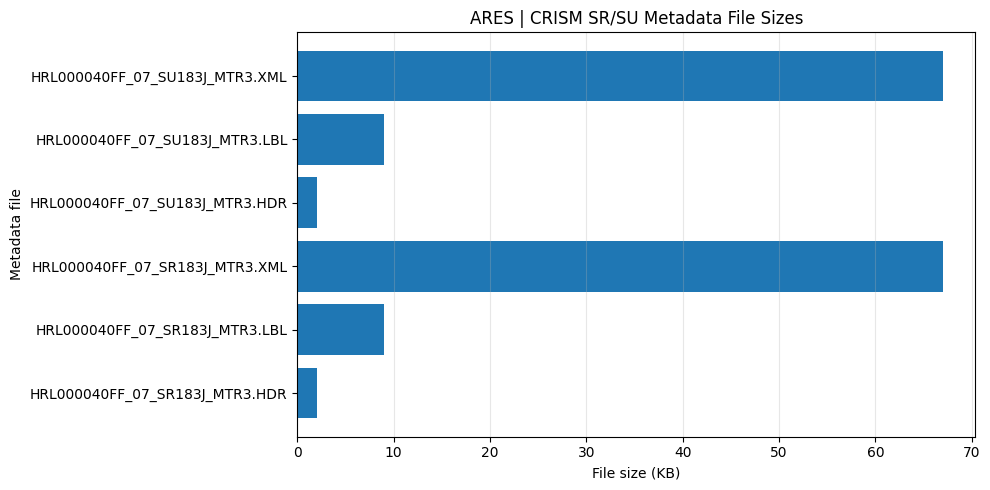


Saved metadata directory: /kaggle/working/ares_data/crism_science_metadata
Saved download record: /kaggle/working/ares_data/crism_sr_su_metadata_downloads.csv
Saved visualization: /kaggle/working/ares_data/ares_crism_sr_su_metadata_inventory.png

ARES SR/SU metadata inspection complete.


In [23]:
import os
import re
import requests
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "/kaggle/working/ares_data"
CSV_PATH = os.path.join(
    DATA_DIR,
    "crism_selected_product_inventory.csv"
)

META_DIR = os.path.join(DATA_DIR, "crism_science_metadata")
os.makedirs(META_DIR, exist_ok=True)

df = pd.read_csv(CSV_PATH)

# Correctly treat file sizes as numeric.
df["size_kb_numeric"] = pd.to_numeric(
    df["size_kb"],
    errors="coerce"
)

# ------------------------------------------------------------
# SELECT SR AND SU PRODUCT METADATA
# ------------------------------------------------------------

targets = [
    "HRL000040FF_07_SR183J_MTR3",
    "HRL000040FF_07_SU183J_MTR3"
]

selected = df[
    df["filename"].str.upper().apply(
        lambda name: any(
            name.startswith(target) for target in targets
        )
    )
].copy()

selected = selected[
    selected["filename"].str.upper().str.endswith(
        (".HDR", ".LBL", ".XML")
    )
]

print("=" * 72)
print("ARES | CRISM SR/SU METADATA FILES")
print("=" * 72)

display(selected[[
    "filename",
    "file_type",
    "size_kb_numeric",
    "url"
]].fillna(""))

if selected.empty:
    raise RuntimeError(
        "No SR/SU metadata files were found in the saved inventory."
    )

# ------------------------------------------------------------
# DOWNLOAD AND SAVE METADATA
# ------------------------------------------------------------

download_records = []

for _, row in selected.iterrows():

    filename = str(row["filename"])
    url = str(row["url"]).strip()

    if not url.startswith("http"):
        download_records.append({
            "filename": filename,
            "status": "Missing or invalid URL",
            "bytes": 0
        })
        continue

    destination = os.path.join(META_DIR, filename)

    try:
        response = requests.get(
            url,
            timeout=90
        )
        response.raise_for_status()

        with open(destination, "wb") as f:
            f.write(response.content)

        download_records.append({
            "filename": filename,
            "status": "Downloaded",
            "bytes": len(response.content)
        })

    except Exception as exc:
        download_records.append({
            "filename": filename,
            "status": f"FAILED: {str(exc)[:160]}",
            "bytes": 0
        })

download_df = pd.DataFrame(download_records)

print("\nMETADATA DOWNLOAD RESULTS")
display(download_df)

# ------------------------------------------------------------
# INSPECT ENVI HEADERS AND PDS LABELS
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("ARES | CRISM PRODUCT METADATA CONTENT")
print("=" * 72)

for filename in sorted(os.listdir(META_DIR)):

    path = os.path.join(META_DIR, filename)

    if not filename.upper().endswith((".HDR", ".LBL", ".XML")):
        continue

    print("\n" + "-" * 72)
    print(filename)
    print("-" * 72)

    try:
        with open(path, "r", encoding="utf-8", errors="replace") as f:
            content = f.read()

        lines = content.splitlines()

        if filename.upper().endswith(".HDR"):
            # ENVI header: print structural and map-related fields.
            keywords = (
                "samples",
                "lines",
                "bands",
                "data type",
                "interleave",
                "byte order",
                "header offset",
                "map info",
                "coordinate system",
                "data ignore value",
                "band names",
                "wavelength"
            )

            matches = [
                line for line in lines
                if any(
                    key in line.lower()
                    for key in keywords
                )
            ]

            print("\n".join(matches[:35]))

        else:
            # PDS labels: print product, band, and map metadata.
            keywords = (
                "logical_identifier",
                "product_id",
                "product_type",
                "record_bytes",
                "lines",
                "line_samples",
                "sample_bits",
                "sample_type",
                "axis_name",
                "elements",
                "band",
                "map_projection",
                "map_scale",
                "latitude",
                "longitude",
                "description"
            )

            matches = [
                line for line in lines
                if any(
                    key in line.lower()
                    for key in keywords
                )
            ]

            print("\n".join(matches[:55]))

    except Exception as exc:
        print("Could not inspect file:", exc)

# ------------------------------------------------------------
# VISUALIZATION: PRODUCT FILE SIZE
# ------------------------------------------------------------

plot_df = selected.copy()
plot_df["size_kb_numeric"] = pd.to_numeric(
    plot_df["size_kb_numeric"],
    errors="coerce"
).fillna(0)

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    plot_df["filename"],
    plot_df["size_kb_numeric"]
)

ax.set_title("ARES | CRISM SR/SU Metadata File Sizes")
ax.set_xlabel("File size (KB)")
ax.set_ylabel("Metadata file")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

plot_path = os.path.join(
    DATA_DIR,
    "ares_crism_sr_su_metadata_inventory.png"
)

plt.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# SAVE VALIDATION RECORD
# ------------------------------------------------------------

download_csv = os.path.join(
    DATA_DIR,
    "crism_sr_su_metadata_downloads.csv"
)

download_df.to_csv(download_csv, index=False)

print("\nSaved metadata directory:", META_DIR)
print("Saved download record:", download_csv)
print("Saved visualization:", plot_path)
print("\nARES SR/SU metadata inspection complete.")

### Step 16 — CRISM Spectral Band Name Recovery

Extract the multiline band-name definitions from both
ENVI headers and PDS3 labels.

Compare SR and SU band names by index, identify missing entries,
and save a complete band inventory.

Band names are metadata identifiers; their scientific meanings
will be checked before any mineralogical interpretation.

ARES | CRISM BAND NAME RECOVERY


,product,declared_bands,ENVI_names_found,PDS3_names_found,selected_name_source,selected_names
0,SR,60,0,60,PDS3 LBL,60
1,SU,60,0,60,PDS3 LBL,60



COMPLETE INDEXED BAND INVENTORY


,band_index_1based,SR_band_name,SU_band_name,names_match
0,1,R770,R770,True
1,2,RBR,RBR,True
2,3,BD530_2,BD530_2,True
3,4,SH600_2,SH600_2,True
4,5,SH770,SH770,True
5,6,BD640_2,BD640_2,True
6,7,BD860_2,BD860_2,True
7,8,BD920_2,BD920_2,True
8,9,RPEAK1,RPEAK1,True
9,10,BDI1000VIS,BDI1000VIS,True



SR/SU names identical: True
SR names recovered: 60
SU names recovered: 60
Declared bands accounted for: 60 / 60


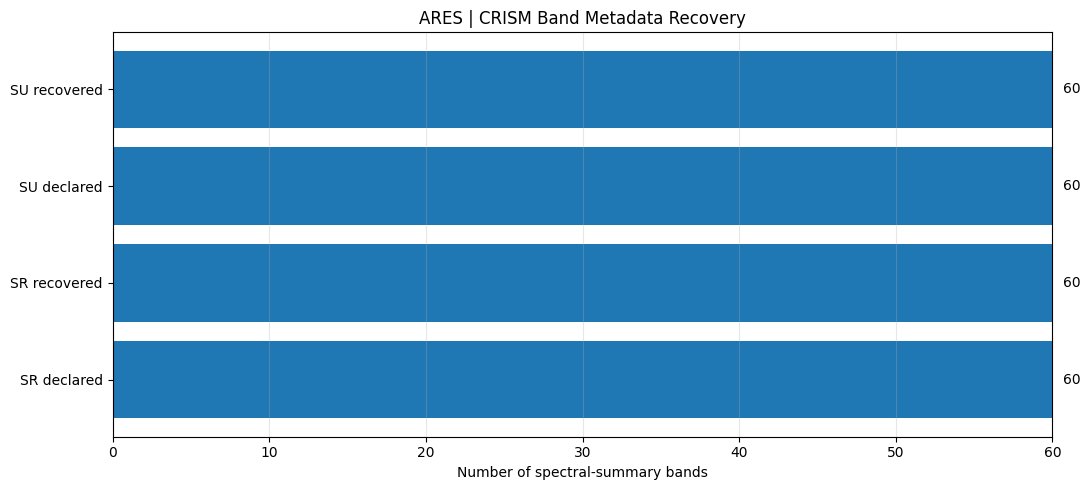


Saved band inventory: /kaggle/working/ares_data/crism_spectral_band_inventory.csv
Saved diagnostics: /kaggle/working/ares_data/crism_band_metadata_diagnostics.csv
Saved visualization: /kaggle/working/ares_data/ares_crism_band_metadata_recovery.png

ARES band-name recovery complete.


In [25]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "/kaggle/working/ares_data"
META_DIR = os.path.join(DATA_DIR, "crism_science_metadata")

PRODUCTS = ["SR", "SU"]

def read_text(path):
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        return f.read()

def extract_envi_names(text):
    match = re.search(
        r"band\s*names\s*=\s*\{(.*?)\}",
        text,
        flags=re.IGNORECASE | re.DOTALL
    )
    if not match:
        return []

    return re.findall(r'"([^"]+)"', match.group(1))

def extract_pds_names(text):
    match = re.search(
        r"BAND_NAME\s*=\s*\((.*?)\)",
        text,
        flags=re.IGNORECASE | re.DOTALL
    )
    if not match:
        return []

    return re.findall(r'"([^"]+)"', match.group(1))

results = {}
diagnostics = []

for product in PRODUCTS:
    prefix = f"HRL000040FF_07_{product}183J_MTR3"

    hdr_path = os.path.join(META_DIR, prefix + ".HDR")
    lbl_path = os.path.join(META_DIR, prefix + ".LBL")

    hdr_text = read_text(hdr_path)
    lbl_text = read_text(lbl_path)

    hdr_names = extract_envi_names(hdr_text)
    lbl_names = extract_pds_names(lbl_text)

    # Prefer ENVI header names; use PDS label names if necessary.
    names = hdr_names if hdr_names else lbl_names
    source = (
        "ENVI HDR" if hdr_names
        else "PDS3 LBL" if lbl_names
        else "Not recovered"
    )

    results[product] = names

    diagnostics.append({
        "product": product,
        "declared_bands": 60,
        "ENVI_names_found": len(hdr_names),
        "PDS3_names_found": len(lbl_names),
        "selected_name_source": source,
        "selected_names": len(names)
    })

    if not names:
        print(f"\n{product}: band names were not recovered.")
        print("ENVI header band-name excerpt:")
        for line in hdr_text.splitlines():
            if "band names" in line.lower():
                print(line[:500])
        print("PDS label band-name excerpt:")
        for line in lbl_text.splitlines():
            if "band_name" in line.lower():
                print(line[:500])

# ------------------------------------------------------------
# BUILD INDEXED BAND INVENTORY
# ------------------------------------------------------------

max_count = max(
    [len(results[p]) for p in PRODUCTS] + [0]
)

rows = []

for i in range(max_count):
    sr_name = results["SR"][i] if i < len(results["SR"]) else None
    su_name = results["SU"][i] if i < len(results["SU"]) else None

    rows.append({
        "band_index_1based": i + 1,
        "SR_band_name": sr_name,
        "SU_band_name": su_name,
        "names_match": sr_name == su_name
    })

band_df = pd.DataFrame(rows)
diagnostic_df = pd.DataFrame(diagnostics)

print("=" * 72)
print("ARES | CRISM BAND NAME RECOVERY")
print("=" * 72)

display(diagnostic_df)

if not band_df.empty:
    print("\nCOMPLETE INDEXED BAND INVENTORY")
    display(band_df)

    print("\nSR/SU names identical:",
          results["SR"] == results["SU"])

    print("SR names recovered:", len(results["SR"]))
    print("SU names recovered:", len(results["SU"]))

    print(
        "Declared bands accounted for:",
        max_count, "/ 60"
    )
else:
    print(
        "No band names were recovered. "
        "Do not proceed to band interpretation yet."
    )

# ------------------------------------------------------------
# VISUALIZATION
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 5))

labels = ["SR declared", "SR recovered", "SU declared", "SU recovered"]
values = [
    60,
    len(results["SR"]),
    60,
    len(results["SU"])
]

ax.barh(labels, values)
ax.set_xlim(0, 60)
ax.set_xlabel("Number of spectral-summary bands")
ax.set_title("ARES | CRISM Band Metadata Recovery")
ax.grid(axis="x", alpha=0.3)

for i, value in enumerate(values):
    ax.text(value + 0.7, i, str(value), va="center")

plt.tight_layout()

plot_path = os.path.join(
    DATA_DIR,
    "ares_crism_band_metadata_recovery.png"
)
plt.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# SAVE OUTPUTS
# ------------------------------------------------------------

band_csv = os.path.join(
    DATA_DIR,
    "crism_spectral_band_inventory.csv"
)

diagnostic_csv = os.path.join(
    DATA_DIR,
    "crism_band_metadata_diagnostics.csv"
)

band_df.to_csv(band_csv, index=False)
diagnostic_df.to_csv(diagnostic_csv, index=False)

print("\nSaved band inventory:", band_csv)
print("Saved diagnostics:", diagnostic_csv)
print("Saved visualization:", plot_path)
print("\nARES band-name recovery complete.")

### Step 17 — CRISM Refined Spectral Summary Data

Download the 60-band CRISM SR image for the selected observation.

Validate:
- Raster dimensions and band count
- Floating-point data type and NoData value
- Map projection and pixel spacing
- Valid-data coverage and per-band statistics

Visualize selected spectral summary parameters relevant to
carbonates, hydrated minerals, phyllosilicates, and mafic minerals.

These parameter maps are exploratory spectral indicators,
not confirmed mineral detections.

Download complete.
Image size (MB): 82.01

ARES | CRISM SR DATA VALIDATION
Width: 455
Height: 751
Bands: 60
Data type: float32
NoData: 65535.0
CRS: PROJCS["MRO Mars Equirectangular [IAU 2000] [15.00N; 0.00E]",GEOGCS["GCS_Mars_2000_IAU_IAG_custom_sphere_lat15",DATUM["D_Mars_2000_IAU_IAG_custom_sphere_lat15",SPHEROID["Mars_2000_IAU_IAG_custom_sphere_lat15",3394839.81331631,0]],PRIMEM["Reference_Meridian",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",15],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Transform: | 36.00,-0.00, 4422632.20|
|-0.00,-36.00, 1109935.50|
| 0.00, 0.00, 1.00|
Pixel spacing (m): 36.0 36.0

Valid pixel coverage:
220,978 / 341,705 (64.67%)

COMPLETE SR BAND STATISTICS


,band_index,parameter,valid_pixels,valid_percent,minimum,median,mean,maximum
0,1,R770,220978,64.6692,0.1309,0.1850,0.1850,0.2553
1,2,RBR,220978,64.6692,2.7458,3.3396,3.3405,4.1560
2,3,BD530_2,220978,64.6692,0.1162,0.1584,0.1587,0.2060
3,4,SH600_2,220978,64.6692,0.1191,0.1607,0.1606,0.1808
4,5,SH770,220978,64.6692,-0.0374,0.0127,0.0126,0.0280
5,6,BD640_2,220978,64.6692,-0.0734,-0.0552,-0.0552,-0.0212
6,7,BD860_2,220978,64.6692,-0.0260,-0.0096,-0.0093,0.0698
7,8,BD920_2,220978,64.6692,-0.0160,0.0004,0.0004,0.0196
8,9,RPEAK1,220978,64.6692,0.7080,0.7264,0.7264,0.7514
9,10,BDI1000VIS,220978,64.6692,0.0124,0.0214,0.0214,0.0317



SELECTED MINERALOGICAL INDICATOR STATISTICS


,band_index,parameter,valid_pixels,valid_percent,minimum,median,mean,maximum
13,14,OLINDEX3,220978,64.6692,-0.0110,0.1246,0.1254,0.2634
16,17,LCPINDEX2,220978,64.6692,-0.0999,-0.0395,-0.0412,0.0346
17,18,HCPINDEX2,220978,64.6692,-0.0462,-0.0094,-0.0096,0.0277
25,26,BD1900_2,220978,64.6692,-0.0114,0.0063,0.0070,0.0340
27,28,BDI2000,220978,64.6692,-0.0286,-0.0065,-0.0068,0.0109
28,29,BD2100_2,220978,64.6692,-0.0346,-0.0061,-0.0068,0.0128
31,32,MIN2200,220978,64.6692,-0.0126,0.0005,0.0003,0.0102
33,34,D2200,220978,64.6692,-0.0059,0.0054,0.0056,0.0201
36,37,MIN2250,220978,64.6692,-0.0046,0.0033,0.0034,0.0132
39,40,D2300,220978,64.6692,-0.0114,0.0071,0.0077,0.0338


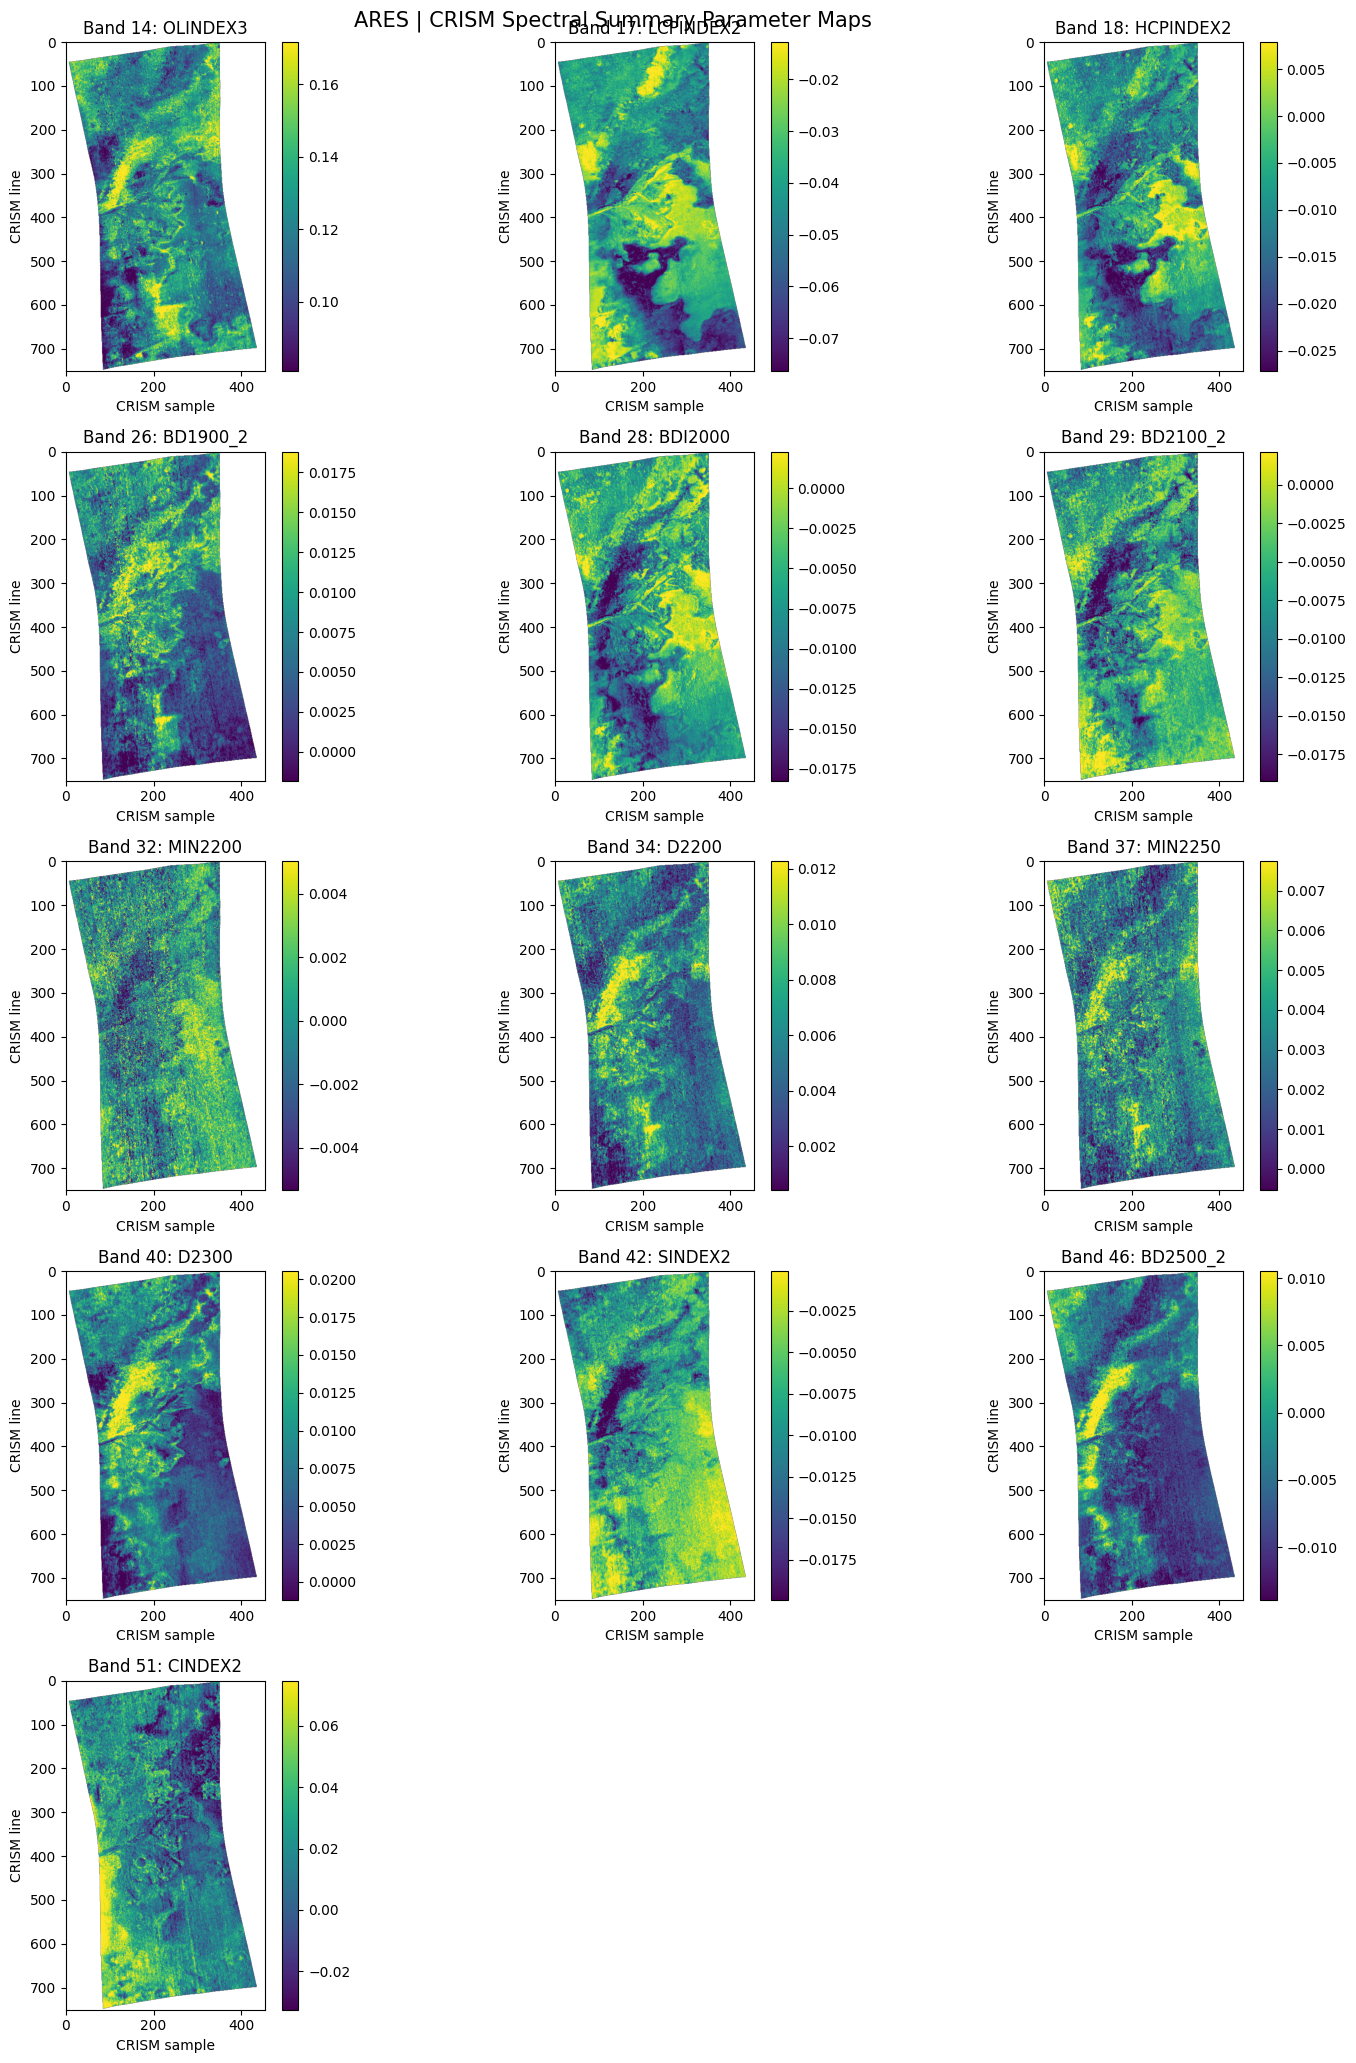


Saved CRISM SR image: /kaggle/working/ares_data/crism_data/HRL000040FF_07_SR183J_MTR3.IMG
Saved band statistics: /kaggle/working/ares_data/crism_sr_band_statistics.csv
Saved parameter maps: /kaggle/working/ares_data/ares_crism_sr_parameter_maps.png

ARES CRISM SR validation complete.


In [26]:
import os
import shutil
import requests
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

DATA_DIR = "/kaggle/working/ares_data"
META_DIR = os.path.join(DATA_DIR, "crism_science_metadata")
CRISM_DIR = os.path.join(DATA_DIR, "crism_data")

os.makedirs(CRISM_DIR, exist_ok=True)

PRODUCT = "HRL000040FF_07_SR183J_MTR3"
IMAGE_NAME = PRODUCT + ".IMG"
HEADER_NAME = PRODUCT + ".HDR"

inventory = pd.read_csv(
    os.path.join(DATA_DIR, "crism_selected_product_inventory.csv")
)

match = inventory[
    inventory["filename"].str.upper() == IMAGE_NAME
]

if match.empty:
    raise FileNotFoundError(
        f"{IMAGE_NAME} was not found in the product inventory."
    )

image_url = str(match.iloc[0]["url"]).strip()

if not image_url.startswith("http"):
    raise ValueError("CRISM image URL is missing or invalid.")

image_path = os.path.join(CRISM_DIR, IMAGE_NAME)
header_source = os.path.join(META_DIR, HEADER_NAME)
header_path = os.path.join(CRISM_DIR, HEADER_NAME)

# ------------------------------------------------------------
# DOWNLOAD SR IMAGE
# ------------------------------------------------------------

if not os.path.exists(image_path):
    print("Downloading CRISM SR image...")
    response = requests.get(image_url, timeout=180)
    response.raise_for_status()

    with open(image_path, "wb") as f:
        f.write(response.content)

    print("Download complete.")
else:
    print("Existing CRISM SR image found; reusing it.")

if not os.path.exists(header_source):
    raise FileNotFoundError(
        "The SR ENVI header is missing. Rerun metadata retrieval."
    )

shutil.copy2(header_source, header_path)

print("Image size (MB):", round(os.path.getsize(image_path) / 1e6, 2))

# ------------------------------------------------------------
# OPEN AND VALIDATE RASTER
# ------------------------------------------------------------

with rasterio.open(image_path) as src:

    cube = src.read().astype(np.float32)

    profile = src.profile.copy()
    transform = src.transform
    crs = src.crs
    nodata = src.nodata

    print("\n" + "=" * 72)
    print("ARES | CRISM SR DATA VALIDATION")
    print("=" * 72)

    print("Width:", src.width)
    print("Height:", src.height)
    print("Bands:", src.count)
    print("Data type:", src.dtypes[0])
    print("NoData:", nodata)
    print("CRS:", crs)
    print("Transform:", transform)
    print("Pixel spacing (m):", abs(transform.a), abs(transform.e))

if cube.shape != (60, 751, 455):
    raise ValueError(
        f"Unexpected SR cube dimensions: {cube.shape}"
    )

# ------------------------------------------------------------
# VALID-DATA MASK AND BAND DEFINITIONS
# ------------------------------------------------------------

band_inventory = pd.read_csv(
    os.path.join(DATA_DIR, "crism_spectral_band_inventory.csv")
)

if len(band_inventory) != 60:
    raise ValueError("Expected 60 recovered band definitions.")

band_names = band_inventory["SR_band_name"].tolist()

# Valid pixel must have finite values and not be NoData
valid_cube = np.isfinite(cube)

if nodata is not None:
    valid_cube &= cube != nodata

# A pixel is considered valid for this summary if at least
# 80% of its 60 bands contain usable values.
valid_pixel = valid_cube.mean(axis=0) >= 0.80

print("\nValid pixel coverage:")
print(
    f"{valid_pixel.sum():,} / {valid_pixel.size:,} "
    f"({100 * valid_pixel.mean():.2f}%)"
)

# ------------------------------------------------------------
# PER-BAND STATISTICS
# ------------------------------------------------------------

stats = []

for index, name in enumerate(band_names):

    band = cube[index]
    mask = valid_cube[index] & valid_pixel

    values = band[mask]

    if values.size:
        stats.append({
            "band_index": index + 1,
            "parameter": name,
            "valid_pixels": int(values.size),
            "valid_percent": 100 * values.size / valid_pixel.size,
            "minimum": float(np.min(values)),
            "median": float(np.median(values)),
            "mean": float(np.mean(values)),
            "maximum": float(np.max(values))
        })
    else:
        stats.append({
            "band_index": index + 1,
            "parameter": name,
            "valid_pixels": 0,
            "valid_percent": 0,
            "minimum": np.nan,
            "median": np.nan,
            "mean": np.nan,
            "maximum": np.nan
        })

stats_df = pd.DataFrame(stats)

print("\nCOMPLETE SR BAND STATISTICS")
display(stats_df.round(4))

# ------------------------------------------------------------
# SELECT SCIENTIFICALLY RELEVANT PARAMETERS
# ------------------------------------------------------------

selected_parameters = [
    "OLINDEX3",
    "LCPINDEX2",
    "HCPINDEX2",
    "BD1900_2",
    "BDI2000",
    "BD2100_2",
    "MIN2200",
    "D2200",
    "MIN2250",
    "D2300",
    "SINDEX2",
    "BD2500_2",
    "CINDEX2"
]

selected_indices = [
    band_names.index(name)
    for name in selected_parameters
    if name in band_names
]

if not selected_indices:
    raise RuntimeError("None of the selected parameters were found.")

# ------------------------------------------------------------
# PRINT SELECTED PARAMETER STATISTICS
# ------------------------------------------------------------

selected_stats = stats_df[
    stats_df["parameter"].isin(selected_parameters)
].copy()

print("\nSELECTED MINERALOGICAL INDICATOR STATISTICS")
display(selected_stats.round(4))

# ------------------------------------------------------------
# VISUALIZE PARAMETER MAPS
# ------------------------------------------------------------

n = len(selected_indices)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(15, rows * 4.2)
)

axes = np.asarray(axes).reshape(-1)

for ax, index in zip(axes, selected_indices):

    name = band_names[index]
    image = cube[index].copy()

    image[~valid_cube[index]] = np.nan
    image[~valid_pixel] = np.nan

    finite = image[np.isfinite(image)]

    if finite.size:
        vmin, vmax = np.nanpercentile(
            finite, [2, 98]
        )
    else:
        vmin, vmax = 0, 1

    im = ax.imshow(
        image,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(f"Band {index + 1}: {name}")
    ax.set_xlabel("CRISM sample")
    ax.set_ylabel("CRISM line")

    fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

for ax in axes[n:]:
    ax.axis("off")

fig.suptitle(
    "ARES | CRISM Spectral Summary Parameter Maps",
    fontsize=15
)

plt.tight_layout()

map_path = os.path.join(
    DATA_DIR,
    "ares_crism_sr_parameter_maps.png"
)

plt.savefig(map_path, dpi=180, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# SAVE OUTPUTS
# ------------------------------------------------------------

stats_path = os.path.join(
    DATA_DIR,
    "crism_sr_band_statistics.csv"
)

stats_df.to_csv(stats_path, index=False)

print("\nSaved CRISM SR image:", image_path)
print("Saved band statistics:", stats_path)
print("Saved parameter maps:", map_path)

print("\nARES CRISM SR validation complete.")

### Step 18 — CRISM–HiRISE Spatial Registration

Transform the CRISM SR raster from its Mars equirectangular
projection centered at 0°E into the HiRISE local projection
centered at 77.44°E.

Use the shared Mars reference radius and 15° standard parallel
to calculate the east-west coordinate translation.

Then:
- Compare the transformed CRISM footprint with the HiRISE DTM.
- Count CRISM pixel centers inside the HiRISE study bounds.
- Quantify valid CRISM coverage within those bounds.
- Overlay selected spectral parameters on the HiRISE hillshade.

CRISM remains at its native 36 m resolution. The overlay is not
a 1 m mineralogical map and does not establish mineral presence.

ARES | CRISM–HIRISE SPATIAL REGISTRATION
Mars reference radius: 3394839.813316312 m
Standard parallel: 15.0 degrees
CRISM central meridian: 0.0 degrees
HiRISE central meridian: 77.44 degrees
Calculated X translation: 4432061.486 m

SPATIAL COVERAGE RESULTS


,CRISM_product,CRISM_pixel_size_m,CRISM_pixels_inside_HiRISE,valid_CRISM_pixels_inside_HiRISE,valid_fraction_of_inside_pixels_percent,approx_valid_sample_area_coverage_percent
0,HRL000040FF_07_SR183J_MTR3,36.0,74800,74652,99.802,99.694



CRISM transformed bounds:
{'left': -9429.286294045858, 'right': 6950.713705954142, 'bottom': 1082899.5, 'top': 1109935.5}

HiRISE DTM bounds:
{'left': -3242.028942583203, 'right': 3495.4544376276467, 'bottom': 1084610.6356247417, 'top': 1099014.4926458849}


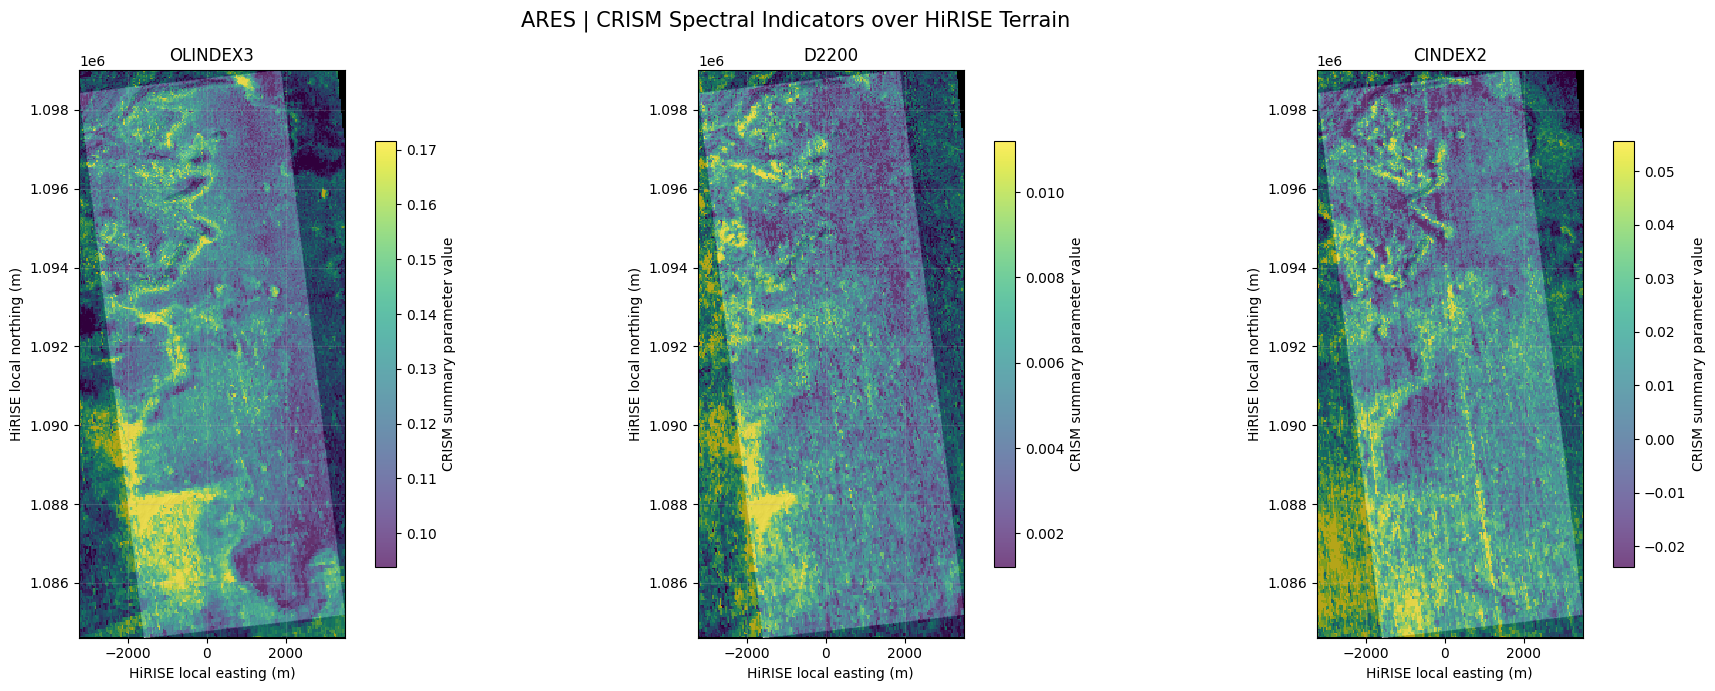


Saved registered overlay: /kaggle/working/ares_data/ares_crism_hirise_registered_overlay.png
Saved pixel coverage table: /kaggle/working/ares_data/crism_hirise_pixel_coverage.csv

ARES CRISM–HiRISE registration complete.


In [27]:
import os
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from math import cos, radians
from affine import Affine

DATA_DIR = "/kaggle/working/ares_data"

CRISM_IMAGE = os.path.join(
    DATA_DIR,
    "crism_data",
    "HRL000040FF_07_SR183J_MTR3.IMG"
)

CRISM_HEADER = os.path.join(
    DATA_DIR,
    "crism_data",
    "HRL000040FF_07_SR183J_MTR3.HDR"
)

HIRISE_DTM = os.path.join(
    DATA_DIR,
    "hirise_jezero_dtm.tif"
)

HIRISE_HILLSHADE = os.path.join(
    DATA_DIR,
    "hirise_hillshade.tif"
)

BAND_CSV = os.path.join(
    DATA_DIR,
    "crism_spectral_band_inventory.csv"
)

# ------------------------------------------------------------
# MARS PROJECTION PARAMETERS
# ------------------------------------------------------------

MARS_RADIUS = 3394839.813316312
STANDARD_PARALLEL = 15.0
CRISM_CENTRAL_MERIDIAN = 0.0
HIRISE_CENTRAL_MERIDIAN = 77.44

# East-west offset between the two equirectangular projections.
x_offset = (
    MARS_RADIUS
    * cos(radians(STANDARD_PARALLEL))
    * radians(
        HIRISE_CENTRAL_MERIDIAN
        - CRISM_CENTRAL_MERIDIAN
    )
)

print("=" * 72)
print("ARES | CRISM–HIRISE SPATIAL REGISTRATION")
print("=" * 72)

print("Mars reference radius:", MARS_RADIUS, "m")
print("Standard parallel:", STANDARD_PARALLEL, "degrees")
print("CRISM central meridian:", CRISM_CENTRAL_MERIDIAN, "degrees")
print("HiRISE central meridian:", HIRISE_CENTRAL_MERIDIAN, "degrees")
print("Calculated X translation:", round(x_offset, 3), "m")

# ------------------------------------------------------------
# LOAD CRISM DATA AND REGISTER ITS TRANSFORM
# ------------------------------------------------------------

band_df = pd.read_csv(BAND_CSV)
band_names = band_df["SR_band_name"].tolist()

with rasterio.open(CRISM_IMAGE) as crism:

    cube = crism.read().astype(np.float32)
    original_transform = crism.transform

    # Shift CRISM coordinates into the HiRISE local frame.
    crism_transform_local = (
        Affine.translation(-x_offset, 0)
        * original_transform
    )

    crism_bounds_original = crism.bounds

    crism_left = crism_bounds_original.left - x_offset
    crism_right = crism_bounds_original.right - x_offset
    crism_top = crism_bounds_original.top
    crism_bottom = crism_bounds_original.bottom

    crism_pixel_size = abs(crism.transform.a)

# ------------------------------------------------------------
# VALID-DATA MASK
# ------------------------------------------------------------

nodata = 65535.0

valid_cube = np.isfinite(cube) & (cube != nodata)

valid_pixel = (
    valid_cube.mean(axis=0) >= 0.80
)

# ------------------------------------------------------------
# LOAD HIRISE FOOTPRINT AND HILLSHADE
# ------------------------------------------------------------

with rasterio.open(HIRISE_DTM) as dtm:

    H = dtm.bounds
    dtm_crs = dtm.crs

    dtm_bounds = {
        "left": H.left,
        "right": H.right,
        "bottom": H.bottom,
        "top": H.top
    }

with rasterio.open(HIRISE_HILLSHADE) as hs_src:

    output_height = 1200
    output_width = max(
        1,
        int(hs_src.width * output_height / hs_src.height)
    )

    hillshade = hs_src.read(
        1,
        out_shape=(output_height, output_width)
    )

    hs_bounds = hs_src.bounds

# ------------------------------------------------------------
# CALCULATE CRISM PIXEL CENTER LOCATIONS
# ------------------------------------------------------------

height, width = valid_pixel.shape

cols = np.arange(width)
rows = np.arange(height)

x_centers = (
    crism_transform_local.c
    + (cols + 0.5) * crism_transform_local.a
)

y_centers = (
    crism_transform_local.f
    + (rows + 0.5) * crism_transform_local.e
)

X, Y = np.meshgrid(x_centers, y_centers)

inside_hirise = (
    (X >= H.left)
    & (X <= H.right)
    & (Y >= H.bottom)
    & (Y <= H.top)
)

valid_inside = inside_hirise & valid_pixel

inside_count = int(inside_hirise.sum())
valid_inside_count = int(valid_inside.sum())

valid_coverage = (
    100 * valid_inside_count / inside_count
    if inside_count else 0
)

# Approximate sampled area coverage from valid CRISM pixel centers.
hirise_area_m2 = (
    (H.right - H.left) * (H.top - H.bottom)
)

valid_crism_sample_area = (
    valid_inside_count * crism_pixel_size**2
)

approx_area_coverage = (
    100 * valid_crism_sample_area / hirise_area_m2
)

# ------------------------------------------------------------
# PRINT REGISTRATION TABLE
# ------------------------------------------------------------

coverage_table = pd.DataFrame([{
    "CRISM_product": "HRL000040FF_07_SR183J_MTR3",
    "CRISM_pixel_size_m": crism_pixel_size,
    "CRISM_pixels_inside_HiRISE": inside_count,
    "valid_CRISM_pixels_inside_HiRISE": valid_inside_count,
    "valid_fraction_of_inside_pixels_percent": valid_coverage,
    "approx_valid_sample_area_coverage_percent": approx_area_coverage
}])

print("\nSPATIAL COVERAGE RESULTS")
display(coverage_table.round(3))

print("\nCRISM transformed bounds:")
print({
    "left": crism_left,
    "right": crism_right,
    "bottom": crism_bottom,
    "top": crism_top
})

print("\nHiRISE DTM bounds:")
print(dtm_bounds)

# ------------------------------------------------------------
# PREPARE THREE SPECTRAL PARAMETER MAPS
# ------------------------------------------------------------

parameters = [
    "OLINDEX3",
    "D2200",
    "CINDEX2"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 7)
)

for ax, parameter in zip(axes, parameters):

    if parameter not in band_names:
        ax.set_title(parameter + " — missing")
        ax.axis("off")
        continue

    index = band_names.index(parameter)

    layer = cube[index].copy()

    # Exclude invalid CRISM pixels and samples outside HiRISE.
    layer[~valid_pixel] = np.nan
    layer[~inside_hirise] = np.nan

    values = layer[np.isfinite(layer)]

    ax.imshow(
        hillshade,
        extent=(
            hs_bounds.left,
            hs_bounds.right,
            hs_bounds.bottom,
            hs_bounds.top
        ),
        origin="upper",
        cmap="gray"
    )

    if values.size:

        vmin, vmax = np.percentile(
            values, [2, 98]
        )

        overlay = ax.imshow(
            layer,
            extent=(
                crism_left,
                crism_right,
                crism_bottom,
                crism_top
            ),
            origin="upper",
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            alpha=0.72,
            interpolation="nearest"
        )

        fig.colorbar(
            overlay,
            ax=ax,
            shrink=0.75,
            label="CRISM summary parameter value"
        )

    ax.set_xlim(H.left, H.right)
    ax.set_ylim(H.bottom, H.top)
    ax.set_aspect("equal")
    ax.set_title(parameter)
    ax.set_xlabel("HiRISE local easting (m)")
    ax.set_ylabel("HiRISE local northing (m)")
    ax.grid(alpha=0.2)

fig.suptitle(
    "ARES | CRISM Spectral Indicators over HiRISE Terrain",
    fontsize=15
)

plt.tight_layout()

map_path = os.path.join(
    DATA_DIR,
    "ares_crism_hirise_registered_overlay.png"
)

plt.savefig(map_path, dpi=180, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

coverage_path = os.path.join(
    DATA_DIR,
    "crism_hirise_pixel_coverage.csv"
)

coverage_table.to_csv(
    coverage_path,
    index=False
)

print("\nSaved registered overlay:", map_path)
print("Saved pixel coverage table:", coverage_path)

print("\nARES CRISM–HiRISE registration complete.")

### Step 19 — CRISM Processing-Information Quality Review

Retrieve the companion CRISM IN product for the selected observation.

Inspect its metadata to determine:
- Number and names of information bands
- Raster dimensions and data type
- NoData values and valid-data coverage
- Spatial correspondence with the SR product

Visualize the information bands and summarize their value
distributions.

Do not interpret undocumented flag values as quality categories.

ARES | CRISM PROCESSING-INFORMATION FILES


,filename,file_type,size_kb,url
104,HRL000040FF_07_IN183J_MTR3.LBL,Product,7,https://pds-geosciences.wustl.edu/mro/mro-m-cr...
115,HRL000040FF_07_IN183J_MTR3.HDR,Product,2,https://pds-geosciences.wustl.edu/mro/mro-m-cr...
116,HRL000040FF_07_IN183J_MTR3.IMG,Product,12302,https://pds-geosciences.wustl.edu/mro/mro-m-cr...


Downloaded: HRL000040FF_07_IN183J_MTR3.LBL
Downloaded: HRL000040FF_07_IN183J_MTR3.HDR
Downloaded: HRL000040FF_07_IN183J_MTR3.IMG

ENVI HEADER STRUCTURE
samples = 455
lines   = 751
bands   = 9
data type = 4
interleave = bsq
byte order = 0
map info = {MRO Mars Equirectangular [IAU 2000] [15.00N; 0.00E], 1.0000, 1.0000, 4422632.2000, 1109935.5000, 3.6000000000e+01, 3.6000000000e+01, D_Mars_2000_IAU_IAG_custom_sphere_lat15, units=Meters}
default bands = {1,1,1}
data ignore value = 6.55350000e+04
band names = {

PDS LABEL INFORMATION
  MINIMUM_LATITUDE             =  18.2767400 <DEGREE>
  MAXIMUM_LATITUDE             =  18.7324270 <DEGREE>
  WESTERNMOST_LONGITUDE        =  77.2755600 <DEGREE>
  EASTERNMOST_LONGITUDE        =  77.5611340 <DEGREE>
/* ENVI header description */
  DESCRIPTION             = "This text file can be used by ENVI image 
  LINES                    = 751
  LINE_SAMPLES             = 455
  SAMPLE_TYPE              = PC_REAL
  SAMPLE_BITS              = 32
  DESCRIPTION

,band_index,valid_pixels,valid_percent,unique_values_sample,minimum,median,maximum
0,1,220978,64.6692,63048,-13.1413,3.9065,10.6355
1,2,220978,64.6692,62220,-0.1128,0.0001,0.1137
2,3,220978,64.6692,62956,0.0055,0.0160,0.1885
3,4,238356,69.7549,315,0.0000,155.0000,314.0000
4,5,238356,69.7549,211,0.0000,222.0000,479.0000
5,6,238356,69.7549,320,0.0000,159.0000,319.0000
6,7,238356,69.7549,211,0.0000,222.0000,479.0000
7,8,238356,69.7549,52226,1.2219,11.9400,77.6936
8,9,238356,69.7549,2,0.0000,0.0000,1.0000


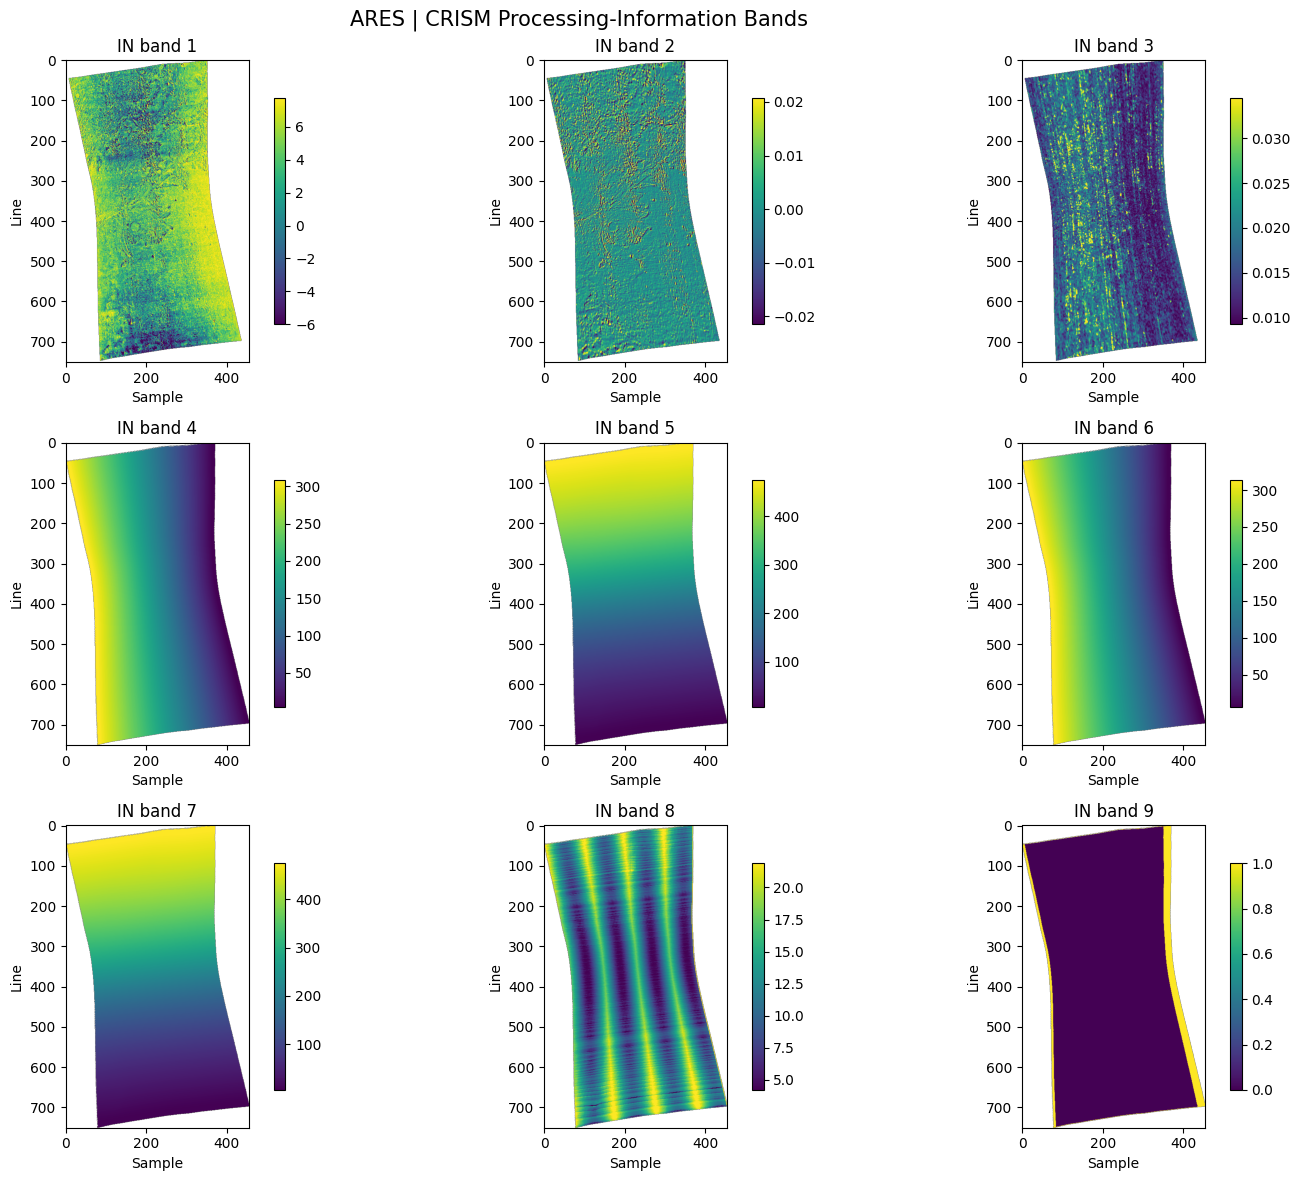


Saved IN statistics: /kaggle/working/ares_data/crism_in_band_statistics.csv
Saved IN visualization: /kaggle/working/ares_data/ares_crism_processing_information_maps.png

ARES processing-information inspection complete.


In [28]:
import os
import shutil
import requests
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

DATA_DIR = "/kaggle/working/ares_data"
META_DIR = os.path.join(DATA_DIR, "crism_science_metadata")
CRISM_DIR = os.path.join(DATA_DIR, "crism_data")

IN_PRODUCT = "HRL000040FF_07_IN183J_MTR3"

inventory = pd.read_csv(
    os.path.join(DATA_DIR, "crism_selected_product_inventory.csv")
)

files = inventory[
    inventory["filename"].str.upper().str.startswith(IN_PRODUCT)
].copy()

files = files[
    files["filename"].str.upper().str.endswith(
        (".HDR", ".IMG", ".LBL")
    )
]

print("=" * 72)
print("ARES | CRISM PROCESSING-INFORMATION FILES")
print("=" * 72)

display(files[["filename", "file_type", "size_kb", "url"]])

if files.empty:
    raise RuntimeError("No IN product files found in inventory.")

# ------------------------------------------------------------
# DOWNLOAD REQUIRED FILES
# ------------------------------------------------------------

for _, row in files.iterrows():

    filename = row["filename"]
    url = str(row["url"]).strip()

    destination = os.path.join(CRISM_DIR, filename)

    if os.path.exists(destination):
        continue

    if not url.startswith("http"):
        print("Invalid URL:", filename)
        continue

    response = requests.get(url, timeout=120)
    response.raise_for_status()

    with open(destination, "wb") as f:
        f.write(response.content)

    print("Downloaded:", filename)

# ------------------------------------------------------------
# READ HEADER AND LABEL
# ------------------------------------------------------------

header_path = os.path.join(
    CRISM_DIR, IN_PRODUCT + ".HDR"
)

label_path = os.path.join(
    CRISM_DIR, IN_PRODUCT + ".LBL"
)

if not os.path.exists(header_path):
    raise FileNotFoundError("IN ENVI header is missing.")

if not os.path.exists(label_path):
    raise FileNotFoundError("IN PDS label is missing.")

with open(header_path, "r", encoding="utf-8", errors="replace") as f:
    header_text = f.read()

with open(label_path, "r", encoding="utf-8", errors="replace") as f:
    label_text = f.read()

print("\nENVI HEADER STRUCTURE")
for line in header_text.splitlines():
    if any(k in line.lower() for k in [
        "samples", "lines", "bands", "data type",
        "interleave", "byte order", "data ignore",
        "band names", "map info"
    ]):
        print(line[:500])

print("\nPDS LABEL INFORMATION")
for line in label_text.splitlines():
    if any(k in line.lower() for k in [
        "description", "band_name", "sample_bits",
        "sample_type", "lines", "line_samples",
        "minimum_latitude", "maximum_latitude",
        "westernmost_longitude", "easternmost_longitude"
    ]):
        print(line[:500])

# ------------------------------------------------------------
# OPEN IMAGE AND VALIDATE
# ------------------------------------------------------------

image_path = os.path.join(
    CRISM_DIR, IN_PRODUCT + ".IMG"
)

if not os.path.exists(image_path):
    raise FileNotFoundError("IN image file is missing.")

with rasterio.open(image_path) as src:

    data = src.read()
    profile = src.profile.copy()
    transform = src.transform
    nodata = src.nodata

    print("\n" + "=" * 72)
    print("ARES | IN RASTER VALIDATION")
    print("=" * 72)

    print("Dimensions:", src.width, "x", src.height)
    print("Bands:", src.count)
    print("Data types:", src.dtypes)
    print("NoData:", nodata)
    print("CRS:", src.crs)
    print("Transform:", src.transform)

# ------------------------------------------------------------
# BUILD PER-BAND STATISTICS
# ------------------------------------------------------------

records = []

for i in range(data.shape[0]):

    band = data[i]
    valid = np.isfinite(band)

    if nodata is not None:
        valid &= band != nodata

    values = band[valid]

    records.append({
        "band_index": i + 1,
        "valid_pixels": int(values.size),
        "valid_percent": 100 * values.size / band.size,
        "unique_values_sample": int(
            np.unique(values[:min(values.size, 100000)]).size
        ),
        "minimum": float(values.min()) if values.size else np.nan,
        "median": float(np.median(values)) if values.size else np.nan,
        "maximum": float(values.max()) if values.size else np.nan
    })

summary = pd.DataFrame(records)

print("\nIN BAND STATISTICS")
display(summary.round(4))

# ------------------------------------------------------------
# VISUALIZE EACH INFORMATION BAND
# ------------------------------------------------------------

n = data.shape[0]
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(15, max(4, rows * 4))
)

axes = np.asarray(axes).reshape(-1)

for i, ax in enumerate(axes):

    if i >= n:
        ax.axis("off")
        continue

    band = data[i].astype(float)

    valid = np.isfinite(band)

    if nodata is not None:
        valid &= band != nodata

    band[~valid] = np.nan

    values = band[np.isfinite(band)]

    if values.size:
        vmin, vmax = np.nanpercentile(values, [2, 98])
    else:
        vmin, vmax = 0, 1

    im = ax.imshow(
        band,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(f"IN band {i + 1}")
    ax.set_xlabel("Sample")
    ax.set_ylabel("Line")

    fig.colorbar(im, ax=ax, shrink=0.75)

fig.suptitle(
    "ARES | CRISM Processing-Information Bands",
    fontsize=15
)

plt.tight_layout()

plot_path = os.path.join(
    DATA_DIR,
    "ares_crism_processing_information_maps.png"
)

plt.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

csv_path = os.path.join(
    DATA_DIR,
    "crism_in_band_statistics.csv"
)

summary.to_csv(csv_path, index=False)

print("\nSaved IN statistics:", csv_path)
print("Saved IN visualization:", plot_path)
print("\nARES processing-information inspection complete.")

### Step 20 — CRISM IN Band Interpretation

Use the nine official band names recovered from the ENVI header.

Summarize each band's numerical distribution and visualize
the processing-information layers.

Preserve the original values. Do not infer undocumented
quality-flag meanings.

ARES | CRISM IN OFFICIAL BAND SUMMARY


,Band,Official name,Valid pixels,Valid percent,Minimum,Median,Maximum,Unique values
0,1,VNIR/IR Spectral Continuity Residual,220978,64.6692,-13.1413,3.9065,10.6355,63048
1,2,VNIR/IR Spatial Gradient Residual,220978,64.6692,-0.1128,0.0001,0.1137,62220
2,3,ATM Correction Spectral Shift Artifact,220978,64.6692,0.0055,0.0160,0.1885,62956
3,4,VNIR Sample,238356,69.7549,0.0000,155.0000,314.0000,315
4,5,VNIR Line,238356,69.7549,0.0000,222.0000,479.0000,211
5,6,IR Sample,238356,69.7549,0.0000,159.0000,319.0000,320
6,7,IR Line,238356,69.7549,0.0000,222.0000,479.0000,211
7,8,VNIR/IR Ground Sampling Offset,238356,69.7549,1.2219,11.9400,77.6936,52226
8,9,VNIR/IR Mask,238356,69.7549,0.0000,0.0000,1.0000,2


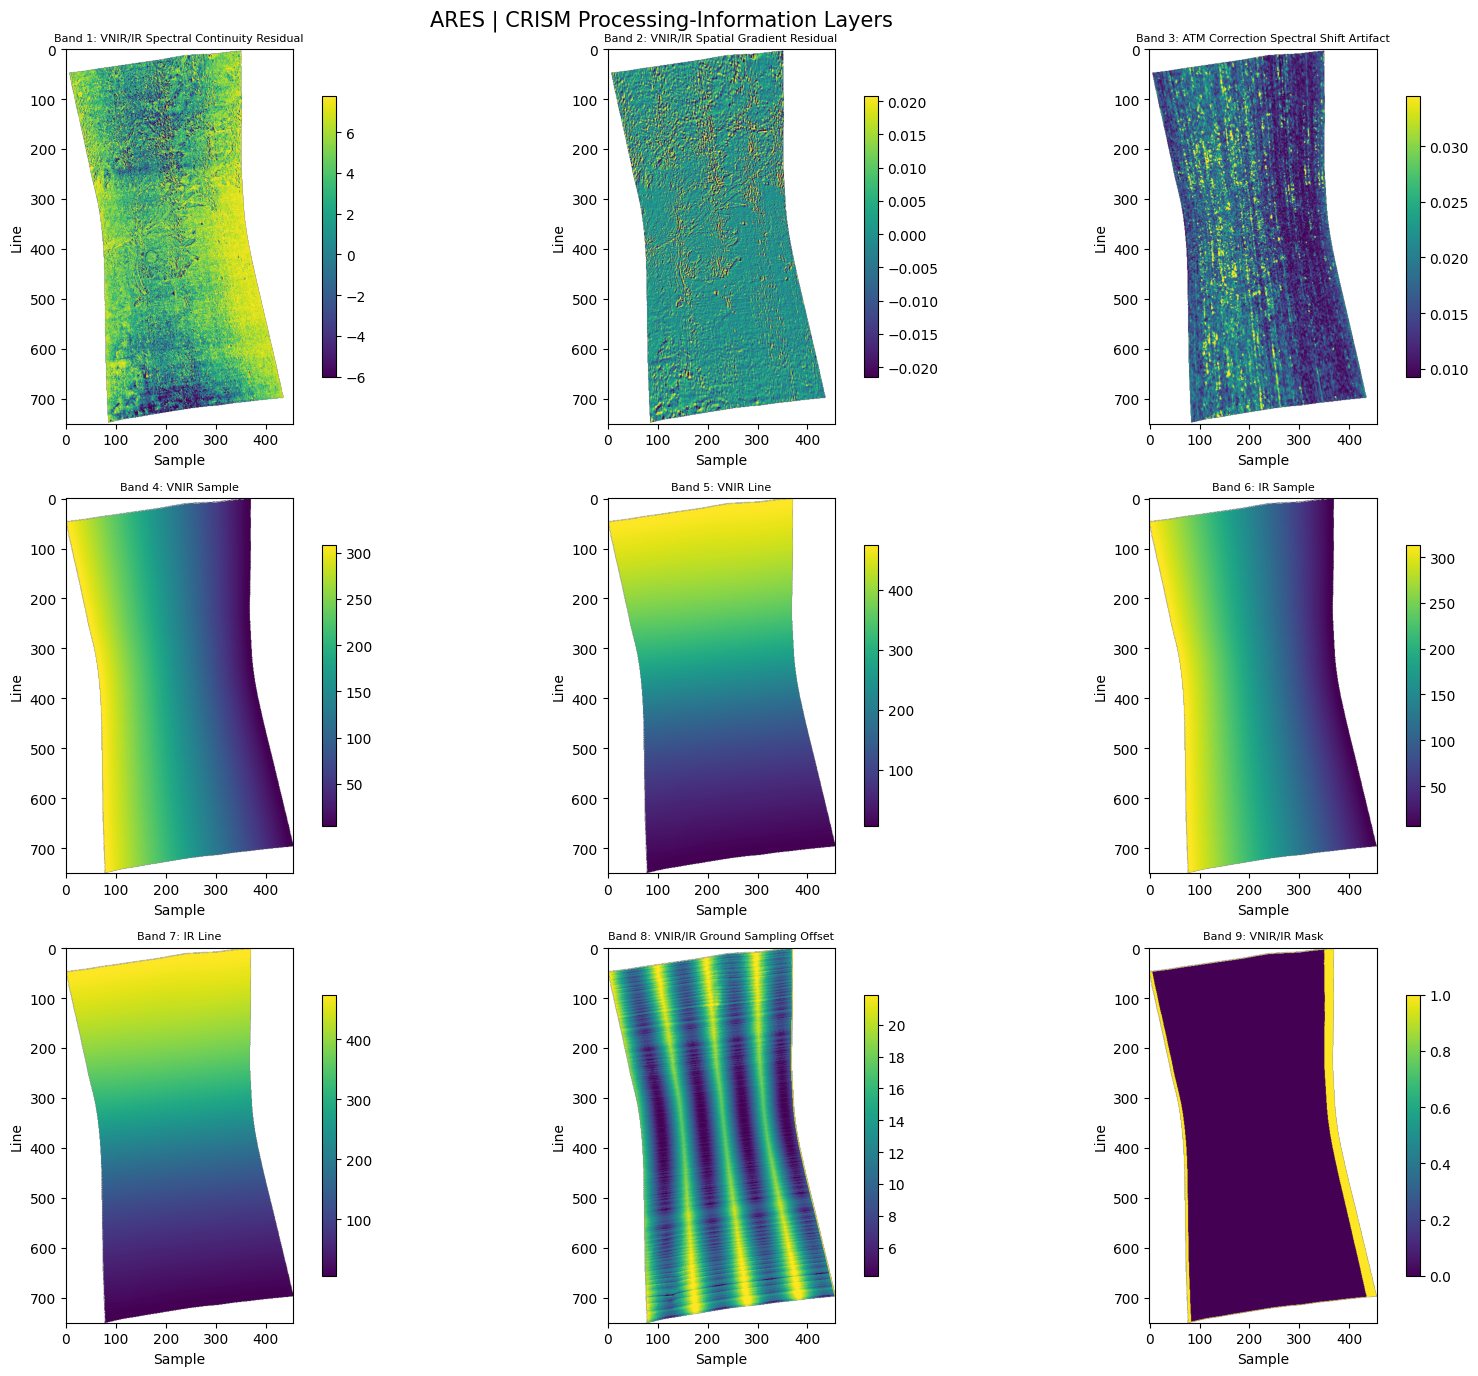

Saved: /kaggle/working/ares_data/ares_crism_in_official_band_maps.png
CRISM IN band review complete.


In [30]:
import os
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

DATA_DIR = "/kaggle/working/ares_data"
CRISM_DIR = os.path.join(DATA_DIR, "crism_data")

PRODUCT = "HRL000040FF_07_IN183J_MTR3"

IN_NAMES = [
    "VNIR/IR Spectral Continuity Residual",
    "VNIR/IR Spatial Gradient Residual",
    "ATM Correction Spectral Shift Artifact",
    "VNIR Sample",
    "VNIR Line",
    "IR Sample",
    "IR Line",
    "VNIR/IR Ground Sampling Offset",
    "VNIR/IR Mask"
]

IN_PATH = os.path.join(
    CRISM_DIR, PRODUCT + ".IMG"
)

with rasterio.open(IN_PATH) as src:
    data = src.read()
    nodata = src.nodata

if data.shape[0] != len(IN_NAMES):
    raise RuntimeError("Unexpected IN band count.")

records = []

for i, band in enumerate(data):

    valid = np.isfinite(band)

    if nodata is not None:
        valid &= band != nodata

    values = band[valid]

    records.append({
        "Band": i + 1,
        "Official name": IN_NAMES[i],
        "Valid pixels": int(values.size),
        "Valid percent": 100 * values.size / band.size,
        "Minimum": float(values.min()),
        "Median": float(np.median(values)),
        "Maximum": float(values.max()),
        "Unique values": int(np.unique(
            values[:min(len(values), 100000)]
        ).size)
    })

summary = pd.DataFrame(records)

print("=" * 70)
print("ARES | CRISM IN OFFICIAL BAND SUMMARY")
print("=" * 70)

display(summary.round(4))

# Visualize all nine bands
fig, axes = plt.subplots(3, 3, figsize=(17, 14))

for i, ax in enumerate(axes.flat):

    band = data[i].astype(float)

    valid = np.isfinite(band)

    if nodata is not None:
        valid &= band != nodata

    band[~valid] = np.nan

    values = band[np.isfinite(band)]

    if values.size:
        vmin, vmax = np.nanpercentile(values, [2, 98])
    else:
        vmin, vmax = 0, 1

    im = ax.imshow(
        band,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(
        f"Band {i+1}: {IN_NAMES[i]}",
        fontsize=8
    )

    ax.set_xlabel("Sample")
    ax.set_ylabel("Line")

    fig.colorbar(im, ax=ax, shrink=0.75)

plt.suptitle(
    "ARES | CRISM Processing-Information Layers",
    fontsize=15
)

plt.tight_layout()

plot_path = os.path.join(
    DATA_DIR,
    "ares_crism_in_official_band_maps.png"
)

plt.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()

summary.to_csv(
    os.path.join(
        DATA_DIR,
        "crism_in_official_band_summary.csv"
    ),
    index=False
)

print("Saved:", plot_path)
print("CRISM IN band review complete.")

### Step 21 — CRISM Mask Semantics and Cross-Validation

Inspect the PDS label for the official definition of the
VNIR/IR Mask.

Calculate the frequency of each mask value and compare
mask values against SR spectral-data validity.

Visualize the mask and its relationship to the SR valid-data
footprint.

Do not assign valid/invalid meaning to mask values until
the source documentation confirms their interpretation.

ARES | CRISM MASK DOCUMENTATION
0064: SOLAR_DISTANCE                = 221055579.116406 <KILOMETER>
0065: SOLAR_LONGITUDE               = 174.791242
0066: MRO:PHOTOMETRIC_CORR_FLAG        = "ON"
0067: MRO:ATMOSPHERIC_CORR_FLAG        = "ON"
0068: MRO:RATIO_SHIFT_CORR_FLAG        = "ON"
0069: MRO:EMPIRICAL_GEOM_NORM_FLAG     = "ON"
0070: MRO:EMPIRICAL_SMILE_CORR_FLAG    = "ON"
0071: MRO:SENSOR_SPACE_TRANSFORM_FLAG  = "ON"
0072: 
0073: /* Map projection information about this RDR is in the */
0074: /* IMAGE_MAP_PROJECTION object below.                  */
0075: 
0126:   BANDS                    = 9
0127:   BAND_STORAGE_TYPE        = BAND_SEQUENTIAL
0128:   BAND_NAME                = ( "VNIR/IR Spectral Continuity Residual",
0129:                                "VNIR/IR Spatial Gradient Residual",
0130:                                "ATM Correction Spectral Shift Artifact",
0131:                                "VNIR Sample",
0132:                                "VNIR Line",
0134:         

,Mask value,Pixel count,Share of valid mask pixels (%)
0,0.0,220978,92.709
1,1.0,17378,7.291



MASK–SR VALIDITY CROSS-TABULATION


,Mask value,Mask pixels,SR valid pixels,SR invalid pixels,SR valid within mask value (%)
0,0.0,220978,220978,0,100.0
1,1.0,17378,0,17378,0.0


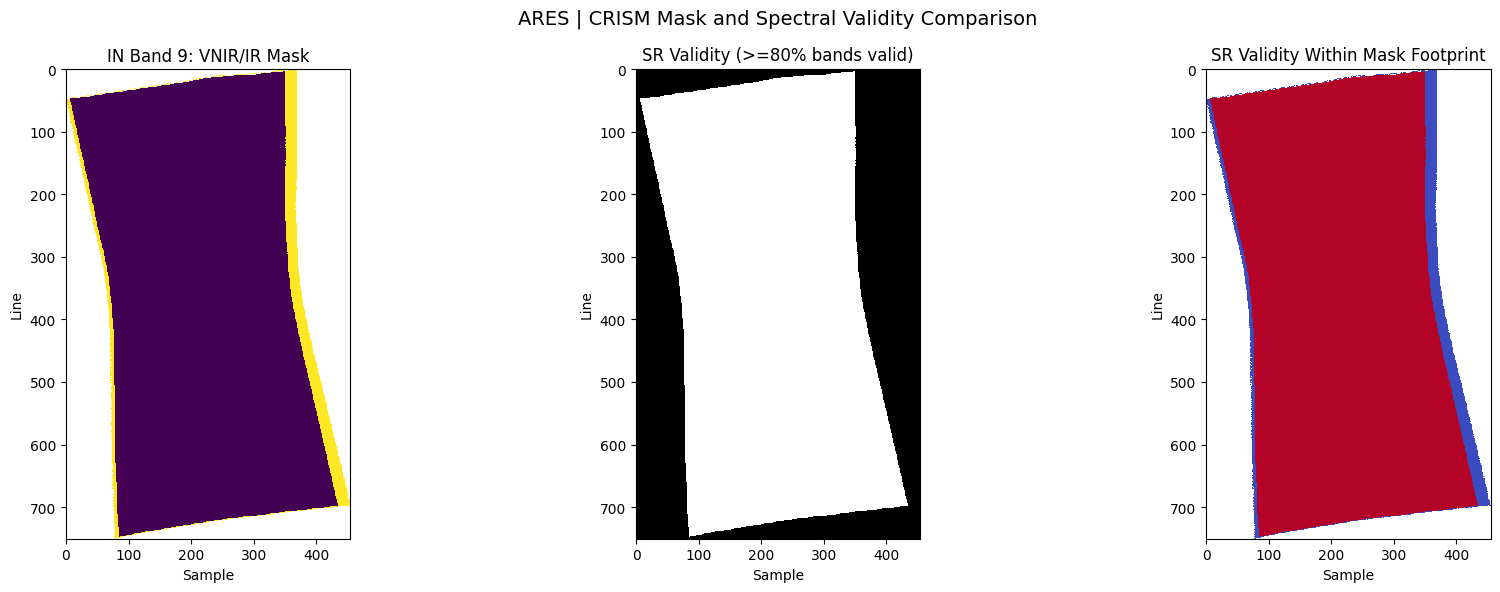


Saved mask frequency and cross-validation tables.
Saved visualization: /kaggle/working/ares_data/ares_crism_mask_sr_cross_validation.png

ARES mask cross-validation complete.


In [31]:
import os
import re
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

DATA_DIR = "/kaggle/working/ares_data"
CRISM_DIR = os.path.join(DATA_DIR, "crism_data")

IN_PRODUCT = "HRL000040FF_07_IN183J_MTR3"
SR_PRODUCT = "HRL000040FF_07_SR183J_MTR3"

label_path = os.path.join(CRISM_DIR, IN_PRODUCT + ".LBL")
in_path = os.path.join(CRISM_DIR, IN_PRODUCT + ".IMG")
sr_path = os.path.join(CRISM_DIR, SR_PRODUCT + ".IMG")

# ------------------------------------------------------------
# INSPECT OFFICIAL LABEL TEXT
# ------------------------------------------------------------

with open(label_path, "r", encoding="utf-8", errors="replace") as f:
    label_lines = f.readlines()

print("=" * 70)
print("ARES | CRISM MASK DOCUMENTATION")
print("=" * 70)

keywords = [
    "MASK",
    "QUALITY",
    "VALID",
    "INVALID",
    "FLAG",
    "BAND_NAME"
]

found = set()

for i, line in enumerate(label_lines):

    if any(word in line.upper() for word in keywords):

        start = max(0, i - 2)
        end = min(len(label_lines), i + 5)

        for j in range(start, end):
            if j not in found:
                print(f"{j + 1:04d}: {label_lines[j].rstrip()}")
                found.add(j)

# ------------------------------------------------------------
# LOAD IN MASK AND SR DATA
# ------------------------------------------------------------

with rasterio.open(in_path) as src:
    in_data = src.read()
    in_nodata = src.nodata
    in_transform = src.transform
    in_shape = (src.height, src.width)

with rasterio.open(sr_path) as src:
    sr_data = src.read()
    sr_nodata = src.nodata
    sr_transform = src.transform
    sr_shape = (src.height, src.width)

if in_shape != sr_shape or in_transform != sr_transform:
    raise RuntimeError("IN and SR grids do not match.")

# Band 9 is the documented VNIR/IR Mask.
mask = in_data[8]

mask_valid = np.isfinite(mask)

if in_nodata is not None:
    mask_valid &= mask != in_nodata

# SR validity: at least 80% of spectral bands are valid.
sr_valid_bands = np.isfinite(sr_data)

if sr_nodata is not None:
    sr_valid_bands &= sr_data != sr_nodata

sr_valid_fraction = sr_valid_bands.mean(axis=0)
sr_valid_pixels = sr_valid_fraction >= 0.80

# ------------------------------------------------------------
# MASK VALUE FREQUENCIES
# ------------------------------------------------------------

values, counts = np.unique(
    mask[mask_valid],
    return_counts=True
)

frequency = pd.DataFrame({
    "Mask value": values,
    "Pixel count": counts,
    "Share of valid mask pixels (%)":
        100 * counts / counts.sum()
})

print("\nMASK VALUE FREQUENCIES")
display(frequency.round(3))

# ------------------------------------------------------------
# CROSS-TABULATE MASK AND SR VALIDITY
# ------------------------------------------------------------

cross_records = []

for value in values:

    selected = mask_valid & (mask == value)

    total = int(selected.sum())
    sr_good = int((selected & sr_valid_pixels).sum())
    sr_bad = int((selected & ~sr_valid_pixels).sum())

    cross_records.append({
        "Mask value": float(value),
        "Mask pixels": total,
        "SR valid pixels": sr_good,
        "SR invalid pixels": sr_bad,
        "SR valid within mask value (%)":
            100 * sr_good / total if total else np.nan
    })

cross_table = pd.DataFrame(cross_records)

print("\nMASK–SR VALIDITY CROSS-TABULATION")
display(cross_table.round(3))

# ------------------------------------------------------------
# VISUALIZE MASK AND SR VALIDITY
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

mask_display = mask.astype(float)
mask_display[~mask_valid] = np.nan

axes[0].imshow(mask_display, cmap="viridis", interpolation="nearest")
axes[0].set_title("IN Band 9: VNIR/IR Mask")

axes[1].imshow(
    sr_valid_pixels,
    cmap="gray",
    interpolation="nearest"
)
axes[1].set_title("SR Validity (>=80% bands valid)")

comparison = np.full(mask.shape, np.nan)

comparison[mask_valid & sr_valid_pixels] = 1
comparison[mask_valid & ~sr_valid_pixels] = 0

axes[2].imshow(
    comparison,
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)
axes[2].set_title("SR Validity Within Mask Footprint")

for ax in axes:
    ax.set_xlabel("Sample")
    ax.set_ylabel("Line")

fig.suptitle(
    "ARES | CRISM Mask and Spectral Validity Comparison",
    fontsize=14
)

plt.tight_layout()

plot_path = os.path.join(
    DATA_DIR,
    "ares_crism_mask_sr_cross_validation.png"
)

plt.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# SAVE TABLES
# ------------------------------------------------------------

frequency.to_csv(
    os.path.join(DATA_DIR, "crism_mask_value_frequency.csv"),
    index=False
)

cross_table.to_csv(
    os.path.join(DATA_DIR, "crism_mask_sr_cross_validation.csv"),
    index=False
)

print("\nSaved mask frequency and cross-validation tables.")
print("Saved visualization:", plot_path)
print("\nARES mask cross-validation complete.")

---
# PART 4B — Fusing terrain and spectra
CRISM values are moved into the HiRISE-local frame and aggregated onto the 100 m grid. The notebook **stops with an error if the grids do not overlap**, rather than report an empty comparison.


### Step 22 — CRISM–Terrain Spatial Integration

Translate the CRISM coordinates into the HiRISE-local Mars
coordinate frame and explicitly assign the HiRISE-local
coordinate reference system to the translated grid.

Aggregate quality-controlled CRISM spectral parameters onto
the 100 m terrain screening grid.

Validate spatial overlap before calculating candidate-versus-
screened-out statistics.

If the grids do not overlap, stop rather than report misleading
statistics.

ARES | CRISM SPATIAL REGISTRATION DIAGNOSTICS
Quality-controlled CRISM pixels: 220978
Terrain grid shape: (145, 68)
Terrain bounds: BoundingBox(left=-3242.028942583203, bottom=1084514.4926458849, right=3557.971057416797, top=1099014.4926458849)
Terrain CRS: PROJCS["EQUIRECTANGULAR MARS",GEOGCS["GCS_MARS",DATUM["D_MARS",SPHEROID["MARS_localRadius",3394839.8133163,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",15],PARAMETER["central_meridian",77.44],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]

TRANSLATED CRISM BOUNDS
Left: -9429.286294042133
Bottom: 1082899.5
Right: 6950.713705957867
Top: 1109935.5

SPATIAL OVERLAP CHECK
Overlap exists: True
Overlap width (m): 6800.0
Overlap height (m): 14500.0

TERRAIN CELL COUNTS
Candidate: 6522
Screened out: 517

OLINDEX3 | Valid aggregated ter

,Parameter,Terrain group,Cells with CRISM data,Median,Mean,25th percentile,75th percentile
0,OLINDEX3,Candidate,6522,0.12574,0.12789,0.11557,0.13723
1,OLINDEX3,Screened out,517,0.12894,0.12868,0.11741,0.13892
2,D2200,Candidate,6522,0.00493,0.00523,0.00391,0.00614
3,D2200,Screened out,517,0.00566,0.00581,0.00437,0.00692
4,CINDEX2,Candidate,6522,0.01269,0.01283,0.00252,0.02253
5,CINDEX2,Screened out,517,0.01173,0.01039,-0.00227,0.02286


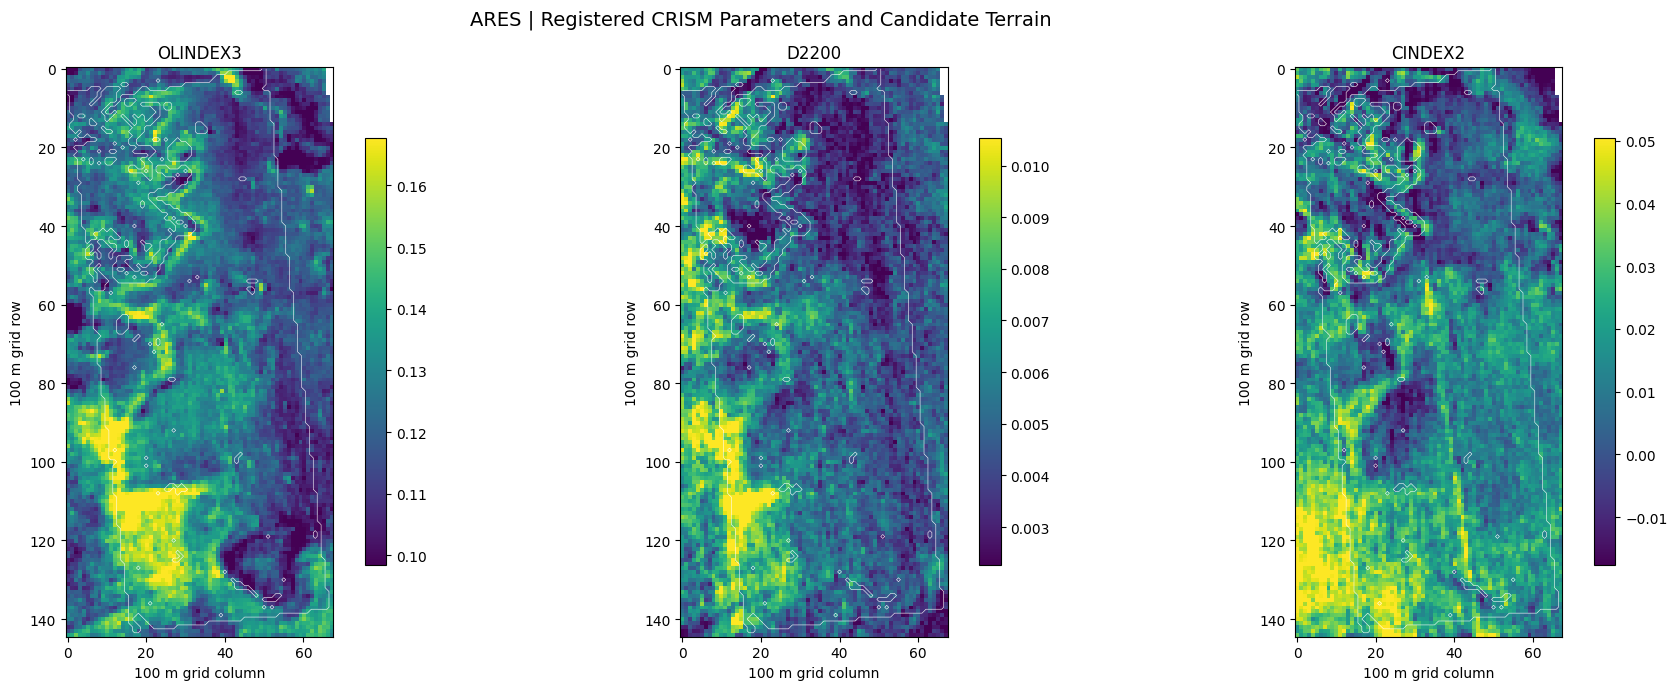


Saved visualization: /kaggle/working/ares_data/ares_crism_terrain_parameter_comparison.png
Saved summary: /kaggle/working/ares_data/ares_crism_terrain_parameter_summary.csv
ARES spatial integration complete.


In [35]:
import os
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from affine import Affine
from rasterio.warp import reproject, Resampling

DATA_DIR = "/kaggle/working/ares_data"
CRISM_DIR = os.path.join(DATA_DIR, "crism_data")

SR_PATH = os.path.join(
    CRISM_DIR, "HRL000040FF_07_SR183J_MTR3.IMG"
)
IN_PATH = os.path.join(
    CRISM_DIR, "HRL000040FF_07_IN183J_MTR3.IMG"
)
CORRIDOR_PATH = os.path.join(
    DATA_DIR, "ares_corridor_candidates.tif"
)

# ------------------------------------------------------------
# LOAD CRISM DATA
# ------------------------------------------------------------

with rasterio.open(SR_PATH) as sr, rasterio.open(IN_PATH) as ins:
    sr_data = sr.read()
    sr_nodata = sr.nodata

    in_mask = ins.read(9)
    in_nodata = ins.nodata

    crism_transform = sr.transform
    crism_shape = (sr.height, sr.width)

# ------------------------------------------------------------
# LOAD TERRAIN GRID
# ------------------------------------------------------------

with rasterio.open(CORRIDOR_PATH) as ds:
    terrain = ds.read(1)
    terrain_transform = ds.transform
    terrain_crs = ds.crs
    terrain_valid = ds.read_masks(1) > 0
    terrain_shape = terrain.shape
    terrain_bounds = ds.bounds

# ------------------------------------------------------------
# APPLY CRISM QUALITY CONTROL
# ------------------------------------------------------------

sr_valid_bands = np.isfinite(sr_data)

if sr_nodata is not None:
    sr_valid_bands &= sr_data != sr_nodata

sr_valid = sr_valid_bands.mean(axis=0) >= 0.80

mask_valid = np.isfinite(in_mask)

if in_nodata is not None:
    mask_valid &= in_mask != in_nodata

quality_valid = mask_valid & (in_mask == 0) & sr_valid

print("=" * 72)
print("ARES | CRISM SPATIAL REGISTRATION DIAGNOSTICS")
print("=" * 72)

print("Quality-controlled CRISM pixels:", int(quality_valid.sum()))
print("Terrain grid shape:", terrain_shape)
print("Terrain bounds:", terrain_bounds)
print("Terrain CRS:", terrain_crs)

# ------------------------------------------------------------
# TRANSLATE CRISM COORDINATES
# ------------------------------------------------------------

mars_radius = 3394839.81331631
standard_parallel = 15.0
central_meridian = 77.44

x_offset = (
    mars_radius
    * np.cos(np.radians(standard_parallel))
    * np.radians(central_meridian)
)

# The CRISM x-coordinate is translated into the HiRISE
# local coordinate frame. Its CRS must now be the HiRISE
# local CRS, not the original CRISM central-meridian CRS.

crism_local_transform = Affine(
    crism_transform.a,
    crism_transform.b,
    crism_transform.c - x_offset,
    crism_transform.d,
    crism_transform.e,
    crism_transform.f
)

# Use the HiRISE-local CRS because the coordinates have
# already been transformed into that coordinate frame.
crism_local_crs = terrain_crs

# Calculate translated CRISM bounds.
left = crism_local_transform.c
top = crism_local_transform.f
right = left + crism_shape[1] * crism_local_transform.a
bottom = top + crism_shape[0] * crism_local_transform.e

print("\nTRANSLATED CRISM BOUNDS")
print("Left:", left)
print("Bottom:", bottom)
print("Right:", right)
print("Top:", top)

# ------------------------------------------------------------
# CHECK SPATIAL OVERLAP
# ------------------------------------------------------------

overlap_left = max(left, terrain_bounds.left)
overlap_right = min(right, terrain_bounds.right)
overlap_bottom = max(bottom, terrain_bounds.bottom)
overlap_top = min(top, terrain_bounds.top)

overlap_exists = (
    overlap_left < overlap_right
    and overlap_bottom < overlap_top
)

print("\nSPATIAL OVERLAP CHECK")
print("Overlap exists:", overlap_exists)

if not overlap_exists:
    raise RuntimeError(
        "Translated CRISM and terrain grids do not overlap. "
        "Stop: coordinate registration requires further review."
    )

print(
    "Overlap width (m):",
    round(overlap_right - overlap_left, 2)
)
print(
    "Overlap height (m):",
    round(overlap_top - overlap_bottom, 2)
)

# ------------------------------------------------------------
# VERIFY GRID VALUES
# ------------------------------------------------------------

classes = np.unique(terrain[terrain_valid])

if not set(classes.tolist()).issubset({1, 2}):
    raise RuntimeError(
        f"Unexpected terrain values: {classes.tolist()}"
    )

CANDIDATE_VALUE = 1
SCREENED_VALUE = 2

print("\nTERRAIN CELL COUNTS")
print(
    "Candidate:",
    int((terrain_valid & (terrain == CANDIDATE_VALUE)).sum())
)
print(
    "Screened out:",
    int((terrain_valid & (terrain == SCREENED_VALUE)).sum())
)

# ------------------------------------------------------------
# AGGREGATE CRISM PARAMETERS
# ------------------------------------------------------------

parameters = {
    "OLINDEX3": 14,
    "D2200": 34,
    "CINDEX2": 51
}

aggregated = {}
records = []

for name, band_number in parameters.items():

    band = sr_data[band_number - 1].astype(np.float32)

    source_valid = quality_valid & np.isfinite(band)

    if sr_nodata is not None:
        source_valid &= band != sr_nodata

    source = np.where(
        source_valid,
        band,
        np.nan
    ).astype(np.float32)

    destination = np.full(
        terrain_shape,
        np.nan,
        dtype=np.float32
    )

    reproject(
        source=source,
        destination=destination,
        src_transform=crism_local_transform,
        src_crs=crism_local_crs,
        src_nodata=np.nan,
        dst_transform=terrain_transform,
        dst_crs=terrain_crs,
        dst_nodata=np.nan,
        resampling=Resampling.average
    )

    aggregated[name] = destination

    print(
        f"\n{name} | Valid aggregated terrain cells:",
        int(np.isfinite(destination).sum())
    )

    for group_value, group_name in [
        (CANDIDATE_VALUE, "Candidate"),
        (SCREENED_VALUE, "Screened out")
    ]:

        selected = (
            terrain_valid
            & (terrain == group_value)
            & np.isfinite(destination)
        )

        values = destination[selected]

        records.append({
            "Parameter": name,
            "Terrain group": group_name,
            "Cells with CRISM data": int(values.size),
            "Median": float(np.median(values)) if values.size else np.nan,
            "Mean": float(np.mean(values)) if values.size else np.nan,
            "25th percentile": (
                float(np.percentile(values, 25))
                if values.size else np.nan
            ),
            "75th percentile": (
                float(np.percentile(values, 75))
                if values.size else np.nan
            )
        })

# ------------------------------------------------------------
# VALIDATE AGGREGATION
# ------------------------------------------------------------

total_aggregated = sum(
    int(np.isfinite(array).sum())
    for array in aggregated.values()
)

if total_aggregated == 0:
    raise RuntimeError(
        "No CRISM values reached the terrain grid. "
        "Do not interpret or save an empty comparison."
    )

summary = pd.DataFrame(records)

print("\nCRISM PARAMETER COMPARISON")
display(summary.round(5))

# ------------------------------------------------------------
# VISUALIZE
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(19, 7))

candidate_outline = (
    terrain_valid & (terrain == CANDIDATE_VALUE)
).astype(float)

for ax, name in zip(axes, parameters):

    image = aggregated[name]
    values = image[np.isfinite(image)]

    if values.size == 0:
        ax.set_title(name + " — no valid overlap")
        ax.axis("off")
        continue

    vmin, vmax = np.percentile(values, [2, 98])

    im = ax.imshow(
        image,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest"
    )

    ax.contour(
        candidate_outline,
        levels=[0.5],
        colors="white",
        linewidths=0.4
    )

    ax.set_title(name)
    ax.set_xlabel("100 m grid column")
    ax.set_ylabel("100 m grid row")

    fig.colorbar(im, ax=ax, shrink=0.75)

fig.suptitle(
    "ARES | Registered CRISM Parameters and Candidate Terrain",
    fontsize=14
)

plt.tight_layout()

plot_path = os.path.join(
    DATA_DIR,
    "ares_crism_terrain_parameter_comparison.png"
)

plt.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

summary_path = os.path.join(
    DATA_DIR,
    "ares_crism_terrain_parameter_summary.csv"
)

summary.to_csv(summary_path, index=False)

print("\nSaved visualization:", plot_path)
print("Saved summary:", summary_path)
np.savez(os.path.join(DATA_DIR, "crism_aggregated.npz"), **aggregated)
print("Saved aggregates:", os.path.join(DATA_DIR, "crism_aggregated.npz"))
print("ARES spatial integration complete.")

### Step 23 — CRISM Spectral Contrast Assessment

Quantify differences between candidate and screened-out terrain
for OLINDEX3, D2200, and CINDEX2.

Report:
- Sample counts
- Median and interquartile range
- Difference in group medians
- Relative median difference
- Standardized mean difference

Visualize the distributions to assess their overlap.

These are descriptive comparisons. Spatial autocorrelation means
ordinary independent-sample significance tests would be misleading.
No mineral identification or geological superiority is inferred.

ARES | CRISM SPECTRAL CONTRAST ASSESSMENT


,Parameter,Candidate cells,Screened-out cells,Candidate median,Screened-out median,Candidate IQR,Screened-out IQR,Median difference,Relative median difference (%),Standardized mean difference
0,OLINDEX3,6522,517,0.125739,0.128944,0.021659,0.021506,-0.003205,-2.485711,-0.048439
1,D2200,6522,517,0.004930,0.005664,0.002223,0.002559,-0.000735,-12.971940,-0.300744
2,CINDEX2,6522,517,0.012689,0.011734,0.020005,0.025132,0.000955,8.137483,0.148984


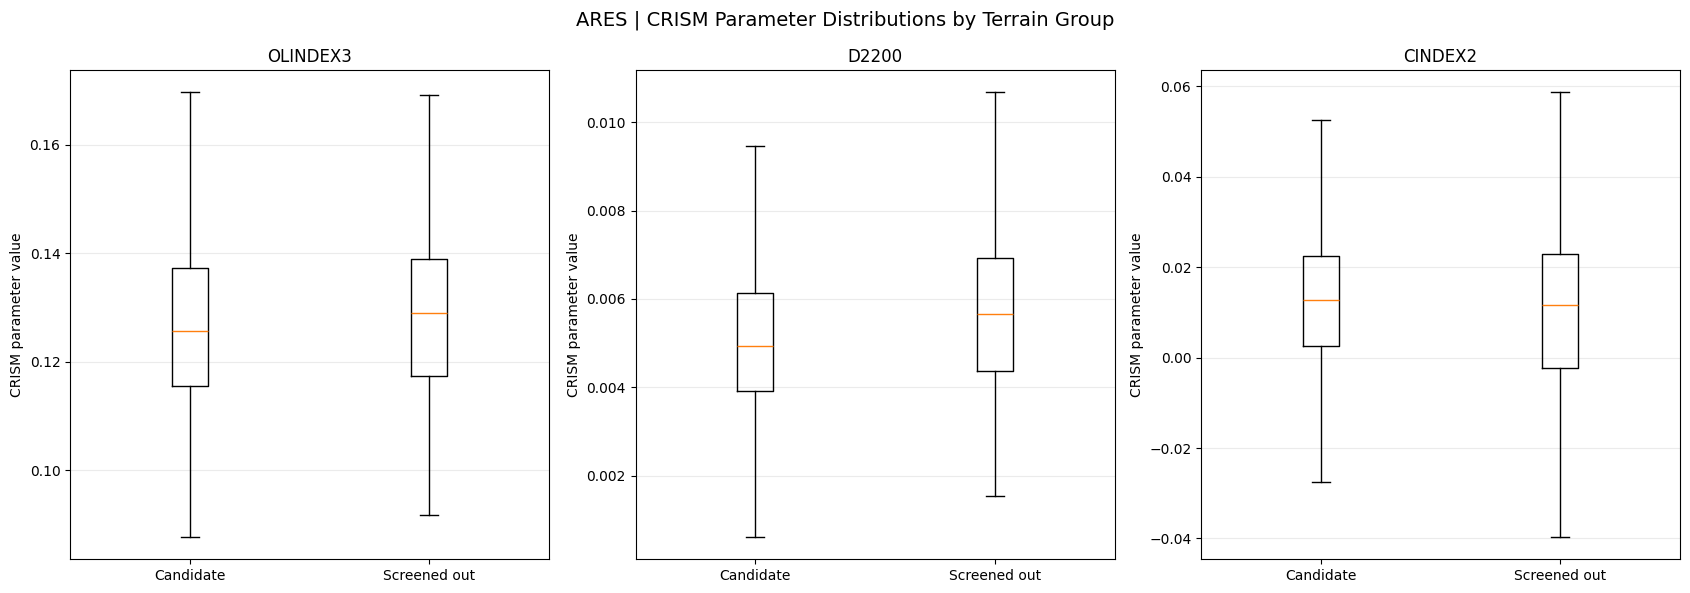


Saved visualization: /kaggle/working/ares_data/ares_crism_spectral_contrast.png
Saved comparison table: /kaggle/working/ares_data/ares_crism_spectral_contrast.csv
ARES spectral contrast assessment complete.


In [36]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "/kaggle/working/ares_data"

# Confirm the previous integration results are available.
required = ["aggregated", "terrain", "terrain_valid"]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Missing variables from Section 9.13: "
        + ", ".join(missing)
        + ". Rerun the corrected Section 9.13 cell first."
    )

PARAMETERS = ["OLINDEX3", "D2200", "CINDEX2"]

GROUPS = {
    "Candidate": 1,
    "Screened out": 2
}

records = []
plot_data = {}

for parameter in PARAMETERS:

    image = aggregated[parameter]

    candidate_mask = (
        terrain_valid
        & (terrain == GROUPS["Candidate"])
        & np.isfinite(image)
    )

    screened_mask = (
        terrain_valid
        & (terrain == GROUPS["Screened out"])
        & np.isfinite(image)
    )

    candidate = image[candidate_mask]
    screened = image[screened_mask]

    plot_data[parameter] = {
        "Candidate": candidate,
        "Screened out": screened
    }

    if len(candidate) == 0 or len(screened) == 0:
        raise RuntimeError(
            f"Insufficient data for {parameter} comparison."
        )

    candidate_median = float(np.median(candidate))
    screened_median = float(np.median(screened))

    candidate_mean = float(np.mean(candidate))
    screened_mean = float(np.mean(screened))

    pooled_sd = np.sqrt(
        (
            np.var(candidate, ddof=1)
            + np.var(screened, ddof=1)
        ) / 2
    )

    standardized_difference = (
        (candidate_mean - screened_mean) / pooled_sd
        if pooled_sd > 0 else np.nan
    )

    median_difference = candidate_median - screened_median

    relative_difference = (
        100 * median_difference / abs(screened_median)
        if screened_median != 0 else np.nan
    )

    records.append({
        "Parameter": parameter,
        "Candidate cells": len(candidate),
        "Screened-out cells": len(screened),
        "Candidate median": candidate_median,
        "Screened-out median": screened_median,
        "Candidate IQR": (
            np.percentile(candidate, 75)
            - np.percentile(candidate, 25)
        ),
        "Screened-out IQR": (
            np.percentile(screened, 75)
            - np.percentile(screened, 25)
        ),
        "Median difference": median_difference,
        "Relative median difference (%)": relative_difference,
        "Standardized mean difference": standardized_difference
    })

comparison = pd.DataFrame(records)

print("=" * 72)
print("ARES | CRISM SPECTRAL CONTRAST ASSESSMENT")
print("=" * 72)

display(comparison.round(6))

# ------------------------------------------------------------
# DISTRIBUTION VISUALIZATION
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(17, 6))

for ax, parameter in zip(axes, PARAMETERS):

    candidate = plot_data[parameter]["Candidate"]
    screened = plot_data[parameter]["Screened out"]

    ax.boxplot(
        [candidate, screened],
        tick_labels=["Candidate", "Screened out"],
        showfliers=False,
        patch_artist=False
    )

    ax.set_title(parameter)
    ax.set_ylabel("CRISM parameter value")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "ARES | CRISM Parameter Distributions by Terrain Group",
    fontsize=14
)

plt.tight_layout()

plot_path = os.path.join(
    DATA_DIR,
    "ares_crism_spectral_contrast.png"
)

plt.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

table_path = os.path.join(
    DATA_DIR,
    "ares_crism_spectral_contrast.csv"
)

comparison.to_csv(table_path, index=False)

print("\nSaved visualization:", plot_path)
print("Saved comparison table:", table_path)
print("ARES spectral contrast assessment complete.")

### Key takeaways from Part 4 _(values from the validated run)_
- Selected observation **HRL000040FF**: 60 spectral summary parameters at 36 m; **220,978 pixels** retained after quality control, **17,378** excluded by the instrument mask (and they are exactly the pixels the SR product marks invalid: 100 % agreement).
- Candidate vs screened-out terrain differ only **slightly** in the three indices (standardized mean differences: OLINDEX3 −0.05, D2200 −0.30, CINDEX2 +0.15). We therefore treat the indices as **where to look**, not proof of any mineral.


### Step 24 — Integrated Mission-Planning Evidence

Combine high-resolution HiRISE terrain screening with
quality-controlled CRISM spectral information.

The integrated evidence product will show:

- Candidate and screened-out terrain cells
- Terrain slope context
- CRISM spectral parameter distributions
- Spatial coverage of the integrated datasets

Terrain criteria remain project-defined screening thresholds.
CRISM parameters provide geological context, not confirmed
mineral identifications.

This product supports preliminary exploration planning.
It is not a certified rover route or astronaut safety assessment.

ARES | INTEGRATED MISSION-PLANNING EVIDENCE


,Evidence category,Metric,Result,Unit,Interpretation
0,Terrain screening,Candidate cells,6522.000000,100 m grid cells,Project-defined terrain candidates
1,Terrain screening,Screened-out cells,517.000000,100 m grid cells,Failed one or more screening criteria
2,Terrain screening,Candidate share,92.660000,%,Share of sufficiently covered terrain cells
3,CRISM spectral context,OLINDEX3 median difference,-0.003205,CRISM parameter units,Candidate median minus screened-out median
4,CRISM spectral context,D2200 median difference,-0.000735,CRISM parameter units,Candidate median minus screened-out median
5,CRISM spectral context,CINDEX2 median difference,0.000955,CRISM parameter units,Candidate median minus screened-out median


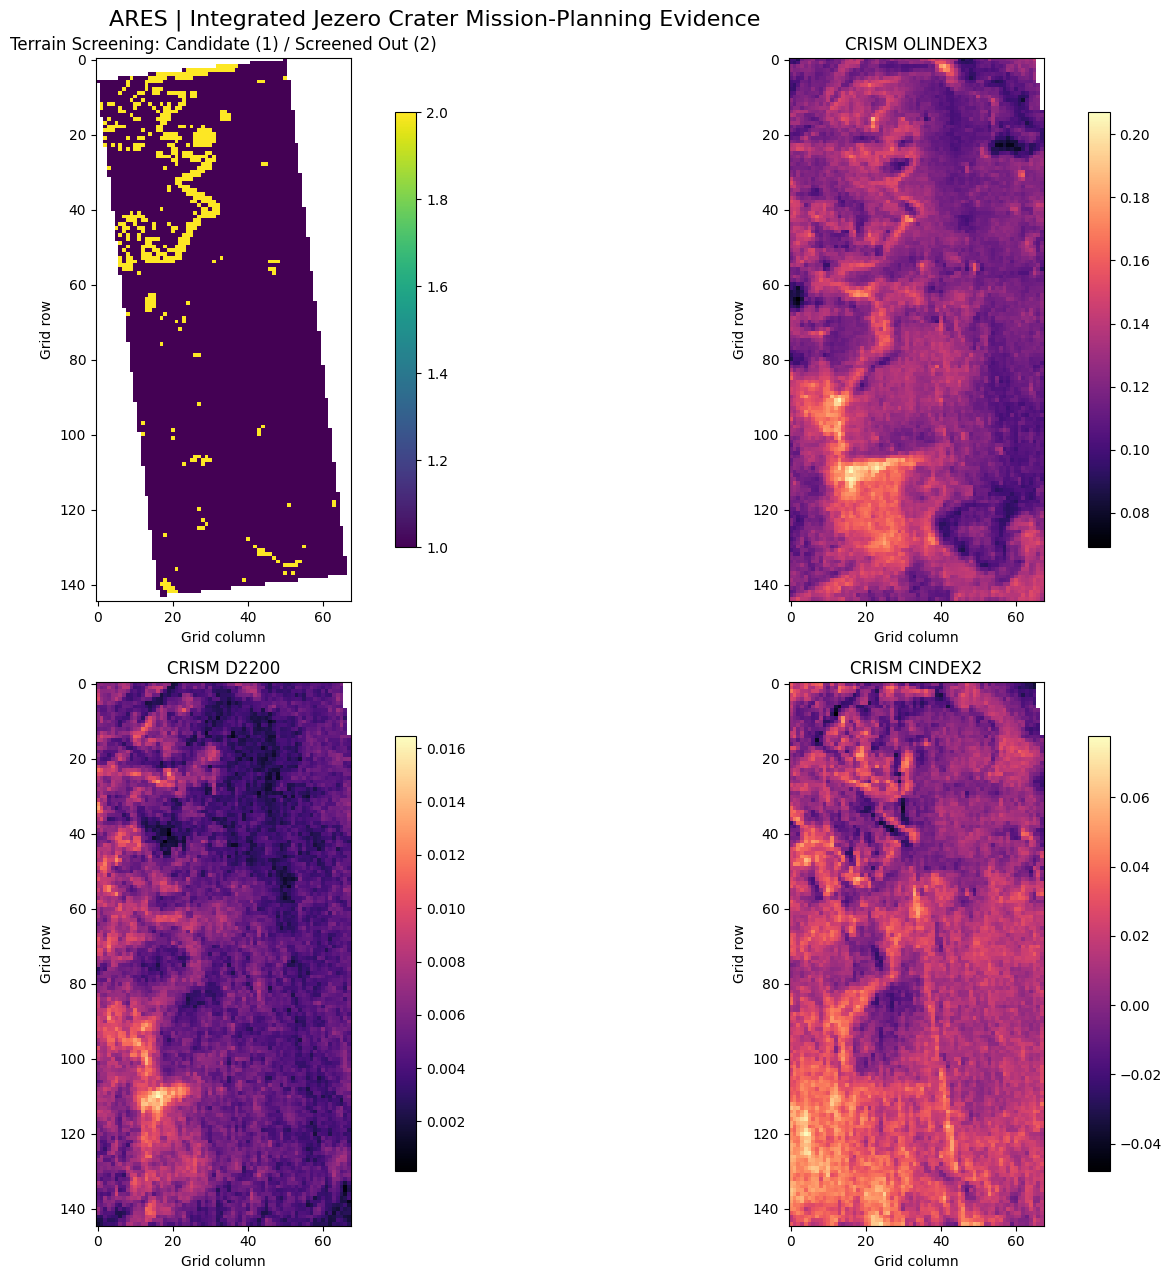


Saved integrated map: /kaggle/working/ares_data/ares_integrated_mission_evidence.png
Saved evidence table: /kaggle/working/ares_data/ares_integrated_evidence_table.csv

Integrated evidence products generated successfully.


In [37]:
import os
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

DATA_DIR = "/kaggle/working/ares_data"

# ------------------------------------------------------------
# VERIFY REQUIRED INPUTS
# ------------------------------------------------------------

required_files = {
    "Terrain screening": "ares_corridor_candidates.tif",
    "CRISM contrast table": "ares_crism_spectral_contrast.csv",
    "Terrain distribution": "hirise_slope_classes.tif"
}

for label, filename in required_files.items():
    path = os.path.join(DATA_DIR, filename)
    if not os.path.exists(path):
        raise FileNotFoundError(f"{label} missing: {path}")

# Require the Section 9.13 arrays to remain in memory.
for variable in ["aggregated", "terrain", "terrain_valid"]:
    if variable not in globals():
        raise RuntimeError(
            f"{variable} is missing. Rerun Section 9.13 first."
        )

# ------------------------------------------------------------
# LOAD TERRAIN AND CRISM RESULTS
# ------------------------------------------------------------

corridor_path = os.path.join(
    DATA_DIR, "ares_corridor_candidates.tif"
)

with rasterio.open(corridor_path) as src:
    corridor = src.read(1)
    corridor_valid = src.read_masks(1) > 0
    corridor_transform = src.transform
    corridor_bounds = src.bounds

contrast = pd.read_csv(
    os.path.join(DATA_DIR, "ares_crism_spectral_contrast.csv")
)

candidate_count = int(
    (corridor_valid & (corridor == 1)).sum()
)
screened_count = int(
    (corridor_valid & (corridor == 2)).sum()
)

# ------------------------------------------------------------
# BUILD QUANTITATIVE EVIDENCE TABLE
# ------------------------------------------------------------

evidence = []

evidence.append({
    "Evidence category": "Terrain screening",
    "Metric": "Candidate cells",
    "Result": candidate_count,
    "Unit": "100 m grid cells",
    "Interpretation": "Project-defined terrain candidates"
})

evidence.append({
    "Evidence category": "Terrain screening",
    "Metric": "Screened-out cells",
    "Result": screened_count,
    "Unit": "100 m grid cells",
    "Interpretation": "Failed one or more screening criteria"
})

evidence.append({
    "Evidence category": "Terrain screening",
    "Metric": "Candidate share",
    "Result": round(
        100 * candidate_count /
        (candidate_count + screened_count), 2
    ),
    "Unit": "%",
    "Interpretation": "Share of sufficiently covered terrain cells"
})

for _, row in contrast.iterrows():
    evidence.append({
        "Evidence category": "CRISM spectral context",
        "Metric": row["Parameter"] + " median difference",
        "Result": round(float(row["Median difference"]), 6),
        "Unit": "CRISM parameter units",
        "Interpretation": (
            "Candidate median minus screened-out median"
        )
    })

evidence_table = pd.DataFrame(evidence)

print("=" * 72)
print("ARES | INTEGRATED MISSION-PLANNING EVIDENCE")
print("=" * 72)
display(evidence_table)

# ------------------------------------------------------------
# INTEGRATED SPATIAL EVIDENCE MAP
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(16, 13))

# Panel 1: Terrain candidate classification
terrain_display = np.where(
    corridor_valid,
    corridor,
    np.nan
)

im0 = axes[0, 0].imshow(
    terrain_display,
    cmap="viridis",
    vmin=1,
    vmax=2,
    interpolation="nearest"
)
axes[0, 0].set_title(
    "Terrain Screening: Candidate (1) / Screened Out (2)"
)
axes[0, 0].set_xlabel("Grid column")
axes[0, 0].set_ylabel("Grid row")
fig.colorbar(im0, ax=axes[0, 0], shrink=0.8)

# Panel 2: CRISM OLINDEX3
im1 = axes[0, 1].imshow(
    aggregated["OLINDEX3"],
    cmap="magma",
    interpolation="nearest"
)
axes[0, 1].set_title("CRISM OLINDEX3")
axes[0, 1].set_xlabel("Grid column")
axes[0, 1].set_ylabel("Grid row")
fig.colorbar(im1, ax=axes[0, 1], shrink=0.8)

# Panel 3: CRISM D2200
im2 = axes[1, 0].imshow(
    aggregated["D2200"],
    cmap="magma",
    interpolation="nearest"
)
axes[1, 0].set_title("CRISM D2200")
axes[1, 0].set_xlabel("Grid column")
axes[1, 0].set_ylabel("Grid row")
fig.colorbar(im2, ax=axes[1, 0], shrink=0.8)

# Panel 4: CRISM CINDEX2
im3 = axes[1, 1].imshow(
    aggregated["CINDEX2"],
    cmap="magma",
    interpolation="nearest"
)
axes[1, 1].set_title("CRISM CINDEX2")
axes[1, 1].set_xlabel("Grid column")
axes[1, 1].set_ylabel("Grid row")
fig.colorbar(im3, ax=axes[1, 1], shrink=0.8)

fig.suptitle(
    "ARES | Integrated Jezero Crater Mission-Planning Evidence",
    fontsize=16
)

plt.tight_layout()

map_path = os.path.join(
    DATA_DIR,
    "ares_integrated_mission_evidence.png"
)

plt.savefig(map_path, dpi=200, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# SAVE TABLE AND SUMMARY
# ------------------------------------------------------------

table_path = os.path.join(
    DATA_DIR,
    "ares_integrated_evidence_table.csv"
)

evidence_table.to_csv(table_path, index=False)

print("\nSaved integrated map:", map_path)
print("Saved evidence table:", table_path)

print("\nIntegrated evidence products generated successfully.")


### Step 25 — Final Mission-Planning Assessment

This section consolidates the terrain screening, regional connectivity, and CRISM spectral comparison into a final evidence-based assessment.

ARES identifies preliminary terrain candidates using project-defined slope and coverage criteria. CRISM parameters provide complementary geological context. These results support exploration planning and further investigation; they do not certify landing sites or traversable routes.


ARES | FINAL MISSION-PLANNING RESULTS

TABLE 1 | MISSION SUMMARY
                              Metric      Result             Unit
             Candidate terrain cells   6522.0000 100 m grid cells
          Screened-out terrain cells    517.0000 100 m grid cells
           Sufficient-coverage cells   7039.0000 100 m grid cells
                     Candidate share     92.6600                %
                  Screened-out share      7.3400                %
Largest 8-connected candidate region   6517.0000            cells
Largest 4-connected candidate region   6505.0000            cells
     CRISM quality-controlled pixels 220978.0000           pixels
        HiRISE terrain analysis area     71.5417              km²

TABLE 2 | TERRAIN DISTRIBUTION
Terrain class Slope range  Area (km²)  Share (%)
 Low gradient        0–5°    50.46616     70.541
     Moderate      >5–15°    18.76192     26.225
        Steep     >15–25°     1.87375      2.619
   Very steep        >25°     0.43983      0.61

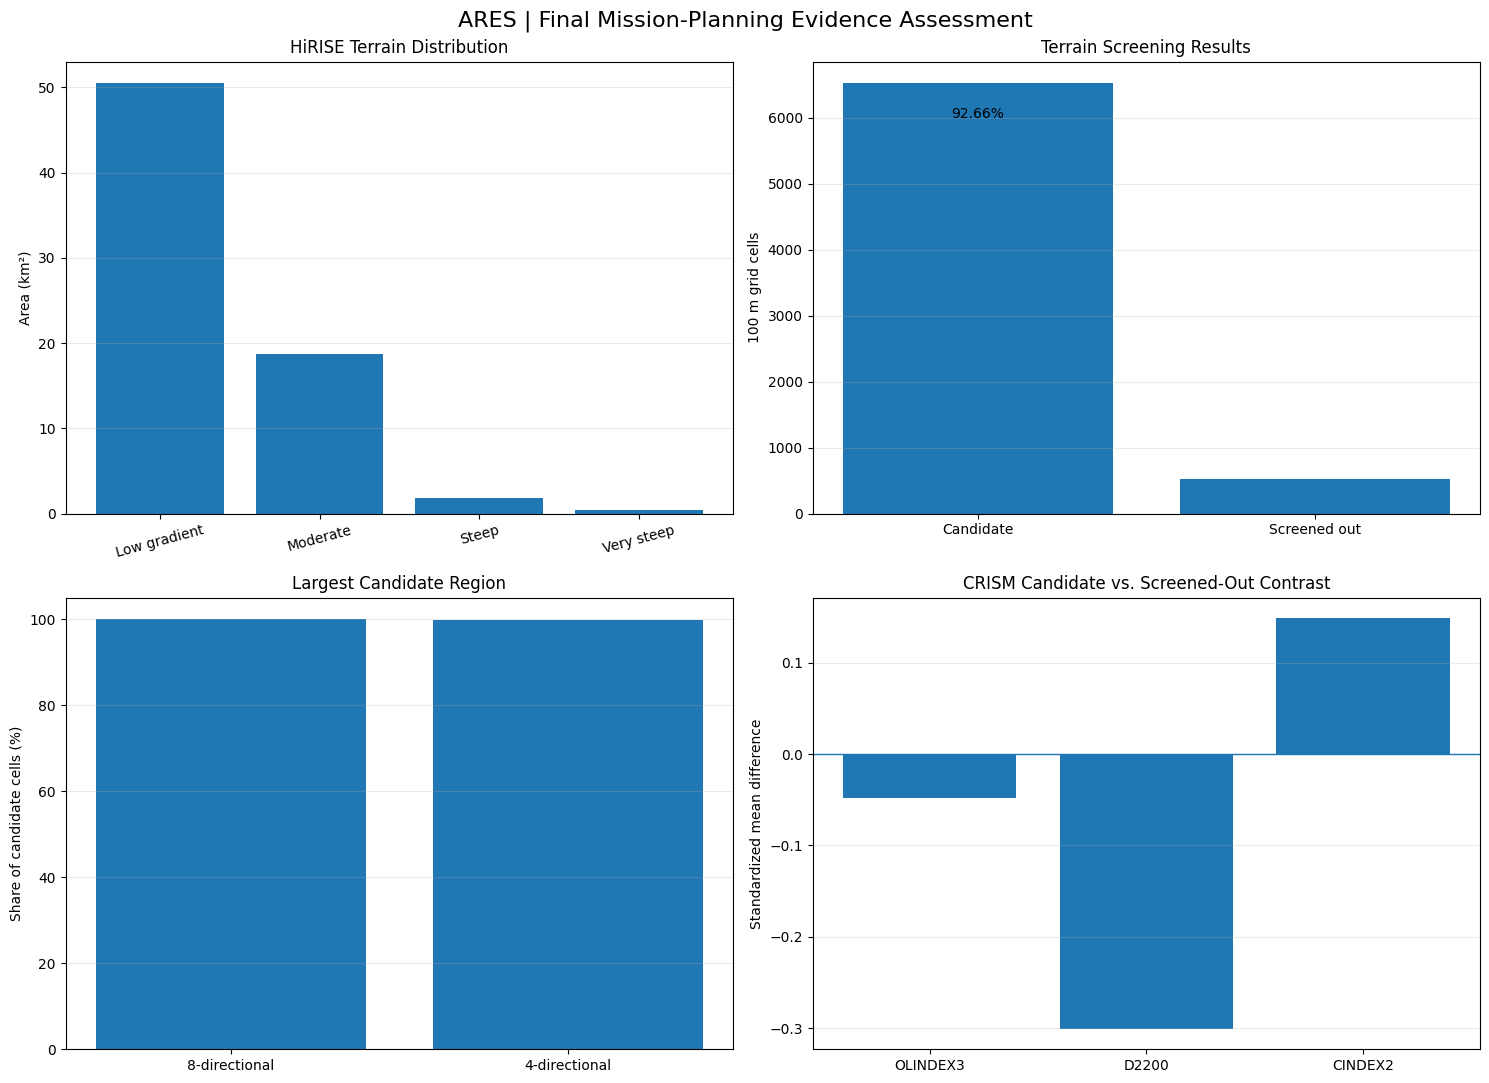


FINAL ASSESSMENT PRODUCTS SAVED
/kaggle/working/ares_data/ares_final_mission_assessment.png
ares_final_mission_summary.csv
ares_final_terrain_distribution.csv
ares_final_connectivity.csv
ares_final_crism_contrast.csv


In [38]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = "/kaggle/working/ares_data"
os.makedirs(OUT, exist_ok=True)

# ---------------------------------------------------------
# 1. Consolidated quantitative findings
# ---------------------------------------------------------

terrain_classes = pd.DataFrame({
    "Terrain class": ["Low gradient", "Moderate", "Steep", "Very steep"],
    "Slope range": ["0–5°", ">5–15°", ">15–25°", ">25°"],
    "Area (km²)": [50.46616, 18.76192, 1.87375, 0.43983],
    "Share (%)": [70.541, 26.225, 2.619, 0.615]
})

connectivity = pd.DataFrame({
    "Connectivity": ["8-directional", "4-directional"],
    "Regions": [4, 14],
    "Largest region (cells)": [6517, 6505],
    "Largest region (%)": [99.923, 99.739]
})

crism = pd.DataFrame({
    "Parameter": ["OLINDEX3", "D2200", "CINDEX2"],
    "Standardized mean difference": [-0.048439, -0.300744, 0.148984],
    "Median difference": [-0.003205, -0.000735, 0.000955]
})

candidate_cells = 6522
screened_cells = 517
sufficient_cells = candidate_cells + screened_cells
candidate_share = candidate_cells / sufficient_cells * 100
screened_share = screened_cells / sufficient_cells * 100

summary = pd.DataFrame([
    ["Candidate terrain cells", candidate_cells, "100 m grid cells"],
    ["Screened-out terrain cells", screened_cells, "100 m grid cells"],
    ["Sufficient-coverage cells", sufficient_cells, "100 m grid cells"],
    ["Candidate share", round(candidate_share, 2), "%"],
    ["Screened-out share", round(screened_share, 2), "%"],
    ["Largest 8-connected candidate region", 6517, "cells"],
    ["Largest 4-connected candidate region", 6505, "cells"],
    ["CRISM quality-controlled pixels", 220978, "pixels"],
    ["HiRISE terrain analysis area", 71.5417, "km²"]
], columns=["Metric", "Result", "Unit"])

print("=" * 72)
print("ARES | FINAL MISSION-PLANNING RESULTS")
print("=" * 72)
print("\nTABLE 1 | MISSION SUMMARY")
print(summary.to_string(index=False))

print("\nTABLE 2 | TERRAIN DISTRIBUTION")
print(terrain_classes.to_string(index=False))

print("\nTABLE 3 | CONNECTIVITY ROBUSTNESS")
print(connectivity.to_string(index=False))

print("\nTABLE 4 | CRISM SPECTRAL CONTRAST")
print(crism.to_string(index=False))

# ---------------------------------------------------------
# 2. Integrated final assessment visualization
# ---------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Terrain distribution
axes[0, 0].bar(
    terrain_classes["Terrain class"],
    terrain_classes["Area (km²)"]
)
axes[0, 0].set_title("HiRISE Terrain Distribution")
axes[0, 0].set_ylabel("Area (km²)")
axes[0, 0].tick_params(axis="x", rotation=15)
axes[0, 0].grid(axis="y", alpha=0.25)

# Candidate screening
axes[0, 1].bar(
    ["Candidate", "Screened out"],
    [candidate_cells, screened_cells]
)
axes[0, 1].set_title("Terrain Screening Results")
axes[0, 1].set_ylabel("100 m grid cells")
axes[0, 1].text(
    0, candidate_cells * 0.92,
    f"{candidate_share:.2f}%",
    ha="center"
)
axes[0, 1].grid(axis="y", alpha=0.25)

# Connectivity robustness
axes[1, 0].bar(
    connectivity["Connectivity"],
    connectivity["Largest region (%)"]
)
axes[1, 0].set_title("Largest Candidate Region")
axes[1, 0].set_ylabel("Share of candidate cells (%)")
axes[1, 0].set_ylim(0, 105)
axes[1, 0].grid(axis="y", alpha=0.25)

# CRISM standardized differences
axes[1, 1].bar(
    crism["Parameter"],
    crism["Standardized mean difference"]
)
axes[1, 1].axhline(0, linewidth=1)
axes[1, 1].set_title("CRISM Candidate vs. Screened-Out Contrast")
axes[1, 1].set_ylabel("Standardized mean difference")
axes[1, 1].grid(axis="y", alpha=0.25)

fig.suptitle(
    "ARES | Final Mission-Planning Evidence Assessment",
    fontsize=16
)
plt.tight_layout()

figure_path = os.path.join(
    OUT, "ares_final_mission_assessment.png"
)
plt.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------
# 3. Export final tables
# ---------------------------------------------------------

summary.to_csv(
    os.path.join(OUT, "ares_final_mission_summary.csv"),
    index=False
)
terrain_classes.to_csv(
    os.path.join(OUT, "ares_final_terrain_distribution.csv"),
    index=False
)
connectivity.to_csv(
    os.path.join(OUT, "ares_final_connectivity.csv"),
    index=False
)
crism.to_csv(
    os.path.join(OUT, "ares_final_crism_contrast.csv"),
    index=False
)

print("\n" + "=" * 72)
print("FINAL ASSESSMENT PRODUCTS SAVED")
print("=" * 72)
print(figure_path)
print("ares_final_mission_summary.csv")
print("ares_final_terrain_distribution.csv")
print("ares_final_connectivity.csv")
print("ares_final_crism_contrast.csv")



### Step 26 — ARES Integrated Surface Map Atlas

This visual atlas presents the spatial evidence used by ARES for the Jezero Crater study area. It combines high-resolution orbital terrain products, regional elevation context, terrain screening, and CRISM spectral parameters.

Each panel represents a distinct data layer. The maps are intended to support visual comparison and mission-planning research, not to certify a human-traversable route.


CRISM spatial layers recovered: ['OLINDEX3', 'D2200', 'CINDEX2']

ARES | VISUAL ATLAS DATA INVENTORY


,Layer,Rows,Columns,CRS
0,hillshade,14266,6673,"PROJCS[""EQUIRECTANGULAR MARS"",GEOGCS[""GCS_MARS..."
1,slope,14266,6673,"PROJCS[""EQUIRECTANGULAR MARS"",GEOGCS[""GCS_MARS..."
2,classes,14266,6673,"PROJCS[""EQUIRECTANGULAR MARS"",GEOGCS[""GCS_MARS..."
3,corridor,145,68,"PROJCS[""EQUIRECTANGULAR MARS"",GEOGCS[""GCS_MARS..."
4,mola,32,16,"PROJCS[""EQUIRECTANGULAR MARS"",GEOGCS[""GCS_MARS..."
5,CRISM OLINDEX3,145,68,Registered to ARES terrain grid
6,CRISM D2200,145,68,Registered to ARES terrain grid
7,CRISM CINDEX2,145,68,Registered to ARES terrain grid


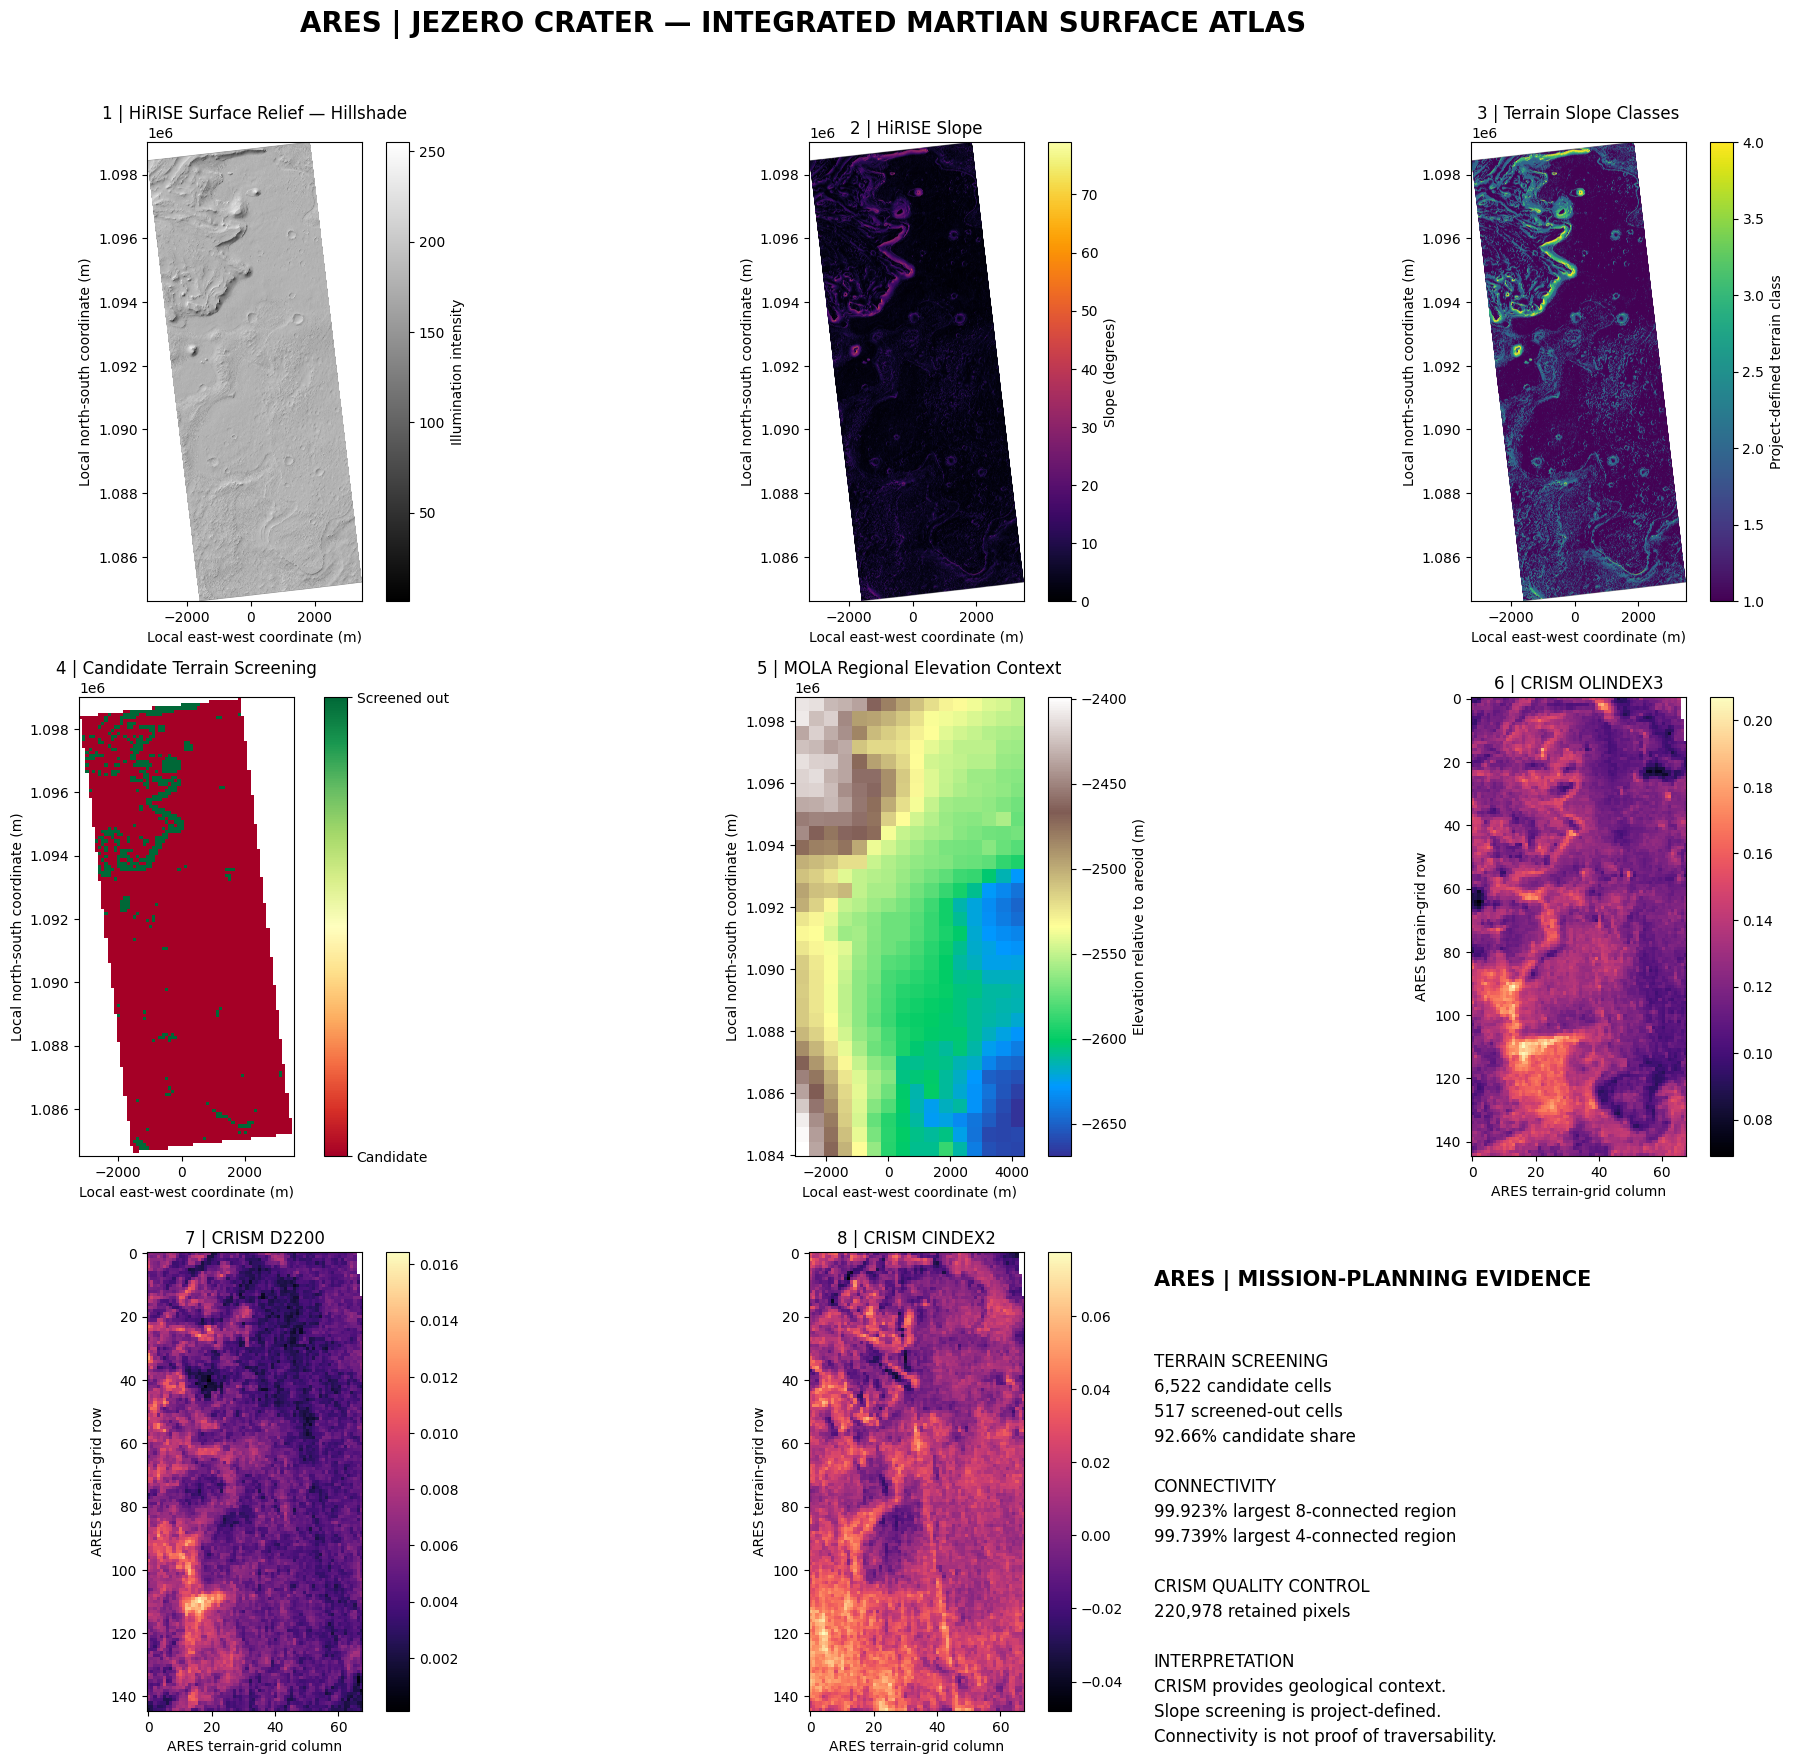


Full visual atlas saved to:
/kaggle/working/ares_data/ARES_integrated_surface_atlas.png


In [39]:

import os
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from rasterio.plot import plotting_extent

OUT = "/kaggle/working/ares_data"

# ---------------------------------------------------------
# 1. Load actual spatial datasets
# ---------------------------------------------------------

files = {
    "hillshade": "hirise_hillshade.tif",
    "slope": "hirise_slope_degrees.tif",
    "classes": "hirise_slope_classes.tif",
    "corridor": "ares_corridor_candidates.tif",
    "mola": "mola_jezero_hirise_registered.tif"
}

rasters = {}
for name, filename in files.items():
    path = os.path.join(OUT, filename)
    if os.path.exists(path):
        with rasterio.open(path) as src:
            rasters[name] = {
                "array": src.read(1, masked=True),
                "extent": plotting_extent(src),
                "transform": src.transform,
                "crs": str(src.crs),
                "shape": (src.height, src.width)
            }
    else:
        print("MISSING:", filename)

# ---------------------------------------------------------
# 2. Retrieve CRISM spatial aggregates
# ---------------------------------------------------------

crism_layers = {}
wanted = ["OLINDEX3", "D2200", "CINDEX2"]

if "aggregated" in globals():
    for key in wanted:
        if isinstance(aggregated, dict):
            match = next(
                (k for k in aggregated
                 if str(k).upper() == key),
                None
            )
            if match is not None:
                crism_layers[key] = np.asarray(aggregated[match])

print("CRISM spatial layers recovered:", list(crism_layers))

# ---------------------------------------------------------
# 3. Print layer inventory
# ---------------------------------------------------------

inventory = []
for name, item in rasters.items():
    inventory.append({
        "Layer": name,
        "Rows": item["shape"][0],
        "Columns": item["shape"][1],
        "CRS": item["crs"]
    })

for name, array in crism_layers.items():
    inventory.append({
        "Layer": "CRISM " + name,
        "Rows": array.shape[0],
        "Columns": array.shape[1],
        "CRS": "Registered to ARES terrain grid"
    })

print("\nARES | VISUAL ATLAS DATA INVENTORY")
display(pd.DataFrame(inventory))

# ---------------------------------------------------------
# 4. Render nine actual data views
# ---------------------------------------------------------

fig, axes = plt.subplots(3, 3, figsize=(20, 18))
axes = axes.ravel()

def show_raster(ax, name, title, cmap, label):
    if name not in rasters:
        ax.set_title(title + " — unavailable")
        ax.axis("off")
        return

    item = rasters[name]
    im = ax.imshow(
        item["array"],
        extent=item["extent"],
        origin="upper",
        cmap=cmap
    )
    ax.set_title(title)
    ax.set_xlabel("Local east-west coordinate (m)")
    ax.set_ylabel("Local north-south coordinate (m)")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=label)

# 1. HiRISE hillshade
show_raster(
    axes[0], "hillshade",
    "1 | HiRISE Surface Relief — Hillshade",
    "gray", "Illumination intensity"
)

# 2. Slope degrees
show_raster(
    axes[1], "slope",
    "2 | HiRISE Slope",
    "inferno", "Slope (degrees)"
)

# 3. Terrain classes
show_raster(
    axes[2], "classes",
    "3 | Terrain Slope Classes",
    "viridis", "Project-defined terrain class"
)

# 4. Candidate corridor screening
if "corridor" in rasters:
    item = rasters["corridor"]
    corridor = item["array"]
    im = axes[3].imshow(
        corridor,
        extent=item["extent"],
        origin="upper",
        cmap="RdYlGn",
        vmin=1,
        vmax=2
    )
    axes[3].set_title("4 | Candidate Terrain Screening")
    axes[3].set_xlabel("Local east-west coordinate (m)")
    axes[3].set_ylabel("Local north-south coordinate (m)")
    cbar = plt.colorbar(im, ax=axes[3], ticks=[1, 2])
    cbar.ax.set_yticklabels(["Candidate", "Screened out"])
else:
    axes[3].set_title("Candidate screening unavailable")
    axes[3].axis("off")

# 5. MOLA regional elevation
show_raster(
    axes[4], "mola",
    "5 | MOLA Regional Elevation Context",
    "terrain", "Elevation relative to areoid (m)"
)

# 6–8. CRISM spectral parameter maps
for ax, key, title in zip(
    axes[5:8],
    wanted,
    [
        "6 | CRISM OLINDEX3",
        "7 | CRISM D2200",
        "8 | CRISM CINDEX2"
    ]
):
    if key in crism_layers:
        arr = np.ma.masked_invalid(crism_layers[key])
        im = ax.imshow(arr, origin="upper", cmap="magma")
        ax.set_title(title)
        ax.set_xlabel("ARES terrain-grid column")
        ax.set_ylabel("ARES terrain-grid row")
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    else:
        ax.set_title(title + " — aggregate unavailable")
        ax.text(
            0.5, 0.5,
            "CRISM aggregate not found in memory",
            ha="center", va="center",
            transform=ax.transAxes
        )
        ax.axis("off")

# 9. Integrated screening and spectral context
axes[8].axis("off")
axes[8].text(
    0.02, 0.96,
    "ARES | MISSION-PLANNING EVIDENCE",
    fontsize=15, weight="bold", va="top"
)
axes[8].text(
    0.02, 0.78,
    "TERRAIN SCREENING\n"
    "6,522 candidate cells\n"
    "517 screened-out cells\n"
    "92.66% candidate share\n\n"
    "CONNECTIVITY\n"
    "99.923% largest 8-connected region\n"
    "99.739% largest 4-connected region\n\n"
    "CRISM QUALITY CONTROL\n"
    "220,978 retained pixels\n\n"
    "INTERPRETATION\n"
    "CRISM provides geological context.\n"
    "Slope screening is project-defined.\n"
    "Connectivity is not proof of traversability.",
    fontsize=12, va="top", linespacing=1.5
)

fig.suptitle(
    "ARES | JEZERO CRATER — INTEGRATED MARTIAN SURFACE ATLAS",
    fontsize=20, weight="bold", y=0.995
)
plt.tight_layout(rect=[0, 0, 1, 0.975])

atlas_path = os.path.join(OUT, "ARES_integrated_surface_atlas.png")
plt.savefig(atlas_path, dpi=220, bbox_inches="tight")
plt.show()

print("\nFull visual atlas saved to:")
print(atlas_path)


---
# PART 5 — The EVA route planner
Everything so far describes the place. This part plans a **walk**.

**Method**
1. **Plan at 10 m.** Elevation is averaged to 10 m cells; slope is recomputed at that scale. A **hazard fraction** (share of 1 m pixels steeper than 25°) acts as a boulder / scarp proxy.
2. **No-go zones.** Cells above the slope limit, above the hazard limit, or without data are impassable.
3. **Cost of walking.** Passable cells get a **relative metabolic cost** of slope following the walking-energy polynomial of Minetti et al. (2002), averaged over uphill and downhill, plus a hazard penalty.
4. **Science stops.** The highest smoothed CRISM index values inside candidate terrain, within the EVA radius of the habitat: olivine-index, hydrated-silicate (2.2 µm) and carbonate-index peaks.
5. **Habitat.** The flattest passable cell near the centre of the candidate terrain.
6. **Route.** Least-cost path habitat → stops → habitat. If the EVA would exceed the limit, the farthest stop is dropped until it fits.

**Planning assumptions (project choices, not NASA values)**

| Assumption | Value |
|---|---|
| Slope no-go | 20° |
| Hazard no-go | 25 % of 1 m pixels steeper than 25° |
| Flat-ground planning speed | 3 km/h, scaled by relative cost |
| Time at each science stop | 20 min |
| EVA limit | 8 h |
| EVA radius from habitat | 2.5 km |
| Radiation reference rate | 0.64 mSv/day (published surface value from the MSL RAD instrument; **not measured at Jezero by this notebook**) |

Suit mass, Mars gravity, dust, soil and rock-scale obstacles below the DTM resolution are **not** modelled.


In [ ]:
# ================================================================
# ARES | EVA ROUTE PLANNER  (Section 10)
# Builds: 10 m traversability grid -> science waypoints -> least-cost
# EVA loop -> route map, elevation profile, EVA budget JSON.
# ================================================================
import os, json, math
import numpy as np, pandas as pd, rasterio
import matplotlib; import matplotlib.pyplot as plt
from rasterio.enums import Resampling
from scipy.ndimage import uniform_filter
from skimage.graph import route_through_array

ARES_DIR = globals().get("ARES_DIR_OVERRIDE", "/kaggle/working/ares_data")
P = lambda n: os.path.join(ARES_DIR, n)
K = 10                                    # 1 m -> ~10 m planning grid

# ---- project assumptions (shown on the slides as ASSUMED) ----
A = dict(max_slope_deg=20.0, max_hazard_frac=0.25, flat_speed_kmh=3.0,
         stop_minutes=20, eva_limit_h=8.0, rad_msv_per_day=0.64)

# ---- 1. read 1 m rasters, reduce to 10 m ----
with rasterio.open(P("hirise_jezero_dtm.tif")) as d:
    dtm = d.read(1); T = d.transform; RES = abs(T.a)
with rasterio.open(P("hirise_slope_degrees.tif")) as d:
    s1 = d.read(1)
H, W = dtm.shape; h, w = H // K, W // K
dv = (dtm > -1e5)
n = dv[:h*K, :w*K].reshape(h, K, w, K).sum((1, 3))
elev = np.where(dv, dtm, 0)[:h*K, :w*K].reshape(h, K, w, K).sum((1, 3)) / np.maximum(n, 1)
ok = n >= 0.8 * K * K
elev[~ok] = np.nan
sv = (s1 >= 0) & (s1 <= 90)
haz = ((s1 > 25) & sv)[:h*K, :w*K].reshape(h, K, w, K).mean((1, 3)).astype(np.float32)
del dtm, s1, dv, sv
cs = K * RES                              # 10 m cell size
fill = np.where(ok, elev, np.nanmedian(elev))
gy, gx = np.gradient(fill, cs)
slope = np.degrees(np.arctan(np.hypot(gx, gy))).astype(np.float32)
slope[~ok] = np.nan
X0, Y0 = T.c, T.f
cx = lambda j: X0 + (j + .5) * cs
cy = lambda i: Y0 - (i + .5) * cs

# ---- 2. traversability cost (relative metabolic weighting) ----
g = np.tan(np.radians(np.nan_to_num(slope, nan=90)))
g = np.clip(g, 0, 0.45)
rel = (2.5 + 51.9 * g**2 - 58.7 * g**4) / 2.5     # Minetti 2002, up/down averaged
cost = rel + 20 * haz
blocked = (~ok) | (slope > A["max_slope_deg"]) | (haz > A["max_hazard_frac"])
cost = np.where(blocked, np.inf, cost).astype(np.float64)
print(f"Planning grid {h}x{w} @ {cs:.2f} m | passable {100*np.isfinite(cost).mean():.1f}%")

# ---- 3. science waypoints from CRISM aggregates (100 m grid) ----
with rasterio.open(P("ares_corridor_candidates.tif")) as d:
    cand = d.read(1) == 1; Tc = d.transform
agg_path = P("crism_aggregated.npz")
if os.path.exists(agg_path):
    agg = dict(np.load(agg_path))
elif "aggregated" in globals():
    agg = {k: np.asarray(v) for k, v in aggregated.items()}
else:
    raise RuntimeError("CRISM aggregates not found - run the CRISM integration cell first.")

def cell_to_grid(r, c):
    x = Tc.c + (c + .5) * 100; y = Tc.f - (r + .5) * 100
    return int((Y0 - y) / cs), int((x - X0) / cs)

def passable(i, j):
    return 0 <= i < h and 0 <= j < w and np.isfinite(cost[i, j])

LAB = {"OLINDEX3": ("Olivine-index peak", "#ff7f0e"),
       "D2200": ("Hydrated-silicate (2.2 µm) peak", "#2ca02c"),
       "CINDEX2": ("Carbonate-index peak", "#d62728")}
A["max_radius_m"] = 2500          # assumed EVA radius from habitat

# habitat first: flattest passable cell near the centre of the candidate terrain
rr, cc = np.where(cand)
hi0, hj0 = cell_to_grid(int(rr.mean()), int(cc.mean()))
win = (slice(max(0, hi0-120), hi0+120), slice(max(0, hj0-120), hj0+120))
sl = np.where(np.isfinite(cost[win]), slope[win], np.inf)
a, b = np.unravel_index(np.argmin(sl), sl.shape)
hab = dict(name="Habitat / landing zone", i=win[0].start + a, j=win[1].start + b)

targets, used = [], [(hab["i"], hab["j"])]
for key, (label, colr) in LAB.items():
    arr = agg[key].astype(float)
    arr[~cand] = np.nan
    fin = np.where(np.isfinite(arr), arr, np.nanmedian(arr))
    sm = uniform_filter(fin, 3)
    z = (sm - np.nanmean(sm[cand])) / (np.nanstd(sm[cand]) + 1e-9)
    z[~cand] = -np.inf
    for idx in np.argsort(z, axis=None)[::-1]:
        r, c = np.unravel_index(idx, z.shape)
        if not np.isfinite(z[r, c]): break
        i, j = cell_to_grid(r, c)
        if (passable(i, j)
                and math.hypot(i-hab["i"], j-hab["j"]) * cs <= A["max_radius_m"]
                and all(math.hypot(i-a_, j-b_) * cs > 500 for a_, b_ in used[1:])):
            targets.append(dict(name=label, key=key, color=colr, i=i, j=j,
                                zscore=float(z[r, c]), value=float(arr[r, c])))
            used.append((i, j)); break
if not targets:
    raise RuntimeError("No passable science waypoint within the EVA radius.")

# ---- 4. least-cost EVA loop; drop farthest stop until the EVA fits ----
def plan(order):
    stops = [hab] + order + [hab]
    path = []
    for a_, b_ in zip(stops[:-1], stops[1:]):
        seg, _ = route_through_array(cost, (a_["i"], a_["j"]), (b_["i"], b_["j"]),
                                     fully_connected=True, geometric=True)
        path += seg if not path else seg[1:]
    pi = np.array([p[0] for p in path]); pj = np.array([p[1] for p in path])
    step = np.hypot(np.diff(pi), np.diff(pj)) * cs
    rc = rel[pi, pj] + 20 * haz[pi, pj]
    t_walk = float(np.sum(step / 1000 / A["flat_speed_kmh"] * rc[1:]))
    return stops, pi, pj, step, rc, t_walk + A["stop_minutes"] * len(order) / 60, t_walk

order, cur, left = [], hab, targets[:]
while left:
    nxt = min(left, key=lambda t_: math.hypot(t_["i"]-cur["i"], t_["j"]-cur["j"]))
    order.append(nxt); left.remove(nxt); cur = nxt
dropped = []
while True:
    stops, pi, pj, step, rc, t_total, t_walk = plan(order)
    if t_total <= A["eva_limit_h"] or len(order) == 1: break
    far = max(order, key=lambda t_: math.hypot(t_["i"]-hab["i"], t_["j"]-hab["j"]))
    order.remove(far); dropped.append(far["name"])
if dropped: print("Dropped to fit EVA limit:", dropped)
dist = np.concatenate([[0], np.cumsum(step)])
back = np.minimum(dist, dist[-1] - dist)
dose = A["rad_msv_per_day"] * t_total / 24
budget = dict(
    route_length_km=round(dist[-1] / 1000, 2),
    walking_hours=round(t_walk, 2), total_eva_hours=round(t_total, 2),
    eva_limit_hours=A["eva_limit_h"], within_eva_limit=bool(t_total <= A["eva_limit_h"]),
    max_slope_on_route_deg=round(float(np.nanmax(slope[pi, pj])), 1),
    mean_slope_on_route_deg=round(float(np.nanmean(slope[pi, pj])), 1),
    max_walkback_km=round(float(back.max()) / 1000, 2),
    elevation_gain_m=round(float(np.nansum(np.clip(np.diff(elev[pi, pj]), 0, None))), 1),
    eva_dose_mSv_reference_rate=round(dose, 3),
    stops_dropped_for_eva_limit=dropped,
    targets=[dict(name=t_["name"], zscore=round(t_["zscore"], 2),
                  east_m=round(cx(t_["j"]), 1), north_m=round(cy(t_["i"]), 1)) for t_ in order],
    assumptions=A)
json.dump(budget, open(P("ares_eva_route_budget.json"), "w"), indent=2)
print(json.dumps({k: v for k, v in budget.items() if k not in ("targets", "assumptions")}, indent=2))

# ---- 5. basemap (HiRISE orthoimage, fallback hillshade) ----
base, ext = None, None
for fn in ("hirise_jezero_ortho.jp2", "hirise_hillshade.tif"):
    try:
        with rasterio.open(P(fn)) as d:
            sh = (d.height // 4, d.width // 4)
            base = d.read(1, out_shape=sh, resampling=Resampling.average).astype(float)
            b_ = d.bounds; ext = [b_.left, b_.right, b_.bottom, b_.top]
        break
    except Exception as e:
        print("basemap fallback:", fn, str(e)[:80])
lo, hi = np.percentile(base[base > 0], [2, 98]) if (base > 0).any() else (0, 255)
EX = [cx(0) - cs/2, cx(w-1) + cs/2, cy(h-1) - cs/2, cy(0) + cs/2]

# ---- 6. route map ----
fig, ax = plt.subplots(figsize=(5.2, 10.6), dpi=170)
ax.imshow(base, cmap="gray", vmin=lo, vmax=hi, extent=ext, origin="upper")
bl = np.ma.masked_where(~blocked, np.ones_like(slope))
ax.imshow(bl, cmap="autumn", alpha=.45, extent=EX, origin="upper", interpolation="nearest")
ax.plot(cx(pj), cy(pi), color="#00e5ff", lw=2.2, label="Planned EVA loop")
mk = lambda t_: (cx(t_["j"]), cy(t_["i"]))
ax.scatter(*mk(hab), marker="s", s=140, c="white", edgecolors="k", zorder=5, label="Habitat")
for n_, t_ in enumerate(order, 1):
    ax.scatter(*mk(t_), marker="*", s=420, c=t_["color"], edgecolors="k", zorder=6)
    ax.annotate(f"{n_}", mk(t_), color="white", weight="bold", fontsize=11,
                xytext=(10, 6), textcoords="offset points", zorder=7)
ax.set_xlim(EX[0], EX[1]); ax.set_ylim(EX[2], EX[3])
ax.set_title("ARES EVA route - Jezero Crater\nred = no-go (slope/hazard)", fontsize=11)
ax.set_xlabel("Local east (m)"); ax.set_ylabel("Local north (m)")
ax.legend(loc="lower right", fontsize=7)
plt.tight_layout(); plt.savefig(P("ares_route_map.png"), bbox_inches="tight"); plt.show()

# ---- 7. elevation + slope profile ----
fig, ax = plt.subplots(2, 1, figsize=(11, 5.2), dpi=170, sharex=True)
ax[0].fill_between(dist/1000, elev[pi, pj], np.nanmin(elev[pi, pj]) - 2, color="#8d6e63")
ax[0].set_ylabel("Elevation (m)")
ax[0].set_title("Route elevation and slope profile (10 m HiRISE-derived)")
ax[1].plot(dist/1000, slope[pi, pj], color="#ff6f00")
ax[1].axhline(A["max_slope_deg"], color="r", ls="--", lw=1, label="no-go limit (assumed)")
ax[1].set_ylabel("Slope (deg)"); ax[1].set_xlabel("Distance along route (km)"); ax[1].legend()
for n_, t_ in enumerate(order, 1):
    k_ = int(np.argmin(np.hypot(pi - t_["i"], pj - t_["j"])))
    for a_ in ax: a_.axvline(dist[k_]/1000, color=t_["color"], lw=1.5)
    ax[0].text(dist[k_]/1000, ax[0].get_ylim()[1], f" {n_}", va="top", weight="bold")
plt.tight_layout(); plt.savefig(P("ares_route_profile.png"), bbox_inches="tight"); plt.show()
pd.DataFrame(budget["targets"]).to_csv(P("ares_route_targets.csv"), index=False)
print("Saved route map, profile, budget JSON.")


---
# PART 5B — Ground truth from NASA's Mars 2020 Perseverance rover
Orbital data tells us what the terrain *should* be like. Perseverance has been **driving this exact terrain since 2021**, and NASA publishes both **where it has been** and **what it saw**. This part uses two resources from the challenge's resource list, the [Mars Perseverance Raw Images Gallery](https://mars.nasa.gov/mars2020/multimedia/raw-images/) (via NASA's public raw-images feed) and the rover's public traverse waypoints, to do two things no orbital map can:

1. **Retrospective validation.** Do the places Perseverance actually chose to drive fall inside or outside ARES's no-go terrain? If the rover's waypoints keep to ARES's "go" terrain, that is independent evidence that the hazard model is sensible. If they do not, we report it.
2. **Point-of-view imagery.** For the habitat and each science stop, find the **nearest place Perseverance has been**, and show what it saw there, so a crew knows what to expect on arrival.

**Honest limits.** The rover is not a suited astronaut; its limits and speeds differ. Waypoints are end-of-drive points, not continuous paths. Each picture is the **nearest available rover view**, not a view from the exact stop, and the distance is printed under every image. Rover coordinates are treated as Mars planetocentric longitude/latitude and projected into the HiRISE frame; small registration offsets are possible. Images are courtesy NASA/JPL-Caltech and the instrument teams.


In [ ]:
# ================================================================
# ARES | PERSEVERANCE TRAVERSE vs ARES NO-GO TERRAIN
# NASA resource: Mars 2020 rover traverse waypoints (MMGIS)
# ================================================================
import os, json, math, time
import numpy as np, requests
import matplotlib.pyplot as plt

ARES_DIR = globals().get("ARES_DIR_OVERRIDE", "/kaggle/working/ares_data")
P = lambda n: os.path.join(ARES_DIR, n)
HEADERS = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) ARES-Space-Apps/1.0 (NASA Space Apps 2026)",
           "Accept": "application/json,*/*"}
M20_WAYPOINTS_URL = globals().get("M20_WAYPOINTS_URL_OVERRIDE",
    "https://mars.nasa.gov/mmgis-maps/M20/Layers/json/M20_waypoints.json")

def fetch_json(url, params=None, tries=3, timeout=(15, 90)):
    for k in range(tries):
        try:
            r = requests.get(url, params=params, headers=HEADERS, timeout=timeout)
            r.raise_for_status()
            return r.json()
        except Exception as e:
            print(f"  fetch attempt {k+1}/{tries} failed: {str(e)[:110]}")
            time.sleep(2 * (k + 1))
    return None

ROVER = {}
try:
    need = ["slope", "blocked", "cx", "cy", "X0", "Y0", "cs", "h", "w", "hab", "order", "A"]
    missing = [v for v in need if v not in globals()]
    if missing:
        raise RuntimeError("Run Part 5 (route planner) first. Missing: " + ", ".join(missing))

    print("Fetching Perseverance waypoints from NASA ...")
    gj = fetch_json(M20_WAYPOINTS_URL)
    pts, source = [], "NASA MMGIS M20_waypoints.json (live)"
    for f in (gj or {}).get("features", []):
        g = f.get("geometry") or {}
        pr = f.get("properties") or {}
        if g.get("type") == "Point" and pr.get("sol") is not None:
            lon, lat = g["coordinates"][:2]
            pts.append((float(pr["sol"]), float(lon), float(lat)))
    if not pts:
        source = "FALLBACK: first published waypoint only (sol 13, landing area); live feed unavailable"
        pts = [(13.0, 77.45095, 18.44463)]
        print("WARNING:", source)
    sol_a, lon_a, lat_a = (np.array(c) for c in zip(*pts))

    R_MARS, PHI0, LON0 = 3394839.8133163, 15.0, 77.44          # HiRISE projection
    px = R_MARS * math.cos(math.radians(PHI0)) * np.radians(lon_a - LON0)
    py = R_MARS * np.radians(lat_a)
    gj_, gi_ = (px - X0) / cs, (Y0 - py) / cs
    inside = (gi_ >= 0) & (gi_ < h) & (gj_ >= 0) & (gj_ < w)
    ii = np.clip(gi_.astype(int), 0, h - 1); jj = np.clip(gj_.astype(int), 0, w - 1)
    valid = inside & np.isfinite(slope[ii, jj])
    n_in = int(valid.sum())

    ROVER.update(px=px, py=py, sol=sol_a, valid=valid, ii=ii, jj=jj, source=source)
    report = {"source": source, "waypoints_total": int(len(pts)), "waypoints_inside_footprint": n_in}
    if n_in:
        s_at = slope[ii, jj][valid]
        area_blocked = float(blocked[np.isfinite(slope)].mean()) * 100
        rover_blocked = float(blocked[ii, jj][valid].mean()) * 100
        report.update(
            median_slope_deg=round(float(np.median(s_at)), 1),
            p90_slope_deg=round(float(np.percentile(s_at, 90)), 1),
            max_slope_deg=round(float(s_at.max()), 1),
            pct_waypoints_in_ares_nogo=round(rover_blocked, 1),
            pct_footprint_that_is_nogo=round(area_blocked, 1),
            pct_waypoints_below_slope_limit=round(float((s_at <= A["max_slope_deg"]).mean()) * 100, 1),
            sol_range=[int(sol_a[valid].min()), int(sol_a[valid].max())])
    json.dump(report, open(P("ares_rover_validation.json"), "w"), indent=2)
    json.dump({"note": "in-footprint subset of NASA M20 waypoints", "source": source,
               "points": [[float(a), float(b), float(c)] for a, b, c, v in zip(sol_a, lon_a, lat_a, valid) if v]},
              open(P("m20_waypoints_snapshot.json"), "w"))
    print(json.dumps(report, indent=2))

    # ---- overlay figure ----
    fig, ax = plt.subplots(figsize=(5.6, 10.6), dpi=170)
    if "base" in globals() and base is not None:
        ax.imshow(base, cmap="gray", vmin=lo, vmax=hi, extent=ext, origin="upper")
    ax.imshow(np.ma.masked_where(~blocked, np.ones_like(slope)), cmap="autumn", alpha=.40,
              extent=EX, origin="upper", interpolation="nearest")
    ax.plot(cx(pj), cy(pi), color="#00e5ff", lw=2.2, label="ARES planned EVA loop")
    if n_in:
        sc = ax.scatter(px[valid], py[valid], c=sol_a[valid], cmap="plasma", s=18, edgecolors="white",
                        linewidths=.3, zorder=5, label="Perseverance waypoints (colour = sol)")
        plt.colorbar(sc, ax=ax, fraction=.04, pad=.02, label="Mission sol")
    ax.scatter(cx(hab["j"]), cy(hab["i"]), marker="s", s=120, c="white", edgecolors="k", zorder=6, label="ARES habitat")
    for n_, t_ in enumerate(order, 1):
        ax.scatter(cx(t_["j"]), cy(t_["i"]), marker="*", s=380, c=t_["color"], edgecolors="k", zorder=7)
    ax.set_xlim(EX[0], EX[1]); ax.set_ylim(EX[2], EX[3])
    ax.set_title("ARES plan vs where Perseverance actually drove\nred = ARES no-go terrain", fontsize=11)
    ax.set_xlabel("Local east (m)"); ax.set_ylabel("Local north (m)"); ax.legend(loc="lower right", fontsize=7)
    plt.tight_layout(); plt.savefig(P("ares_rover_vs_ares.png"), bbox_inches="tight"); plt.show()
    if n_in:
        print(f"Of {n_in} Perseverance waypoints inside the footprint, "
              f"{report['pct_waypoints_in_ares_nogo']}% fall in ARES no-go terrain "
              f"(no-go covers {report['pct_footprint_that_is_nogo']}% of the footprint). "
              f"Median slope at waypoints: {report['median_slope_deg']} deg.")
except Exception as e:
    print("Rover validation skipped:", repr(e)[:300])


In [ ]:
# ================================================================
# ARES | WHAT THE CREW WILL SEE: NEAREST PERSEVERANCE IMAGES
# NASA resource: Mars Perseverance Raw Images (public raw-images feed)
# ================================================================
import os, json, io, time
import numpy as np, requests
import matplotlib.pyplot as plt
from PIL import Image

ARES_DIR = globals().get("ARES_DIR_OVERRIDE", "/kaggle/working/ares_data")
P = lambda n: os.path.join(ARES_DIR, n)
HEADERS = globals().get("HEADERS", {"User-Agent": "Mozilla/5.0 ARES-Space-Apps/1.0"})
RAW_API = globals().get("RAW_API_OVERRIDE", "https://mars.nasa.gov/rss/api/")
PREF = ["MCZ_LEFT", "MCZ_RIGHT", "NAVCAM_LEFT", "NAVCAM_RIGHT", "FRONT_HAZCAM", "REAR_HAZCAM"]

def get(url, params=None, as_json=True, tries=3, timeout=(15, 90)):
    for k in range(tries):
        try:
            r = requests.get(url, params=params, headers=HEADERS, timeout=timeout)
            r.raise_for_status()
            return r.json() if as_json else r.content
        except Exception as e:
            print(f"  attempt {k+1}/{tries} failed: {str(e)[:100]}")
            time.sleep(2 * (k + 1))
    return None

def images_for_sol(sol):
    params = {"feed": "raw_images", "category": "mars2020", "feedtype": "json", "num": 100, "page": 0,
              "order": "sol asc", "condition_2": f"{int(sol)}:sol:gte", "condition_3": f"{int(sol)}:sol:lte"}
    data = get(RAW_API, params)
    return (data or {}).get("images", []) if isinstance(data, dict) else []

def pick(images, used):
    cands = []
    for it in images:
        files = it.get("image_files") or {}
        url = files.get("large") or files.get("medium") or files.get("full_res") or files.get("small")
        iid = it.get("imageid")
        if not url or iid in used or "thumb" in str(it.get("sample_type", "")).lower():
            continue
        inst = str((it.get("camera") or {}).get("instrument", "")).upper()
        rank = next((k for k, p_ in enumerate(PREF) if p_ in inst), len(PREF))
        cands.append((rank, iid, inst, url, it))
    cands.sort(key=lambda t: t[0])
    return cands[0] if cands else None

POV = []
try:
    if not ROVER or not ROVER.get("valid", np.array([])).any():
        raise RuntimeError("No Perseverance waypoints inside the footprint (run the previous cell).")
    px, py, sol_a, valid = ROVER["px"], ROVER["py"], ROVER["sol"], ROVER["valid"]
    sites = [("Habitat", hab)] + [(f"Stop {n}: {t['name']}", t) for n, t in enumerate(order, 1)]
    used = set()
    for label, s_ in sites:
        sx, sy = cx(s_["j"]), cy(s_["i"])
        d = np.where(valid, np.hypot(px - sx, py - sy), np.inf)
        k = int(np.argmin(d))
        sol, dist_m = int(sol_a[k]), float(d[k])
        print(f"{label}: nearest Perseverance waypoint = sol {sol}, {dist_m:,.0f} m away")
        imgs = images_for_sol(sol)
        ch = pick(imgs, used)
        rec = dict(site=label, sol=sol, distance_m=round(dist_m), image=None)
        if ch:
            _, iid, inst, url, it = ch
            used.add(iid)
            raw = get(url, as_json=False)
            if raw:
                try:
                    im = Image.open(io.BytesIO(raw)).convert("RGB")
                    rec.update(image=im, imageid=iid, camera=inst, url=url,
                               credit=str(it.get("credit", "NASA/JPL-Caltech")))
                except Exception as e:
                    print("  could not decode image:", str(e)[:80])
        rec["link"] = f"https://mars.nasa.gov/mars2020/multimedia/raw-images/?begin_sol={sol}&end_sol={sol}"
        POV.append(rec)

    n = len(POV)
    fig, axs = plt.subplots(1, n, figsize=(4.6 * n, 4.6), dpi=150, squeeze=False)
    for a_, r_ in zip(axs[0], POV):
        a_.axis("off")
        if r_["image"] is not None:
            a_.imshow(r_["image"])
            cap = f'{r_["site"]}\nPerseverance sol {r_["sol"]} | {r_["camera"]}\nnearest rover position: {r_["distance_m"]:,} m away'
        else:
            a_.text(.5, .5, "Image unavailable here\nopen:\n" + r_["link"], ha="center", va="center", fontsize=7, wrap=True)
            cap = f'{r_["site"]}\nPerseverance sol {r_["sol"]} | {r_["distance_m"]:,} m away'
        a_.set_title(cap, fontsize=8)
    fig.suptitle("What a crew could expect on arrival: nearest NASA Perseverance views  (NASA/JPL-Caltech; rover view, not astronaut view)",
                 fontsize=10, y=1.02)
    plt.tight_layout(); plt.savefig(P("ares_perseverance_pov.png"), bbox_inches="tight"); plt.show()
    json.dump([{k_: v_ for k_, v_ in r_.items() if k_ != "image"} for r_ in POV],
              open(P("ares_pov_sources.json"), "w"), indent=2)
    print("Saved:", P("ares_perseverance_pov.png"))
except Exception as e:
    print("POV imagery skipped:", repr(e)[:300])


In [ ]:
# ================================================================
# ARES | EVA ENVIRONMENT: PERSEVERANCE MEDA WEATHER (best effort)
# NASA resource: Mars 2020 weather feed
# ================================================================
import os, json, time
import numpy as np, pandas as pd, requests
from IPython.display import display

ARES_DIR = globals().get("ARES_DIR_OVERRIDE", "/kaggle/working/ares_data")
P = lambda n: os.path.join(ARES_DIR, n)
HEADERS = globals().get("HEADERS", {"User-Agent": "Mozilla/5.0 ARES-Space-Apps/1.0"})
WX_URL = globals().get("WX_URL_OVERRIDE", "https://mars.nasa.gov/rss/api/")

def find_records(obj):
    """Return the first list of dict records that carries a 'sol' field."""
    if isinstance(obj, list) and obj and isinstance(obj[0], dict) and "sol" in obj[0]:
        return obj
    if isinstance(obj, dict):
        for v in obj.values():
            r = find_records(v)
            if r: return r
    return None

try:
    data = None
    for k in range(3):
        try:
            r = requests.get(WX_URL, params={"feed": "weather", "category": "mars2020", "feedtype": "json"},
                             headers=HEADERS, timeout=(15, 90))
            r.raise_for_status(); data = r.json(); break
        except Exception as e:
            print(f"  attempt {k+1}/3 failed: {str(e)[:100]}"); time.sleep(2 * (k + 1))
    recs = find_records(data) if data else None
    if not recs:
        raise RuntimeError("weather feed unavailable or in an unexpected format")
    df = pd.DataFrame(recs)
    df["sol"] = pd.to_numeric(df["sol"], errors="coerce")
    df = df.dropna(subset=["sol"]).sort_values("sol")
    for c in df.columns:
        if c != "sol":
            conv = pd.to_numeric(df[c], errors="coerce")
            if conv.notna().sum() >= 0.5 * len(df): df[c] = conv
    tcols = [c for c in df.columns if "temp" in c.lower() and pd.api.types.is_numeric_dtype(df[c])]
    pcols = [c for c in df.columns if "press" in c.lower() and pd.api.types.is_numeric_dtype(df[c])]
    keep = ["sol"] + tcols + pcols
    recent = df[keep].tail(10).reset_index(drop=True)
    display(recent)
    wx = {"records": int(len(df)), "sol_range": [int(df["sol"].min()), int(df["sol"].max())]}
    for c in tcols + pcols:
        wx[c] = {"min": float(df[c].min()), "max": float(df[c].max())}
    json.dump(wx, open(P("ares_meda_summary.json"), "w"), indent=2)
    print("Saved EVA-environment summary. Use: suit thermal design and EVA scheduling context only (rover sensor, one location).")
except Exception as e:
    print("Weather layer skipped:", repr(e)[:300])


---
# PART 6 — Results for the judges
The next cells read the saved results and build the one-page dashboard, the budget tables, and an automatic requirement checklist.


In [ ]:
# ================================================================
# ARES | MISSION DASHBOARD AND BUDGET TABLES
# ================================================================
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.image as mpimg
from matplotlib.gridspec import GridSpec
from IPython.display import display, Markdown

ARES_DIR = globals().get("ARES_DIR_OVERRIDE", "/kaggle/working/ares_data")
P = lambda n: os.path.join(ARES_DIR, n)
need = ["ares_eva_route_budget.json", "ares_route_map.png", "ares_route_profile.png",
        "terrain_screening_report.json", "ares_crism_spectral_contrast.csv"]
missing = [f for f in need if not os.path.exists(P(f))]
if missing:
    raise RuntimeError("Run the earlier parts first. Missing: " + ", ".join(missing))

bud = json.load(open(P("ares_eva_route_budget.json")))
terr = json.load(open(P("terrain_screening_report.json")))
contrast = pd.read_csv(P("ares_crism_spectral_contrast.csv"))
A = bud["assumptions"]

fig = plt.figure(figsize=(18, 10.5), dpi=150)
gs = GridSpec(3, 3, figure=fig, width_ratios=[0.8, 1.2, 1.2], height_ratios=[1, 1.15, 0.9],
              hspace=0.3, wspace=0.18)
fig.suptitle("ARES  |  Jezero Crater EVA mission plan  (planning prototype)",
             fontsize=19, weight="bold", y=0.985)

ax = fig.add_subplot(gs[:, 0]); ax.imshow(mpimg.imread(P("ares_route_map.png"))); ax.axis("off")
ax.set_title("Planned EVA loop on the HiRISE image", fontsize=12)

ax = fig.add_subplot(gs[0, 1])
cl = terr["classes"]
ax.bar([f'{c["name"]}\n{c["range"]}' for c in cl], [c["percent_of_valid_area"] for c in cl],
       color=["#2e7d32", "#fbc02d", "#ef6c00", "#c62828"])
for k, c in enumerate(cl):
    ax.text(k, c["percent_of_valid_area"] + 1, f'{c["percent_of_valid_area"]:.1f}%', ha="center", fontsize=9)
ax.set_ylabel("% of mapped area"); ax.set_title("HiRISE slope classes (1 m)", fontsize=12)
ax.tick_params(axis="x", labelsize=8)

ax = fig.add_subplot(gs[0, 2])
ax.barh(contrast["Parameter"], contrast["Standardized mean difference"], color="#5e35b1")
ax.axvline(0, color="k", lw=.8)
ax.set_title("CRISM index: candidate minus screened-out terrain", fontsize=12)
ax.set_xlabel("Standardized mean difference (descriptive only)")

ax = fig.add_subplot(gs[1, 1:]); ax.imshow(mpimg.imread(P("ares_route_profile.png"))); ax.axis("off")

ax = fig.add_subplot(gs[2, 1:]); ax.axis("off")
status = "within" if bud["within_eva_limit"] else "OVER"
lines = [
    f'Route length  {bud["route_length_km"]} km   |   Stops  {len(bud["targets"])}   |   Elevation gain  {bud["elevation_gain_m"]} m',
    f'Estimated EVA  {bud["total_eva_hours"]} h  ({status} the {bud["eva_limit_hours"]} h assumed limit)   |   Walking  {bud["walking_hours"]} h',
    f'Max slope on route  {bud["max_slope_on_route_deg"]}°   |   Mean  {bud["mean_slope_on_route_deg"]}°   |   Max walk-back  {bud["max_walkback_km"]} km',
    f'Reference radiation dose for this EVA  ≈ {bud["eva_dose_mSv_reference_rate"]} mSv  (0.64 mSv/day literature rate, not measured here)',
    "Measured: HiRISE, CRISM, MOLA   |   Derived: slope, hazard, route   |   Assumed: all limits and speeds",
]
vp = P("ares_rover_validation.json")
if os.path.exists(vp):
    rv = json.load(open(vp))
    if rv.get("waypoints_inside_footprint"):
        lines.insert(4, f'Rover check: {rv["pct_waypoints_in_ares_nogo"]}% of {rv["waypoints_inside_footprint"]} NASA Perseverance waypoints lie in ARES no-go terrain (no-go = {rv["pct_footprint_that_is_nogo"]}% of area)')
for k, t in enumerate(lines):
    ax.text(0.01, 0.95 - k * (0.95 / len(lines)), t, fontsize=10.5, va="top", weight="bold" if k == 0 else None)
fig.savefig(P("ares_mission_dashboard.png"), dpi=150, bbox_inches="tight")
plt.show()

# ---- Table 1: EVA budget ----
t1 = pd.DataFrame([
    ["Route length", f'{bud["route_length_km"]} km', "Derived"],
    ["Walking time", f'{bud["walking_hours"]} h', "Derived + assumed speed"],
    ["Total EVA time incl. stops", f'{bud["total_eva_hours"]} h', "Derived + assumed"],
    ["EVA limit", f'{bud["eva_limit_hours"]} h', "Assumed"],
    ["Within limit", "Yes" if bud["within_eva_limit"] else "No", "Derived"],
    ["Maximum slope on route", f'{bud["max_slope_on_route_deg"]}°', "Derived (10 m)"],
    ["Maximum walk-back distance", f'{bud["max_walkback_km"]} km', "Derived"],
    ["Elevation gain", f'{bud["elevation_gain_m"]} m', "Derived (HiRISE DTM)"],
    ["Reference EVA radiation dose", f'{bud["eva_dose_mSv_reference_rate"]} mSv', "Literature rate x time"],
], columns=["Metric", "Value", "Status"])
display(Markdown("### Table 1 | EVA budget")); display(t1)

# ---- Table 2: science stops ----
t2 = pd.DataFrame(bud["targets"]); t2.insert(0, "Stop", range(1, len(t2) + 1))
t2 = t2.rename(columns={"name": "Science target", "zscore": "Index z-score (candidate terrain)",
                        "east_m": "Local east (m)", "north_m": "Local north (m)"})
display(Markdown("### Table 2 | Science stops (CRISM spectral-index maxima, not confirmed minerals)")); display(t2)
if bud.get("stops_dropped_for_eva_limit"):
    display(Markdown("Dropped to fit the EVA limit: **" + ", ".join(bud["stops_dropped_for_eva_limit"]) + "**"))

# ---- Table 3: data layer provenance ----
t3 = pd.DataFrame([
    ["HiRISE DTM", "MRO HiRISE", "~1 m", "Elevation, slope, hazard", "Measured / derived"],
    ["HiRISE orthoimage", "MRO HiRISE", "~1 m", "Visual basemap", "Measured"],
    ["MOLA MEGDR", "MGS MOLA", "~463 m", "Regional elevation context", "Measured"],
    ["CRISM SR + IN mask", "MRO CRISM", "36 m", "Mineral-index context, quality mask", "Measured / derived"],
    ["Traversability cost", "ARES", "10 m", "Route planning", "Derived + assumed"],
], columns=["Layer", "Source", "Resolution", "Role", "Status"])
display(Markdown("### Table 3 | Data layers")); display(t3)
print("Saved:", P("ares_mission_dashboard.png"))


In [ ]:
# Ground-truth figures from Part 5B (shown here so the results page is complete)
import os
from IPython.display import Image, display, Markdown
ARES_DIR = globals().get("ARES_DIR_OVERRIDE", "/kaggle/working/ares_data")
for f, t in [("ares_rover_vs_ares.png", "### ARES plan vs where Perseverance actually drove"),
             ("ares_perseverance_pov.png", "### What the crew could expect: nearest Perseverance views")]:
    p = os.path.join(ARES_DIR, f)
    if os.path.exists(p):
        display(Markdown(t)); display(Image(p))
    else:
        display(Markdown(f"_{f} not generated (needs Internet access to NASA feeds in Part 5B)._"))


In [ ]:
# ================================================================
# ARES | AUTOMATIC REQUIREMENT CHECKLIST
# ================================================================
import os, json, glob
import pandas as pd
from IPython.display import display

ARES_DIR = globals().get("ARES_DIR_OVERRIDE", "/kaggle/working/ares_data")
P = lambda n: os.path.join(ARES_DIR, n)
bud = json.load(open(P("ares_eva_route_budget.json")))

def _load(f):
    try: return json.load(open(P(f)))
    except Exception: return None
_rv = _load("ares_rover_validation.json") or {}
RV_LIVE = str(_rv.get("source", "")).startswith("NASA MMGIS") and _rv.get("waypoints_inside_footprint", 0) > 0
_pov = _load("ares_pov_sources.json") or []
POV_OK = any(r.get("camera") for r in _pov)
layers = {
    "Optical (HiRISE orthoimage)": os.path.exists(P("hirise_jezero_ortho.jp2")),
    "Topographic (HiRISE DTM)": os.path.exists(P("hirise_jezero_dtm.img")) or os.path.exists(P("hirise_jezero_dtm.tif")),
    "Topographic context (MOLA)": os.path.exists(P("megt44n000hb.img")) or os.path.exists(P("mola_regional_elevation.img")),
    "Spectral (CRISM SR parameters)": bool(glob.glob(P("crism_data/*SR183J_MTR3.IMG"))),
    "Derived hazard (slope / hillshade)": os.path.exists(P("hirise_slope_degrees.tif")),
}
rows = [("At least three kinds of data layered", sum(layers.values()) >= 3,
         f"{sum(layers.values())} layers found: " + "; ".join(k for k, v in layers.items() if v))]
rows += [
    ("Uses NASA data", True, "HiRISE, CRISM, MOLA from NASA PDS"),
    ("Route map exists", os.path.exists(P("ares_route_map.png")), "ares_route_map.png"),
    ("Route avoids no-go terrain", bud["max_slope_on_route_deg"] <= bud["assumptions"]["max_slope_deg"],
     f'max slope on route {bud["max_slope_on_route_deg"]}° vs limit {bud["assumptions"]["max_slope_deg"]}°'),
    ("EVA fits the time limit", bud["within_eva_limit"], f'{bud["total_eva_hours"]} h vs {bud["eva_limit_hours"]} h'),
    ("Science stops on route", len(bud["targets"]) >= 1, f'{len(bud["targets"])} stop(s)'),
    ("Safety information (walk-back, radiation reference)", True,
     f'walk-back {bud["max_walkback_km"]} km; dose ~{bud["eva_dose_mSv_reference_rate"]} mSv'),
    ("Dashboard figure exists", os.path.exists(P("ares_mission_dashboard.png")), "ares_mission_dashboard.png"),
    ("Uses a resource from the challenge resource list", RV_LIVE,
     "Mars 2020 rover waypoints (live NASA feed)" if RV_LIVE else "feed not reached - rerun Part 5B with Internet on"),
    ("Point-of-view imagery (Perseverance raw images)", POV_OK,
     "images retrieved for the habitat/stops" if POV_OK else "no image retrieved - rerun Part 5B with Internet on"),
]
tbl = pd.DataFrame([(a, "PASS" if b else "NOT MET", c) for a, b, c in rows],
                   columns=["Requirement", "Result", "Evidence"])
display(tbl)


### What ARES does not do yet (and how it would grow)
| Missing layer | Why it matters | NASA source to add |
|---|---|---|
| Imagery **at the exact stop** | Part 5B shows the nearest rover view, not the exact spot | Mastcam-Z / Navcam panoramas, HiRISE-registered |
| **Thermal** data | Suit thermal loads, time-of-day planning | MRO / Odyssey thermal-inertia products |
| **Radiation / space weather** at the time of EVA | Dose limits, storm go/no-go | MSL RAD, MAVEN solar-event data |
| Regional and geologic context | Where to go next, geological units | [JPL Mars Trek](https://trek.nasa.gov/mars/), [USGS-NASA geologic map](https://astrogeology-usgs.hub.arcgis.com/pages/interactive-maps-mars) |
| Rock-scale hazards | Boulders, soft sand | HiRISE rock-abundance and rover-measured terrain |
| Other sites | Reuse the pipeline elsewhere | Change the product IDs in Part 1 |

The same pipeline can drive a crew tablet or helmet display: the route, no-go mask and budget are already computed as rasters and a JSON file.


---
# Resources, limitations and disclosures

**NASA data used**
- MRO **HiRISE** Jezero digital terrain model and orthoimage (ESP_045994_1985 / ESP_046060_1985; University of Arizona / NASA PDS).
- MRO **CRISM** MTRDR summary-parameter products for observation HRL000040FF (NASA PDS Geosciences Node), found through the PDS **Mars Orbital Data Explorer** API.
- MGS **MOLA** MEGDR regional topography (NASA PDS).
- **Mars 2020 Perseverance** raw images (public raw-images feed, mars.nasa.gov) and rover traverse waypoints (NASA JPL MMGIS); weather summary from the Mars 2020 MEDA feed where available. Images: NASA/JPL-Caltech and the instrument teams.

**Other software:** Python, rasterio, GDAL, NumPy, SciPy, scikit-image, pandas, matplotlib.

**Scientific literature used for parameters:** Minetti et al. (2002), energy cost of walking and running at extreme uphill and downhill slopes (relative cost weighting); Hassler et al. (2014), MSL RAD surface radiation measurements (reference dose rate).

**Measured:** Perseverance waypoints and images, HiRISE elevation and imagery, CRISM summary parameters and quality mask, MOLA elevation.
**Derived:** slope, hillshade, hazard fraction, screening cells, connectivity, spectral aggregates, route, budgets.
**Assumed:** every threshold and parameter in the Part 5 table.

**Limitations:** this is a planning prototype, not a certified astronaut-safe route. Screening thresholds are project-defined. CRISM indices are not mineral identifications. Rock-scale hazards, suit effects, Mars gravity, and thermal / atmospheric / real-time radiation conditions are not modelled.

**Use of AI.** A large language model assistant (Claude, by Anthropic) was used to help write, debug and document portions of this notebook's code and explanatory text. _Team: please confirm or edit this statement so it accurately reflects how your team used AI before you submit._ No NASA logos, flags or mission identifiers are used or modified.


In [ ]:
# ================================================================
# ARES | SUBMISSION HELPER  (text for the Space Apps project form)
# ================================================================
import os, json, shutil
ARES_DIR = globals().get("ARES_DIR_OVERRIDE", "/kaggle/working/ares_data")
P = lambda n: os.path.join(ARES_DIR, n)
bud = json.load(open(P("ares_eva_route_budget.json")))
n = len(bud["targets"])
fit = (f'an estimated {bud["total_eva_hours"]} h EVA, inside the assumed {bud["eva_limit_hours"]} h limit'
       if bud["within_eva_limit"] else
       f'an estimated {bud["total_eva_hours"]} h EVA, which exceeds the assumed {bud["eva_limit_hours"]} h limit')
summary = (
    "ARES (Adaptive Reconnaissance & Expedition System) turns NASA orbital data into a hyperlocal "
    "planning tool for a human Marswalk at Jezero Crater. It layers HiRISE 1 m terrain and imagery, "
    "CRISM spectral summary parameters and MOLA elevation, screens terrain by slope and hazard, "
    f"selects {n} spectral science stop(s), and plans a least-cost walking loop from a habitat site: "
    f'{bud["route_length_km"]} km with {fit}, a maximum slope of {bud["max_slope_on_route_deg"]} degrees '
    f'and a maximum walk-back distance of {bud["max_walkback_km"]} km. Every output is labelled measured, '
    "derived or assumed, and the route is a planning prototype rather than a certified safe traverse."
)
try:
    _rv = json.load(open(P("ares_rover_validation.json")))
    if _rv.get("waypoints_inside_footprint") and str(_rv.get("source", "")).startswith("NASA MMGIS"):
        summary += (f' The hazard model is checked against {_rv["waypoints_inside_footprint"]} NASA Perseverance waypoints '
                    f'({_rv["pct_waypoints_in_ares_nogo"]}% fall in ARES no-go terrain), and nearest rover images show the crew what to expect.')
except Exception:
    pass
print("PROJECT SUMMARY (%d words; form suggests 50-200)\n" % len(summary.split()))
print(summary)
print("\nNASA DATA FIELD\n- MRO HiRISE Jezero DTM and orthoimage (ESP_045994_1985 / ESP_046060_1985)\n"
      "- MRO CRISM MTRDR HRL000040FF summary parameters and IN mask (via PDS Mars Orbital Data Explorer)\n"
      "- MGS MOLA MEGDR regional topography\n- Mars 2020 Perseverance raw images feed and rover traverse waypoints (mars.nasa.gov, MMGIS)\n- Mars 2020 MEDA weather feed (if retrieved)")

out = "/kaggle/working/ares_submission" if "ARES_DIR_OVERRIDE" not in globals() else os.path.join(ARES_DIR, "submission")
os.makedirs(out, exist_ok=True)
print("\nIMAGE FILES (project page accepts PNG/JPG/GIF up to 10 MB each)")
for f in ["ares_mission_dashboard.png", "ares_rover_vs_ares.png", "ares_perseverance_pov.png", "ARES_integrated_surface_atlas.png",
          "ares_route_map.png", "ares_route_profile.png"]:
    if os.path.exists(P(f)):
        mb = os.path.getsize(P(f)) / 1e6
        shutil.copy2(P(f), out)
        print(f"  {f:38s} {mb:6.2f} MB  {'OK' if mb <= 10 else 'TOO LARGE - downscale'}")
for f in ["ares_eva_route_budget.json", "ares_route_targets.csv", "ares_rover_validation.json", "ares_pov_sources.json"]:
    if os.path.exists(P(f)): shutil.copy2(P(f), out)
open(os.path.join(out, "project_summary.txt"), "w").write(summary)
print("\nCopied to:", out)
